# Статистический анализ e-commerce проекта

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [2]:
# Пути к данным и результатам анализа
DATA_DIR = Path('../data')
REPORTS_DIR = Path('../reports')
FIGURES_DIR = REPORTS_DIR / 'figures'

# Создаём директорию для результатов
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# sns.set_theme(style='whitegrid')

В задании требуется несколько раз использовать случайность:
- B. Сформировать простую случайную и стратифицированную выборки по 800 наблюдений;
- E. Смоделировать 1000 выборок размером 5, 30 и 100 для демонстрации ЦПТ;
- G. Исследовать смещённость и состоятельность оценок на случайных выборках разных размеров.

Если не фиксировать начальное состояние генератора, при повторном запуске Notebook мы можем получать другие выборки, а следовательно, немного другие средние, дисперсии, доверительные интервалы и графики.

Число 42 - это популярное условное значение (seed), которое часто используют в программировании.

In [4]:
# Фиксируем начальное состояние генератора случайных чисел
# для воспроизводимости выборок и результатов статистического моделирования
RANDOM_STATE = 42
# Создаем генератор случайных чисел, который будем использовать для моделирования
rng = np.random.default_rng(RANDOM_STATE)

## A. Описание и классификация переменных

### A.1. Первичное исследование структуры и качества данных

**Задача:** изучить структуру датасета, определить количество наблюдений, проверить наличие дубликатов, пропусков и корректность типов данных.

Датасет моделирует поведение пользователей на e-commerce площадке: от приходящих посетителей до покупателей. Он подходит для анализа клиентского пути, факторов конверсии, LTV-подобных метрик, сегментации и проверки статистических гипотез.

Столбцы датасета:

- customer_id - уникальный ID пользователя;
- date - дата посещения сайта пользователем;
- age - возраст пользователя;
- gender – пол: «male» / «female»;
- region – регион проживания пользователя;
- traffic_source – источник трафика: organic, email, paidads, referral;
- campaign – рекламная кампания;
- time_on_site_s – сколько секунд клиент провёл на сайте;
- pages_visited – число просмотренных страниц за визит;
- converted - совершил клиент покупку или нет;
- purchase_amount - сумма покупки (нулевая для не сконвертировавших);
- num_items - сколько товаров куплено в заказе (0 при отсутствии покупки);
- delivery_time_days - время доставки заказа (дни);
- satisfaction - оценка удовлетворённости клиента.

In [5]:
# Читаем файл с данными
df = pd.read_csv(DATA_DIR / 'dataset.csv', sep=';')

In [6]:
# Проверяем размер датасета
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')

Размер датасета: 5000 строк, 14 столбцов


In [7]:
# Выводим первые 5 строк для обзора данных
df.head()

,customer_id,date,age,gender,region,traffic_source,campaign,time_on_site_s,pages_visited,converted,purchase_amount,num_items,delivery_time_days,satisfaction
0,2295,01.01.2025,30,Male,South,Organic,NaN,"373,7",8,1,"43,00",5,9,4.00
1,2903,01.01.2025,55,Female,South,PaidAds,CAMP3,"1407,9",3,1,"294,00",3,12,5.00
2,1922,01.01.2025,21,Female,North,Referral,NaN,"493,0",5,1,"81,55",4,14,4.00
3,3627,01.01.2025,44,Male,South,Organic,NaN,"784,2",13,1,"60,45",2,5,3.00
4,2605,01.01.2025,22,Male,East,Organic,NaN,"1090,9",9,1,"45,87",4,1,4.00


In [8]:
# Выводим информацию о датасете, проверяем типы данных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         5000 non-null   int64  
 1   date                5000 non-null   str    
 2   age                 5000 non-null   int64  
 3   gender              5000 non-null   str    
 4   region              5000 non-null   str    
 5   traffic_source      5000 non-null   str    
 6   campaign            1551 non-null   str    
 7   time_on_site_s      5000 non-null   str    
 8   pages_visited       5000 non-null   int64  
 9   converted           5000 non-null   int64  
 10  purchase_amount     5000 non-null   str    
 11  num_items           5000 non-null   int64  
 12  delivery_time_days  5000 non-null   int64  
 13  satisfaction        1820 non-null   float64
dtypes: float64(1), int64(6), str(7)
memory usage: 547.0 KB


In [9]:
# Проверяем наличие пропусков
# Рассчитываем количество и долю пропусков по каждому столбцу
missing_stats = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': df.isna().mean().mul(100).round(2)
})

print('Пропуски по столбцам:')
display(missing_stats)

Пропуски по столбцам:


,missing_count,missing_pct
customer_id,0,0.00
date,0,0.00
age,0,0.00
gender,0,0.00
region,0,0.00
traffic_source,0,0.00
campaign,3449,68.98
time_on_site_s,0,0.00
pages_visited,0,0.00
converted,0,0.00


In [10]:
# Проверяем наличие дубликатов
print(f'Полных дубликатов: {df.duplicated().sum()}')
print(f'Уникальных пользователей: {df["customer_id"].nunique()}')

Полных дубликатов: 0
Уникальных пользователей: 5000


In [11]:
# Определяем период наблюдений
print('Период наблюдений:')
display(df['date'].agg(['min', 'max']))

Период наблюдений:


min    01.01.2025
max    31.05.2025
Name: date, dtype: str

In [12]:
# Проверяем, связаны ли пропуски в campaign с источником трафика
print('Распределение пропусков campaign по источникам трафика:')
display(
    pd.crosstab(
        df['traffic_source'],
        df['campaign'].isna(),
        margins=True  # итоговые количества по строкам и столбцам
    )
)

Распределение пропусков campaign по источникам трафика:


campaign,False,True,All
traffic_source,,,
Email,0,737,737
Organic,0,2199,2199
PaidAds,1551,0,1551
Referral,0,513,513
All,1551,3449,5000


In [13]:
# Проверяем связь пропусков satisfaction с фактом покупки
print('Распределение пропусков satisfaction по факту покупки:')
display(
    pd.crosstab(
        df['converted'],
        df['satisfaction'].isna(),
        margins=True
    )
)

Распределение пропусков satisfaction по факту покупки:


satisfaction,False,True,All
converted,,,
0,0,3180,3180
1,1820,0,1820
All,1820,3180,5000


#### Результаты первичной проверки

| Проверка | Результат |
|---|---|
| Количество наблюдений | 5 000 |
| Количество столбцов | 14 |
| Уникальные пользователи | 5 000 |
| Полные дубликаты | 0 |
| Пропуски `campaign` | 3 449 (68,98%) |
| Пропуски `satisfaction` | 3 180 (63,60%) |
| Пропуски в остальных столбцах | Нет |
| `date` | Требуется преобразование в формат даты |
| `time_on_site_s`, `purchase_amount` | Требуется преобразование в числовой тип |

#### Что обнаружили при проверке

**1. Пропуски в `campaign`**

Поле рекламной кампании заполнено только для пользователей из PaidAds (1 551 наблюдение). Для Organic, Email и Referral оно пустое.

Это ожидаемая ситуация для данного датасета: рекламные кампании указаны только для платного трафика. Поэтому пропуски оставляем без изменений, а при анализе кампаний будем использовать данные PaidAds.

**2. Пропуски в `satisfaction`**

Все 3 180 пропусков приходятся на посетителей, которые не совершили покупку. У всех 1 820 покупателей оценка удовлетворённости есть.

Это тоже объяснимо: оценка предусмотрена только для покупателей. Заполнять пропуски нулями или средними значениями не будем, чтобы не искажать результаты.

**3. Типы данных**

При загрузке обнаружили, что `date`, `time_on_site_s` и `purchase_amount` имеют строковый тип.

Для корректной работы с датами и расчёта статистик необходимо:

- преобразовать `date` в `datetime64` с форматом `%d.%m.%Y`;
- заменить десятичные запятые точками в `time_on_site_s` и `purchase_amount` и преобразовать значения в числовой тип.

Остальные столбцы не требуют изменения типов.

#### Вывод

В датасете 5 000 наблюдений, каждый пользователь представлен один раз, полных дубликатов нет.

Пропуски в `campaign` и `satisfaction` связаны с особенностями данных, поэтому удалять строки или заполнять значения не нужно.

После преобразования даты и двух числовых столбцов переходим к дальнейшему анализу.

In [14]:
# Преобразуем строковые даты в тип datetime
df['date'] = pd.to_datetime(df['date'], format='%d.%m.%Y')

# Проверяем результат преобразования
print(f'Тип данных date: {df["date"].dtype}')
print(f'Начало периода: {df["date"].min():%d.%m.%Y}')
print(f'Конец периода: {df["date"].max():%d.%m.%Y}')
print(f'Количество уникальных дат: {df["date"].nunique()}')

Тип данных date: datetime64[us]
Начало периода: 01.01.2025
Конец периода: 29.06.2025
Количество уникальных дат: 180


#### Преобразование даты

При первой проверке дата была записана как строка, поэтому конец периода определился неверно — 31.05.2025.

После преобразования `date` в формат `datetime` получили правильный период: **с 1 января по 29 июня 2025 года (180 дней)**.

Теперь даты можно корректно сортировать и использовать для анализа по дням и месяцам.

In [15]:
# Преобразуем числовые показатели с десятичной запятой
numeric_columns = ['time_on_site_s', 'purchase_amount']

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column].str.replace(',', '.', regex=False),
        errors='raise'
    )

# Проверяем результат преобразования
display(df[numeric_columns].dtypes.to_frame(name='dtype'))

,dtype
time_on_site_s,float64
purchase_amount,float64


#### Преобразование числовых столбцов

Столбцы `time_on_site_s` и `purchase_amount` изначально имели строковый тип, поскольку десятичные числа были записаны через запятую.

Заменили запятые точками и преобразовали оба столбца в `float64` с помощью `pd.to_numeric()`.

Теперь значения можно использовать для расчёта средних, дисперсий и других статистических показателей. Остальные числовые столбцы уже имели подходящие типы.

### A.2. Классификация переменных

Для дальнейшего анализа разделим признаки на количественные, категориальные, порядковые и бинарные. От типа переменной зависит, какие статистические показатели и методы анализа можно использовать.

#### Классификация признаков

| Переменная | Статистический тип | Пояснение |
|---|---|---|
| `customer_id` | Идентификатор | Уникальный номер пользователя |
| `date` | Временная | Дата посещения сайта |
| `age` | Количественная, дискретная | Возраст в полных годах |
| `gender` | Категориальная | Пол пользователя |
| `region` | Категориальная | Регион проживания |
| `traffic_source` | Категориальная | Источник трафика |
| `campaign` | Категориальная | Рекламная кампания |
| `time_on_site_s` | Количественная, непрерывная | Время на сайте в секундах |
| `pages_visited` | Количественная, дискретная | Число просмотренных страниц |
| `converted` | Бинарная | Покупка совершена (1) или нет (0) |
| `purchase_amount` | Количественная, непрерывная | Сумма покупки |
| `num_items` | Количественная, дискретная | Количество купленных товаров |
| `delivery_time_days` | Количественная, дискретная | Срок доставки в целых днях |
| `satisfaction` | Порядковая | Оценка удовлетворённости |

#### Что важно учитывать

Хотя `customer_id` хранится как число, это просто идентификатор — рассчитывать для него среднее не имеет смысла.

`converted` также хранится в числовом формате, но фактически показывает наличие или отсутствие покупки. При этом среднее значение этого столбца можно использовать для расчёта конверсии.

`satisfaction` — порядковая переменная: оценки можно сравнивать между собой, но разница между 2 и 3 не обязательно воспринимается так же, как между 4 и 5.

**Вывод:** типы переменных определены. Для количественных показателей будем рассчитывать описательные статистики, для категориальных — частоты и доли. Особенности бинарной и порядковой переменных учтём при интерпретации результатов.

In [16]:
# Проверяем значения бинарной и порядковой переменных
print('Значения converted:', sorted(df['converted'].unique()))
print('Значения satisfaction:', sorted(df['satisfaction'].dropna().unique()))

Значения converted: [np.int64(0), np.int64(1)]
Значения satisfaction: [np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


#### Проверка значений `converted` и `satisfaction`

Проверили возможные значения двух переменных:

- `converted` принимает только 0 (без покупки) и 1 (покупка).
- `satisfaction` содержит оценки от 2 до 5. Оценок 1 в датасете нет.

Обе переменные соответствуют ожидаемым типам: `converted` — бинарная, `satisfaction` — порядковая.

#### Первичный обзор данных по месяцам и демографическим признакам

In [17]:
# Считаем количество наблюдений по месяцам
monthly_visits = (
    df.groupby(df['date'].dt.to_period('M'))
    .size()
    .rename('visits')
)

display(monthly_visits.to_frame())

,visits
date,
2025-01,894
2025-02,764
2025-03,842
2025-04,850
2025-05,866
2025-06,784


In [18]:
# Рассчитываем основные характеристики возраста пользователей
print('Возраст пользователей:')
display(
    df['age'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .to_frame(name='value')
)

Возраст пользователей:


,value
count,5000.00
mean,35.26
median,32.00
std,12.39
min,18.00
max,84.00


Количество уникальных возрастов: 65

Наиболее распространённые возраста:


,count
age,
18,236
28,220
25,195
26,195
29,185
24,185
30,184
27,174
23,160


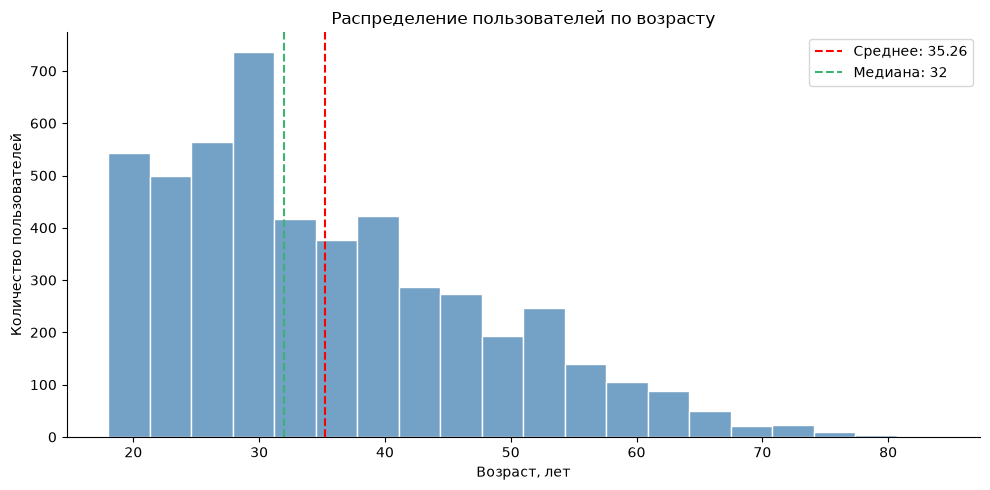

In [19]:
# Проверяем количество уникальных значений возраста
print('Количество уникальных возрастов:', df['age'].nunique())

# Проверяем границы и наиболее часто встречающиеся значения
print('\nНаиболее распространённые возраста:')
display(df['age'].value_counts().head(10).to_frame('count'))

# Строим гистограмму распределения возраста
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    color='steelblue',
    edgecolor='white',
    ax=ax
)

# Отмечаем средний и медианный возраст
ax.axvline(
    df['age'].mean(),
    color='red',
    linestyle='--',
    label=f"Среднее: {df['age'].mean():.2f}"
)

ax.axvline(
    df['age'].median(),
    color='mediumseagreen',
    linestyle='--',
    label=f"Медиана: {df['age'].median():.0f}"
)

ax.set(
    title='Распределение пользователей по возрасту',
    xlabel='Возраст, лет',
    ylabel='Количество пользователей'
)

ax.legend()
sns.despine()
plt.tight_layout()

# Сохраняем график
fig.savefig(
    FIGURES_DIR / 'age_distribution.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

In [20]:
# Рассчитываем количество и долю пользователей по полу
print('Распределение пользователей по полу:')
gender_distribution = pd.DataFrame({
    'count': df['gender'].value_counts(),
    'share_pct': df['gender'].value_counts(normalize=True) * 100
})

display(gender_distribution.round(2))

Распределение пользователей по полу:


,count,share_pct
gender,,
Male,2440,48.80
Female,2440,48.80
Other,120,2.40


In [21]:
# Проверяем фактические значения категорий пола
print('Уникальные значения gender:')
print(df['gender'].unique())

# Проверяем распределение пола по возрастным группам
age_groups = pd.cut(
    df['age'],
    bins=[17, 24, 34, 44, 54, 64, np.inf],
    labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65+']
)

print('\nРаспределение пола по возрастным группам:')
display(
    pd.crosstab(
        age_groups,
        df['gender'],
        margins=True
    )
)

# Проверяем распределение пола по месяцам
print('\nРаспределение пола по месяцам:')
display(
    pd.crosstab(
        df['date'].dt.to_period('M'),
        df['gender'],
        margins=True
    )
)

Уникальные значения gender:
<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

Распределение пола по возрастным группам:


gender,Female,Male,Other,All
age,,,,
18–24,512,506,26,1044
25–34,821,854,43,1718
35–44,526,536,24,1086
45–54,352,352,11,715
55–64,169,148,14,331
65+,60,44,2,106
All,2440,2440,120,5000



Распределение пола по месяцам:


gender,Female,Male,Other,All
date,,,,
2025-01,421,444,29,894
2025-02,403,353,8,764
2025-03,410,408,24,842
2025-04,404,429,17,850
2025-05,418,421,27,866
2025-06,384,385,15,784
All,2440,2440,120,5000


**Распределение по месяцам**

С января по июнь 2025 года количество наблюдений составляет от 764 до 894 в месяц. Резких провалов нет, данные представлены за все шесть месяцев.

При этом месяцы различаются по продолжительности, поэтому для более точного сравнения активности пользователей лучше использовать среднее количество посещений в день.

**Возраст пользователей**

Возраст пользователей — от 18 до 84 лет. Средний возраст составляет 35,26 года, медианный — 32 года.

По гистограмме видно, что основная часть аудитории — молодые пользователи. Больше всего наблюдений приходится на возраст примерно до 35 лет, а дальше их количество постепенно снижается.

Средний возраст немного выше медианного, поскольку в выборке присутствуют и пользователи старших возрастов. Самый распространённый отдельный возраст — 18 лет (236 пользователей).

**Распределение по полу**

Мужчин и женщин в датасете одинаковое количество — по 2 440 человек (48,8%). Ещё 120 пользователей (2,4%) относятся к категории `Other`, которой не было в исходном описании данных.

Точное совпадение количества мужчин и женщин выглядит необычно, поэтому мы дополнительно проверили распределение по возрастным группам и месяцам. Внутри этих групп численность различается, то есть полного совпадения во всех разрезах нет.

Все три категории оставляем без изменений: оснований считать `Other` ошибкой нет.

**Вывод**

Основная часть аудитории — пользователи молодого и среднего возраста. Данные представлены за все шесть месяцев, а распределение по полу в целом сбалансировано.

При дальнейшем анализе важно учитывать, что возрастные группы представлены неравномерно, а в `gender` есть дополнительная категория `Other`.

#### Распределение пользователей по регионам и источникам трафика

In [22]:
# Проверяем уникальные значения регионов и источников трафика
for column in ['region', 'traffic_source']:
    print(f'\nПризнак: {column}')
    print('Количество уникальных категорий:', df[column].nunique())
    print('Уникальные значения:', df[column].unique().tolist())

    # Рассчитываем абсолютные и относительные частоты
    distribution = pd.DataFrame({
        'count': df[column].value_counts(),
        'share_pct': df[column].value_counts(normalize=True) * 100
    })

    display(distribution.round(2))


Признак: region
Количество уникальных категорий: 4
Уникальные значения: ['South', 'North', 'East', 'West']


,count,share_pct
region,,
East,1579,31.58
South,1235,24.70
North,1175,23.50
West,1011,20.22



Признак: traffic_source
Количество уникальных категорий: 4
Уникальные значения: ['Organic', 'PaidAds', 'Referral', 'Email']


,count,share_pct
traffic_source,,
Organic,2199,43.98
PaidAds,1551,31.02
Email,737,14.74
Referral,513,10.26


В датасете представлены четыре региона: `East`, `South`, `North`, `West`. Наибольшая доля пользователей приходится на East (31,58%), наименьшая — на West (20,22%).

Среди источников трафика преобладает Organic (43,98%), за ним следует PaidAds (31,02%). На Email и Referral приходится 14,74% и 10,26% соответственно.

Фактические категории `traffic_source` отличаются от перечисленных в описании задания. В анализе используются исходные значения датасета без переименования.

Распределения по регионам и источникам трафика неравномерны. Это следует учитывать при сравнении абсолютных показателей между группами.

#### Распределение наблюдений по рекламным кампаниям

In [23]:
# Выделяем наблюдения с указанной рекламной кампанией
campaign_data = df[df['campaign'].notna()]

# Проверяем количество и названия кампаний
print('Количество рекламных кампаний:', campaign_data['campaign'].nunique())
print('Уникальные кампании:', campaign_data['campaign'].unique().tolist())

# Рассчитываем количество и долю наблюдений по кампаниям
campaign_distribution = pd.DataFrame({
    'count': campaign_data['campaign'].value_counts(),
    'share_pct': campaign_data['campaign'].value_counts(normalize=True) * 100
})

display(campaign_distribution.round(2))

Количество рекламных кампаний: 7
Уникальные кампании: ['CAMP3', 'CAMP5', 'CAMP2', 'CAMP4', 'CAMP6', 'CAMP7', 'CAMP1']


,count,share_pct
campaign,,
CAMP2,256,16.51
CAMP1,223,14.38
CAMP4,221,14.25
CAMP7,219,14.12
CAMP5,215,13.86
CAMP3,212,13.67
CAMP6,205,13.22


В датасете представлены семь рекламных кампаний (`CAMP1`–`CAMP7`), относящихся к источнику PaidAds.

Распределение наблюдений между кампаниями относительно равномерное: от 205 пользователей (13,22%) для `CAMP6` до 256 пользователей (16,51%) для `CAMP2`.

Существенного преобладания одной кампании по объёму привлечённого трафика не наблюдается. Однако количество пользователей само по себе не характеризует эффективность кампаний — для этого необходимо учитывать конверсию и показатели покупок.

#### Конверсия и количество товаров

In [24]:
# Рассчитываем общую конверсию
print('Распределение converted:')
display(
    pd.DataFrame({
        'count': df['converted'].value_counts().sort_index(),
        'share_pct': (
            df['converted'].value_counts(normalize=True).sort_index() * 100
        )
    }).round(2)
)

# Проверяем распределение количества товаров среди покупателей
print('\nКоличество товаров в заказах:')
display(
    df.loc[df['converted'] == 1, 'num_items']
    .value_counts()
    .sort_index()
    .to_frame(name='count')
)

# Проверяем согласованность количества товаров с фактом покупки
print('\nСогласованность converted и num_items:')
display(
    pd.crosstab(
        df['converted'],
        df['num_items'].eq(0),
        margins=True
    )
)

Распределение converted:


,count,share_pct
converted,,
0,3180,63.60
1,1820,36.40



Количество товаров в заказах:


,count
num_items,
1,233
2,521
3,477
4,338
5,162
6,63
7,19
8,5
9,2



Согласованность converted и num_items:


num_items,False,True,All
converted,,,
0,0,3180,3180
1,1820,0,1820
All,1820,3180,5000


In [25]:
# Проверяем количество товаров у посетителей без покупки
print(
    'Без покупки, но num_items > 0:',
    ((df['converted'] == 0) & (df['num_items'] > 0)).sum()
)

# Проверяем отсутствие товаров у покупателей
print(
    'Покупка совершена, но num_items == 0:',
    ((df['converted'] == 1) & (df['num_items'] == 0)).sum()
)

# Проверяем отрицательные значения количества товаров
print(
    'Отрицательное количество товаров:',
    (df['num_items'] < 0).sum()
)

Без покупки, но num_items > 0: 0
Покупка совершена, но num_items == 0: 0
Отрицательное количество товаров: 0



Покупку совершили 1 820 пользователей из 5 000. Общая конверсия составляет **36,40%**.

Среди покупателей наиболее распространены заказы из 2 товаров (521 заказ) и 3 товаров (477 заказов). Заказы из 7–9 товаров встречаются редко.

Проверка согласованности `converted` и `num_items` не выявила противоречий: у всех покупателей количество товаров положительное, у посетителей без покупки равно нулю. Отрицательных значений нет.

**Общий вывод**

Дополнительный обзор позволил описать структуру аудитории, источники привлечения и покупательскую активность, а также выявить расхождения между фактическими категориями и описанием датасета.

Критических проблем качества данных в рассмотренных переменных не обнаружено. Различия в численности региональных и маркетинговых групп необходимо учитывать при дальнейшем сравнении показателей.

Полученные результаты формируют контекст для последующего статистического анализа конверсии и покупок, но сами по себе не позволяют судить об эффективности отдельных сегментов.

### A.3. Описательная статистика ключевых переменных

**Задача:** исследовать распределения ключевых количественных показателей, оценить их центральные значения и степень разброса.

Для анализа выбраны пять переменных:

| Переменная | Показатель |
|---|---|
| `purchase_amount` | Сумма покупки |
| `time_on_site_s` | Время на сайте, секунды |
| `pages_visited` | Количество просмотренных страниц |
| `delivery_time_days` | Срок доставки, дни |
| `satisfaction` | Оценка удовлетворённости покупкой |

Для каждой переменной рассчитываются среднее арифметическое, медиана, выборочная дисперсия и коэффициент вариации.

Коэффициент вариации характеризует относительный разброс значений:

$$
CV = \frac{s}{\bar{x}} \times 100\%
$$

где:

- $s$ — выборочное стандартное отклонение;
- $\bar{x}$ — выборочное среднее.

**Особенности расчётов:**

- `purchase_amount` анализируется по всем пользователям, включая тех, кто не совершил покупку. Дополнительно рассчитываются показатели только среди покупателей, чтобы отличать среднюю выручку на пользователя от среднего чека.
- `delivery_time_days` первоначально анализируется по всем наблюдениям, включая нулевые значения у пользователей без покупки. Затем срок доставки рассчитывается отдельно среди покупателей. Для `satisfaction` используются только имеющиеся оценки.
- `satisfaction` является порядковой переменной. Среднее и дисперсия для неё рассчитываются в рамках задания, но интерпретируются с осторожностью; медиана и распределение оценок лучше отражают особенности порядковой шкалы.

In [26]:
# Ключевые переменные для описательной статистики
variables = [
    'purchase_amount',
    'time_on_site_s',
    'pages_visited',
    'delivery_time_days',
    'satisfaction'
]

# Рассчитываем основные характеристики распределений
descriptive_stats = pd.DataFrame({
    'count': df[variables].count(),
    'mean': df[variables].mean(),
    'median': df[variables].median(),
    'variance': df[variables].var(),
    'std': df[variables].std(),
    'min': df[variables].min(),
    'max': df[variables].max(),
})

# Коэффициент вариации: стандартное отклонение / среднее × 100%
descriptive_stats['cv_pct'] = (
    descriptive_stats['std'] / descriptive_stats['mean'] * 100
)

display(descriptive_stats.round(2))

,count,mean,median,variance,std,min,max,cv_pct
purchase_amount,5000,34.93,0.00,7615.05,87.26,0.00,1419.30,249.84
time_on_site_s,5000,361.87,305.45,65282.46,255.50,1.00,2235.30,70.61
pages_visited,5000,5.99,6.00,5.06,2.25,1.00,18.00,37.58
delivery_time_days,5000,2.87,0.00,20.93,4.57,0.00,15.00,159.30
satisfaction,1820,4.10,4.00,0.41,0.64,2.00,5.00,15.73


#### Первичный анализ описательных статистик

На первом этапе характеристики рассчитаны по исходному датасету без предварительного исключения наблюдений. Для `satisfaction` расчёты выполнены по имеющимся оценкам.

Первичные результаты выявили несколько особенностей:

- **`purchase_amount`** — среднее составляет 34,93, медиана равна 0, коэффициент вариации — 249,84%. Такое сочетание указывает на большое количество нулевых значений и высокую неоднородность распределения.
- **`time_on_site_s`** — среднее время составляет 361,87 секунды, медиана — 305,45 секунды. Дисперсия равна 65 282,46 секунды², а коэффициент вариации — 70,61%, что свидетельствует о значительном разбросе продолжительности посещений.
- **`pages_visited`** — среднее составляет 5,99 страницы, медиана — 6, коэффициент вариации — 37,58%. Среднее и медиана практически совпадают.
- **`delivery_time_days`** — среднее составляет 2,87 дня, медиана равна 0, коэффициент вариации — 159,30%. Нулевая медиана требует дополнительной проверки состава наблюдений.
- **`satisfaction`** — средняя оценка составляет 4,10, медиана — 4, коэффициент вариации — 15,73%. Относительный разброс оценок невелик по сравнению с остальными показателями, хотя для порядковой шкалы такая характеристика имеет ограниченную интерпретацию.

**Промежуточный вывод:** нулевые медианы purchase_amount и delivery_time_days объясняются структурой исходной совокупности: 3 180 пользователей (63,60%) не совершили покупку, поэтому сумма покупки и срок доставки у них равны нулю.

Таким образом, первоначальные статистики отражают характеристики всей совокупности пользователей, но не позволяют отдельно оценить распределение фактических сумм покупок и сроков доставки.

Для более содержательной интерпретации этих показателей далее проведём дополнительный расчёт только среди пользователей, совершивших покупку (converted = 1).

In [27]:
# Выделяем пользователей, совершивших покупку
buyers = df.loc[df['converted'] == 1]

# Формируем данные для анализа каждого показателя
analysis_data = {
    'purchase_amount': buyers['purchase_amount'],
    'time_on_site_s': df['time_on_site_s'],
    'pages_visited': df['pages_visited'],
    'delivery_time_days': buyers['delivery_time_days'],
    'satisfaction': buyers['satisfaction'].dropna()
}

# Рассчитываем описательные статистики
refined_descriptive_stats = pd.DataFrame({
    variable: {
        'count': data.count(),
        'mean': data.mean(),
        'median': data.median(),
        'variance': data.var(),
        'std': data.std(),
        'cv_pct': data.std() / data.mean() * 100,
        'min': data.min(),
        'max': data.max(),
    }
    for variable, data in analysis_data.items()
}).T

display(refined_descriptive_stats.round(2))

,count,mean,median,variance,std,cv_pct,min,max
purchase_amount,1820.00,95.96,52.88,15068.63,122.75,127.93,1.07,1419.30
time_on_site_s,5000.00,361.87,305.45,65282.46,255.50,70.61,1.00,2235.30
pages_visited,5000.00,5.99,6.00,5.06,2.25,37.58,1.00,18.00
delivery_time_days,1820.00,7.89,8.00,17.91,4.23,53.63,1.00,15.00
satisfaction,1820.00,4.10,4.00,0.41,0.64,15.73,2.00,5.00


#### Результаты уточнённого анализа

После исключения пользователей без покупки из расчётов `purchase_amount` и `delivery_time_days` получены следующие результаты.

**1. Сумма покупки (`purchase_amount`)**

- Среднее увеличилось с 34,93 (средняя выручка на пользователя с учетом тех6 кто ничего не купил) до 95,96 (средний чек среди совершивших покупку).
- Медиана изменилась с 0 до 52,88.
- Коэффициент вариации снизился с 249,84% до 127,93%.

Среднее заметно превышает медиану, что указывает на правостороннюю асимметрию распределения: относительно крупные покупки повышают среднее значение. Высокий коэффициент вариации свидетельствует о существенной неоднородности сумм покупок даже среди покупателей.

**2. Срок доставки (`delivery_time_days`)**

- Среднее увеличилось с 2,87 до 7,89 дня.
- Медиана изменилась с 0 до 8 дней.
- Коэффициент вариации снизился со 159,30% до 53,63%.

После исключения пользователей без покупки среднее и медиана практически совпадают. Близость этих значений не указывает на выраженную асимметрию, однако окончательный вывод о форме распределения можно сделать после изучения гистограммы.

**3. Остальные показатели**

Статистики `time_on_site_s`, `pages_visited` и `satisfaction` не изменились, поскольку состав наблюдений для этих переменных остался прежним.

**Вывод:** уточнение выборки позволило разделить показатели эффективности привлечения пользователей и характеристики фактических заказов. Средняя сумма покупки среди покупателей составляет 95,96, медианная — 52,88. Средний срок доставки составляет 7,89 дня, медианный — 8 дней.

При этом суммы покупок характеризуются значительно большей относительной вариативностью (CV = 127,93%), чем сроки доставки (CV = 53,63%).

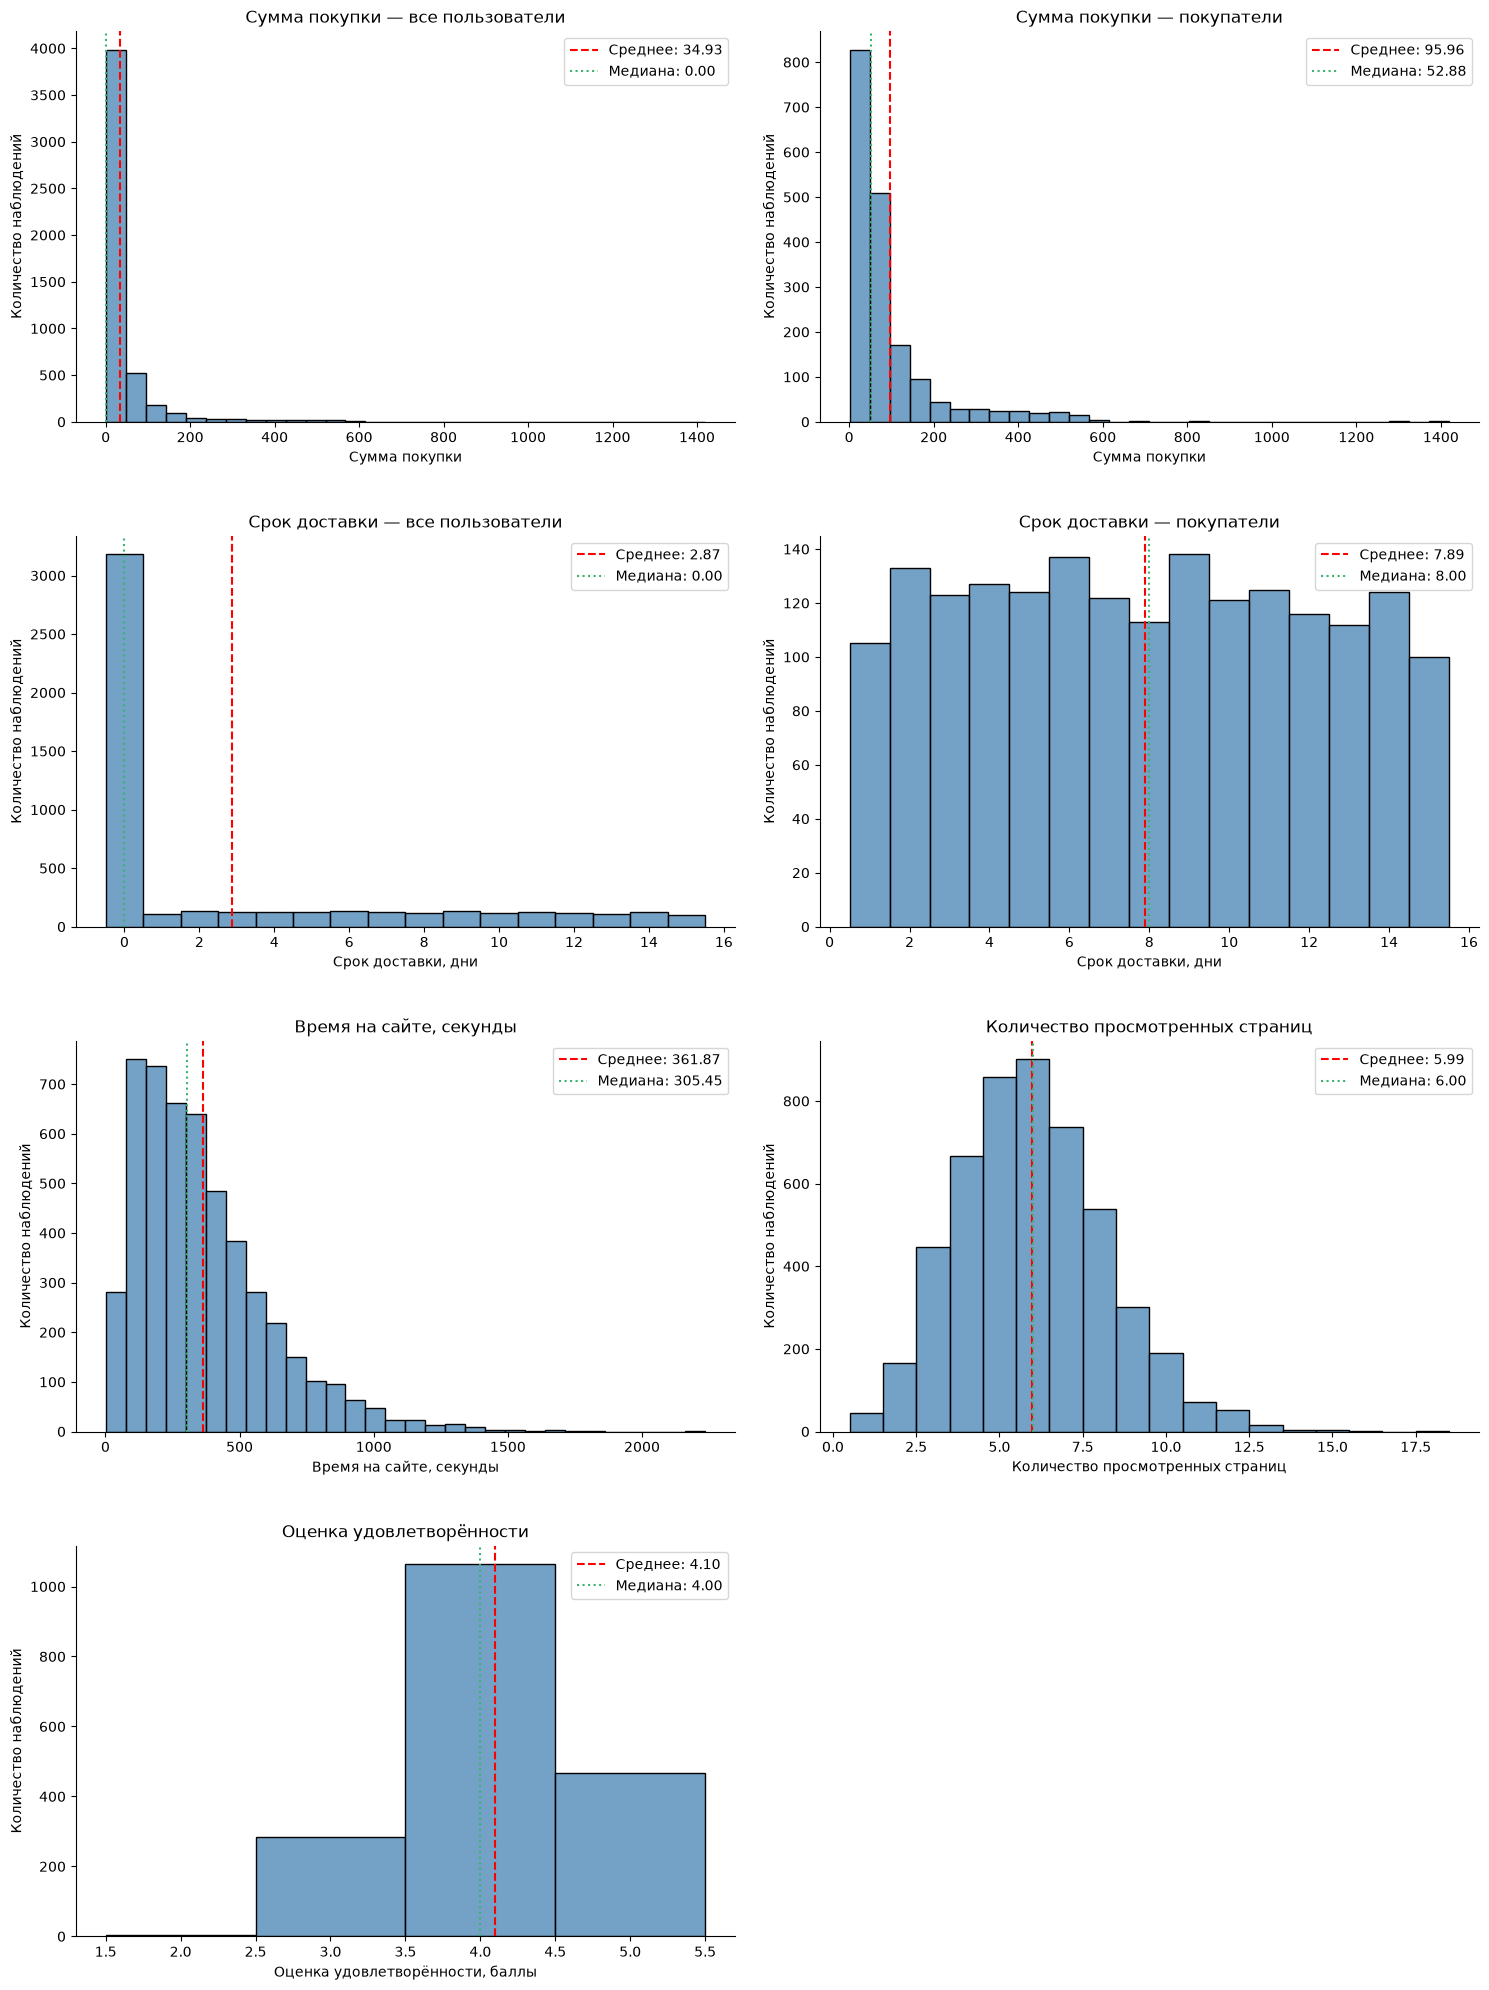

In [28]:
# Данные и названия графиков в порядке отображения
plot_data = [
    ('purchase_amount_all', df['purchase_amount'], 'Сумма покупки — все пользователи'),
    ('purchase_amount_buyers', buyers['purchase_amount'], 'Сумма покупки — покупатели'),
    ('delivery_time_days_all', df['delivery_time_days'], 'Срок доставки — все пользователи'),
    ('delivery_time_days_buyers', buyers['delivery_time_days'], 'Срок доставки — покупатели'),
    ('time_on_site_s', df['time_on_site_s'], 'Время на сайте, секунды'),
    ('pages_visited', df['pages_visited'], 'Количество просмотренных страниц'),
    ('satisfaction', buyers['satisfaction'], 'Оценка удовлетворённости')
]

# Подписи осей X для гистограмм
axis_labels = {
    'purchase_amount': 'Сумма покупки',
    'delivery_time_days': 'Срок доставки, дни',
    'time_on_site_s': 'Время на сайте, секунды',
    'pages_visited': 'Количество просмотренных страниц',
    'satisfaction': 'Оценка удовлетворённости, баллы'
}

# Создаём общую сетку графиков
fig, axes = plt.subplots(4, 2, figsize=(15, 20))
axes = axes.flatten()

for ax, (name, data, title) in zip(axes, plot_data):
    data = data.dropna()

    # Для дискретных переменных задаём интервалы по целым значениям
    if name.startswith(('delivery_time_days', 'pages_visited', 'satisfaction')):
        bins = np.arange(data.min() - 0.5, data.max() + 1.5)
    else:
        bins = 30

    # Строим гистограмму в общей сетке
    sns.histplot(data, bins=bins, ax=ax, color='steelblue')

    ax.axvline(
        data.mean(),
        color='red',
        linestyle='--',
        label=f'Среднее: {data.mean():.2f}'
    )

    ax.axvline(
        data.median(),
        color='mediumseagreen',
        linestyle=':',
        label=f'Медиана: {data.median():.2f}'
    )

    ax.set(
        title=title,
        xlabel=axis_labels[name.replace('_all', '').replace('_buyers', '')],
        ylabel='Количество наблюдений'
    )

    ax.legend()

    # Создаём отдельный график для сохранения
    single_fig, single_ax = plt.subplots(figsize=(9, 5))

    sns.histplot(data, bins=bins, ax=single_ax, color='steelblue')

    single_ax.axvline(
        data.mean(),
        color='red',
        linestyle='--',
        label=f'Среднее: {data.mean():.2f}'
    )

    single_ax.axvline(
        data.median(),
        color='mediumseagreen',
        linestyle=':',
        label=f'Медиана: {data.median():.2f}'
    )

    single_ax.set(
        title=title,
        xlabel=axis_labels[name.replace('_all', '').replace('_buyers', '')],
        ylabel='Количество наблюдений'
    )

    single_ax.legend()
    sns.despine(ax=single_ax)
    single_fig.tight_layout()

    # Сохраняем отдельную гистограмму
    single_fig.savefig(
        FIGURES_DIR / f'{name}.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.close(single_fig)

# Удаляем пустую область в общей сетке
fig.delaxes(axes[-1])

sns.despine(fig=fig)
fig.tight_layout(h_pad=3.5, w_pad=2.0)

# Сохраняем общую сетку гистограмм
fig.savefig(
    FIGURES_DIR / 'descriptive_histograms.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

#### Анализ распределений и итоговые выводы A.3

**1. Сумма покупки (`purchase_amount`)**

У 63,6% пользователей покупок не было, поэтому в общем распределении преобладают нулевые значения.

Если рассматривать только покупателей, большинство покупок приходится на небольшие суммы, но встречаются и значительно более крупные. Из-за этого распределение имеет длинный правый хвост, а среднее (95,96) заметно выше медианы (52,88).

Суммы покупок сильно различаются (CV = 127,93%), поэтому медиана лучше отражает размер типичной покупки.

**2. Срок доставки (`delivery_time_days`)**

Нулевые значения в общем распределении относятся к пользователям, которые ничего не купили.

Среди покупателей сроки доставки распределены достаточно равномерно — от 1 до 15 дней. Среднее составляет 7,89 дня, медиана — 8 дней. Выраженного перекоса в сторону коротких или длительных сроков не наблюдается.

**3. Время на сайте (`time_on_site_s`)**

Большинство пользователей проводят на сайте сравнительно немного времени, но встречаются и очень длительные посещения.

Поэтому среднее время (361,87 секунды) выше медианы (305,45 секунды). Продолжительность посещений заметно различается между пользователями (CV = 70,61%).

**4. Количество просмотренных страниц (`pages_visited`)**

Распределение близко к симметричному, с одним выраженным пиком.

В среднем пользователи просматривают около 6 страниц, медиана также равна 6. Разброс здесь меньше, чем у времени на сайте (CV = 37,58%).

**5. Удовлетворённость (`satisfaction`)**

Покупатели чаще всего оценивают свою удовлетворённость в 4 балла. Средняя оценка составляет 4,10, медиана — 4.

Поскольку оценки представлены порядковой шкалой, для их анализа важнее медиана и распределение ответов.

#### Общий вывод

Наибольший разброс наблюдается в суммах покупок. Время на сайте тоже сильно различается между пользователями, тогда как количество просмотренных страниц распределено более равномерно.

Для суммы покупки и срока доставки важно разделять всех пользователей и тех, кто совершил покупку. Иначе большое количество нулей искажает представление о типичном заказе.

Эти особенности распределений будем учитывать при дальнейшем статистическом анализе.

## B. Формирование выборок

### B.1. Методы формирования выборок

**Задача:** сформировать три выборки по 800 пользователей и сравнить их с исходными данными.

Используем три способа отбора:

1. **Простая случайная выборка** — случайно выбираем 800 пользователей без повторений.
2. **Стратифицированная выборка** — делим пользователей по регионам и случайно отбираем из каждого региона количество, соответствующее его доле в датасете.
3. **Систематическая выборка** — сначала случайно перемешиваем данные, затем выбираем начальную позицию и берём каждого шестого пользователя.

Шаг систематической выборки рассчитывается по формуле:

$$
k = \left\lfloor \frac{N}{n} \right\rfloor
$$

где $N$ — общее количество пользователей, $n$ — размер выборки. В нашем случае $k = 6$.

Для воспроизводимости результатов используем `RANDOM_STATE = 42`.

Все три выборки формируются без повторного отбора одного пользователя внутри каждой выборки.

In [29]:
# Параметры выборочного исследования
N = len(df)
sample_size = 800
step = N // sample_size

print(f'Размер генеральной совокупности: {N}')
print(f'Размер каждой выборки: {sample_size}')
print(f'Шаг систематической выборки: {step}')

# Распределение пользователей по регионам
region_distribution = df['region'].value_counts().sort_index()

region_stats = pd.DataFrame({
    'population_count': region_distribution,
    'population_pct': region_distribution / N * 100,
    'expected_sample_count': region_distribution / N * sample_size
})

display(region_stats.round(2))

Размер генеральной совокупности: 5000
Размер каждой выборки: 800
Шаг систематической выборки: 6


,population_count,population_pct,expected_sample_count
region,,,
East,1579,31.58,252.64
North,1175,23.50,188.00
South,1235,24.70,197.60
West,1011,20.22,161.76


In [30]:
# 1. Простая случайная выборка без возвращения
sample_random = df.sample(
    n=sample_size,
    replace=False,
    random_state=RANDOM_STATE
)

# 2. Пропорциональная стратифицированная выборка по регионам
quotas = region_distribution / N * sample_size

# Сначала берём целые части квот
region_counts = np.floor(quotas).astype(int)

# Оставшиеся места распределяем по наибольшим дробным остаткам
remaining = sample_size - region_counts.sum()

for region in (quotas - region_counts).sort_values(
    ascending=False
).head(remaining).index:
    region_counts.loc[region] += 1

# Случайный отбор внутри каждого региона
sample_stratified = pd.concat([
    df.loc[df['region'] == region].sample(
        n=count,
        replace=False,
        random_state=RANDOM_STATE
    )
    for region, count in region_counts.items()
])

# 3. Систематическая выборка с шагом floor(N / n)
# Перемешиваем строки, чтобы избежать зависимости от исходного порядка
df_shuffled = df.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

# Случайная стартовая позиция от 0 до step - 1
start = rng.integers(0, step)

# Берём ровно 800 наблюдений с заданным шагом
positions = start + np.arange(sample_size) * step
sample_systematic = df_shuffled.iloc[positions]

# Проверяем размеры выборок
samples = {
    'Простая случайная': sample_random,
    'Стратифицированная': sample_stratified,
    'Систематическая': sample_systematic
}

sample_sizes = pd.DataFrame({
    'size': {name: len(data) for name, data in samples.items()},
    'unique_customers': {
        name: data['customer_id'].nunique()
        for name, data in samples.items()
    }
})

print(f'Начальная позиция систематической выборки: {start}')
display(sample_sizes)

Начальная позиция систематической выборки: 0


,size,unique_customers
Простая случайная,800,800
Стратифицированная,800,800
Систематическая,800,800


Из генеральной совокупности объёмом 5000 наблюдений сформированы три выборки по 800 пользователей каждая.

Проверка показала, что каждая выборка содержит ровно 800 наблюдений и 800 уникальных идентификаторов пользователей. Следовательно, повторяющихся пользователей внутри выборок нет.

Таким образом, все три выборки успешно сформированы и могут использоваться для сравнения статистических характеристик с генеральной совокупностью.

### B.2. Сравнение статистических характеристик выборок

**Задача:** оценить, насколько показатели трёх выборок близки к показателям генеральной совокупности.

Для генеральной совокупности и трёх выборок рассчитаем:

- среднюю сумму покупки на пользователя (`mean_purchase`);
- стандартное отклонение суммы покупки (`std_purchase`);
- медиану суммы покупки (`median_purchase`);
- конверсию (`conversion_pct`).

Поскольку сумма покупки равна нулю для пользователей без покупки, дополнительно рассчитаем среднюю и медианную суммы среди покупателей (`converted = 1`).

Сравним полученные значения с генеральной совокупностью и посмотрим, какой метод отбора лучше воспроизвёл её характеристики.

In [31]:
def calculate_sample_stats(data):
    """Рассчитывает основные показатели покупок и конверсии для выборки."""
    purchase_amount = data['purchase_amount']
    buyer_amount = data.loc[
        data['converted'] == 1, 'purchase_amount'
    ]

    return pd.Series({
        'count': len(data),
        'mean_purchase': purchase_amount.mean(),
        'std_purchase': purchase_amount.std(),
        'median_purchase': purchase_amount.median(),
        'conversion_pct': data['converted'].mean() * 100,
        'buyer_mean_purchase': buyer_amount.mean(),
        'buyer_median_purchase': buyer_amount.median()
    })

# Добавляем генеральную совокупность для сравнения
comparison_data = {
    'Генеральная совокупность': df,
    **samples
}

sample_comparison = pd.DataFrame({
    name: calculate_sample_stats(data)
    for name, data in comparison_data.items()
}).T

display(sample_comparison.round(2))

,count,mean_purchase,std_purchase,median_purchase,conversion_pct,buyer_mean_purchase,buyer_median_purchase
Генеральная совокупность,5000.00,34.93,87.26,0.00,36.40,95.96,52.88
Простая случайная,800.00,29.78,73.54,0.00,33.88,87.92,46.58
Стратифицированная,800.00,38.38,98.07,0.00,37.50,102.34,53.00
Систематическая,800.00,33.71,81.24,0.00,34.50,97.72,55.40


#### Визуальное сравнение средней суммы покупки

На графике показана средняя сумма покупки на пользователя для каждой выборки. Красная пунктирная линия обозначает значение генеральной совокупности — 34,93.

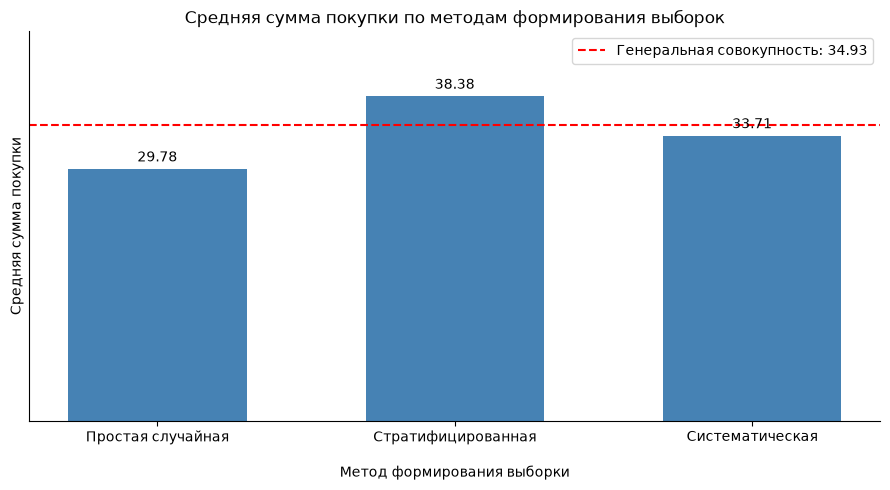

In [32]:
# Средняя сумма покупки в генеральной совокупности
population_mean = sample_comparison.loc[
    'Генеральная совокупность', 'mean_purchase'
]

# Средние значения трёх выборок
sample_means = sample_comparison.drop(
    index='Генеральная совокупность'
)['mean_purchase']

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sample_means.index,
    sample_means.values,
    color='steelblue',
    width=0.6
)

# Среднее генеральной совокупности
ax.axhline(
    population_mean,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Генеральная совокупность: {population_mean:.2f}'
)

# Подписи значений над столбцами
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{bar.get_height():.2f}',
        ha='center',
        va='bottom'
    )

ax.set(
    title='Средняя сумма покупки по методам формирования выборок',
    xlabel='Метод формирования выборки',
    ylabel='Средняя сумма покупки'
)

ax.set_ylim(0, sample_means.max() * 1.2)
ax.grid(False)
ax.set_yticks([])
ax.xaxis.labelpad = 15
ax.legend()

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'sample_mean_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

### Сравнение выборок с генеральной совокупностью

Для каждой из трёх выборок рассчитаны среднее значение `purchase_amount`, стандартное отклонение, медиана и конверсия. Дополнительно определены средняя и медианная суммы покупки среди пользователей с `converted = 1`.

**Простая случайная выборка**

Средняя сумма на пользователя составила 29,78 против 34,93 в генеральной совокупности. Конверсия также оказалась ниже — 33,88% против 36,40%.

Средняя сумма среди покупателей составила 87,92, медиана — 46,58. Обе характеристики ниже соответствующих значений генеральной совокупности.

**Стратифицированная выборка**

Средняя сумма на пользователя составила 38,38, конверсия — 37,50%. Среди трёх методов эта выборка показала наименьшее отклонение конверсии от генеральной совокупности — 1,10 процентного пункта.

Средняя сумма среди покупателей составила 102,34, а медиана — 53,00. Последняя практически совпадает с медианой генеральной совокупности (52,88).

**Систематическая выборка**

Средняя сумма на пользователя составила 33,71, стандартное отклонение — 81,24. Оба показателя оказались ближе к характеристикам генеральной совокупности, чем в остальных выборках.

Средняя сумма среди покупателей составила 97,72 против 95,96 в генеральной совокупности. Конверсия при этом оказалась ниже — 34,50%.

**Интерпретация медианы**

Медиана `purchase_amount` равна нулю в генеральной совокупности и во всех трёх выборках. Это связано с тем, что доля пользователей без покупки превышает 50%.

Поэтому дополнительно рассчитана медиана среди покупателей. Она позволяет сравнивать типичный размер покупки, не смешивая покупателей и пользователей без покупок.

**Итоговый вывод**

Все три метода обеспечили выборки заданного объёма без повторяющихся пользователей внутри каждой выборки.

В проведённом эксперименте систематическая выборка наиболее близко воспроизвела среднюю сумму на пользователя, стандартное отклонение и среднюю сумму среди покупателей. Стратифицированная выборка оказалась ближе по конверсии и медиане суммы среди покупателей.

Однако близость выборочных статистик к параметрам генеральной совокупности в одном эксперименте не доказывает общего превосходства метода. Для оценки устойчивости результатов потребовались бы повторные выборки.

## C. Количественная репрезентативность

### C.1. Отклонения выборочных средних от генеральной совокупности

**Задача:** сравнить среднюю сумму покупки на пользователя в трёх выборках со средним значением генеральной совокупности.

Для расчетов используем `purchase_amount` по всем пользователям, включая тех, кто не совершил покупку. 

Рассчитаем два показателя:

**Абсолютное отклонение** - разница между выборочным и генеральным средними:

$$
\Delta_{\text{abs}} = \bar{x}_{\text{sample}} - \bar{x}_{\text{population}}
$$

**Относительное отклонение** - та же разница относительно генерального среднего:

$$
\Delta_{\text{rel}} = \frac{\Delta_{\text{abs}}}{\bar{x}_{\text{population}}}
$$

Относительное отклонение также представим в процентах.

Положительное значение означает, что выборочное среднее выше генерального, отрицательное — ниже.

Согласно критерию задания, наиболее репрезентативной по средней сумме покупки считается выборка с минимальным абсолютным значением относительного отклонения по модулю $|\Delta_{\text{rel}}|$.

In [33]:
# Используем средние значения, рассчитанные в B.2
population_mean = sample_comparison.loc[
    'Генеральная совокупность', 'mean_purchase'
]

representativeness = sample_comparison.drop(
    index='Генеральная совокупность'
)[['mean_purchase']].copy()

# Абсолютное отклонение
representativeness['abs_dev'] = (
    representativeness['mean_purchase'] - population_mean
)

# Относительное отклонение
representativeness['rel_dev'] = (
    representativeness['abs_dev'] / population_mean
)

# Относительное отклонение в процентах
representativeness['rel_dev_pct'] = (
    representativeness['rel_dev'] * 100
)

# Модуль относительного отклонения для сравнения
representativeness['abs_rel_dev_pct'] = (
    representativeness['rel_dev_pct'].abs()
)

# Сортируем выборки по возрастанию отклонения
representativeness = representativeness.sort_values(
    'abs_rel_dev_pct'
)

display(representativeness.round(2))

print(
    'Наиболее репрезентативная выборка:',
    representativeness.index[0]
)

,mean_purchase,abs_dev,rel_dev,rel_dev_pct,abs_rel_dev_pct
Систематическая,33.71,-1.22,-0.03,-3.48,3.48
Стратифицированная,38.38,3.45,0.10,9.88,9.88
Простая случайная,29.78,-5.15,-0.15,-14.73,14.73


Наиболее репрезентативная выборка: Систематическая


#### Визуальное сравнение относительных отклонений

Для оценки репрезентативности выборок построим столбчатую диаграмму относительных отклонений средней суммы покупки от значения генеральной совокупности.

Отрицательные значения показывают занижение среднего, положительные — завышение. Чем ближе столбец к нулевой линии, тем точнее выборка воспроизводит среднее генеральной совокупности.

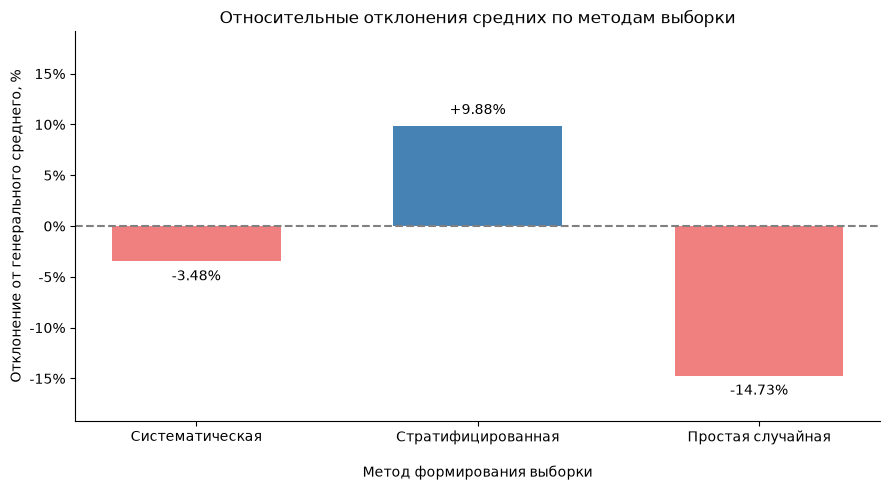

In [34]:
# Относительные отклонения выборочных средних
deviations = representativeness['rel_dev_pct']

# Отрицательные отклонения — красные, положительные — синие
colors = ['lightcoral' if value < 0 else 'steelblue' for value in deviations]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    deviations.index,
    deviations.values,
    color=colors,
    width=0.6
)

# Нулевая линия
ax.axhline(
    0,
    color='gray',
    linestyle='--',
    linewidth=1.5
)

# Подписи отклонений
for bar in bars:
    value = bar.get_height()

    ax.annotate(
        f'{value:+.2f}%',
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6 if value >= 0 else -6),
        textcoords='offset points',
        ha='center',
        va='bottom' if value >= 0 else 'top'
    )

ax.set(
    title='Относительные отклонения средних по методам выборки',
    xlabel='Метод формирования выборки',
    ylabel='Отклонение от генерального среднего, %'
)

ax.xaxis.labelpad = 15

# Симметричная шкала Y
limit = max(abs(deviations.min()), abs(deviations.max())) * 1.3
ax.set_ylim(-limit, limit)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value:g}%')
)

ax.grid(False)
sns.despine()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'relative_deviations.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Систематическая выборка показала наименьшее отклонение средней суммы покупки от генеральной совокупности — **−3,48%**.

Стратифицированная выборка завысила среднее на 9,88%, а простая случайная занизила на 14,73%.

Таким образом, **в данном эксперименте систематическая выборка оказалась наиболее репрезентативной по средней сумме покупки**. Однако этот результат относится к конкретным сформированным выборкам и не означает, что систематический метод всегда лучше остальных.

### C.2. Интерпретация репрезентативности с учетом дисперсии и регионов

**Задача:** дополнить сравнение выборок анализом разброса сумм покупок и проверить, насколько регионы подходят для стратификации.

Для этого сравним дисперсии `purchase_amount` в генеральной совокупности и трёх выборках, а затем рассчитаем средние суммы покупок и дисперсии по регионам.

Дисперсия показывает, насколько сильно различаются суммы покупок. Чем ближе выборочная дисперсия к генеральной, тем точнее выборка воспроизводит разброс значений.

При этом **основным критерием репрезентативности остаётся отклонение среднего**, рассчитанное в C.1.

In [35]:
# Сравнение дисперсий генеральной совокупности и выборок
population_variance = df['purchase_amount'].var()

variance_comparison = pd.DataFrame({
    'variance': {
        'Генеральная совокупность': population_variance,
        **{
            name: data['purchase_amount'].var()
            for name, data in samples.items()
        }
    }
})

variance_comparison['dev_pct'] = (
    (variance_comparison['variance'] - population_variance)
    / population_variance * 100
)

print('Сравнение дисперсий:')
display(variance_comparison.round(2))

# Характеристики суммы покупки внутри регионов
region_purchase_stats = (
    df.groupby('region')['purchase_amount']
    .agg(
        count='count',
        mean='mean',
        variance='var'
    )
)

print('Характеристики purchase_amount по регионам:')
display(region_purchase_stats.round(2))

Сравнение дисперсий:


,variance,dev_pct
Генеральная совокупность,7615.05,0.00
Простая случайная,5408.67,-28.97
Стратифицированная,9617.27,26.29
Систематическая,6600.42,-13.32


Характеристики purchase_amount по регионам:


,count,mean,variance
region,,,
East,1579,36.65,8904.51
North,1175,32.20,6059.63
South,1235,35.66,8579.95
West,1011,34.51,6238.01


**1. Сравнение дисперсий**

Дисперсия суммы покупки в генеральной совокупности составляет 7615,05.

Ближе всего к этому значению оказалась **систематическая выборка**: её дисперсия ниже на 13,32%. Стратифицированная выборка показала отклонение +26,29%, а простая случайная — −28,97%.

Таким образом, систематическая выборка в нашем эксперименте точнее остальных воспроизвела не только среднюю сумму покупки, но и её разброс.

**2. Анализ регионов**

Средние суммы покупок по регионам различаются незначительно — от 32,20 в North до 36,65 в East. При этом внутри каждого региона разброс довольно большой: дисперсия составляет от 6059,63 до 8904,51.

Это говорит о том, что разделение пользователей по регионам не создаёт группы с близкими суммами покупок. Поэтому стратификация по `region` не обязательно повышает точность оценки средней суммы покупки.

### Итоговый вывод по разделу C

**Систематическая выборка оказалась наиболее репрезентативной по средней сумме покупки**: её относительное отклонение составило −3,48%. Она также показала наименьшее отклонение дисперсии — −13,32%.

Стратифицированная выборка сохранила региональные пропорции, но уступила систематической по обоим показателям.

Важно, что мы сравнили только один набор выборок. Поэтому результат показывает, какой метод оказался точнее **в данном эксперименте**, а не какой метод лучше в целом.

## D. Доверительные интервалы

### D.1. Доверительные интервалы для средней суммы покупки

**Задача:** построить 95% доверительные интервалы для средней суммы покупки в трёх выборках и оценить неопределённость полученных оценок. Дополнительно рассчитать интервал для всех 5000 наблюдений, рассматривая их как выборку из более широкой популяции.

Для оценки среднего используем t-распределение Стьюдента, поскольку дисперсия генерального распределения заранее не предполагается известной.

Доверительный интервал рассчитывается по формуле:

$$
CI_{95\%} = \bar{x} \pm t_{0.975,\;n-1} \cdot SE
$$

где:

- $\bar{x}$ — выборочное среднее;
- $t_{0.975,\;n-1}$ — критическое значение t-распределения;
- $SE$ — стандартная ошибка среднего;
- $n$ — количество наблюдений.

Для выборок, сформированных без возвращения из конечной генеральной совокупности, используем поправку:

$$
SE = \frac{s}{\sqrt{n}}\sqrt{\frac{N-n}{N-1}}
$$

Для анализа всех 5000 наблюдений без этой поправки используем стандартную ошибку $s/\sqrt{N}$, рассматривая данные как наблюдения из более широкой популяции.

Поправка на конечную генеральную совокупность точно соответствует простой случайной выборке без возвращения. Для стратифицированной и систематической выборок интервалы рассчитываются приближённо, без полного учёта особенностей отбора.

Расчёты проводятся по всем пользователям, включая пользователей без покупок.

In [36]:
# Доверительные интервалы для среднего purchase_amount
def mean_confidence_interval(data, population_size=None, confidence=0.95):
    values = data['purchase_amount'].dropna()
    n = len(values)

    mean = values.mean()
    std = values.std(ddof=1)  # при расчёте выборочной дисперсии используется деление на n - 1

    # Стандартная ошибка
    se = std / np.sqrt(n)

    # Поправка на конечную генеральную совокупность
    if population_size is not None:
        se *= np.sqrt((population_size - n) / (population_size - 1))

    # Критическое значение t-распределения
    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    # Расчитываем границы интервала
    margin = t_critical * se

    return pd.Series({
        'n': n,
        'mean': mean,
        'se': se,
        'ci_lower': mean - margin,
        'ci_upper': mean + margin
    })


mean_ci = pd.DataFrame({
    name: mean_confidence_interval(
        data,
        population_size=N if name != 'Генеральная совокупность' else None
    )
    for name, data in comparison_data.items()
}).T

display(mean_ci.round(2))

,n,mean,se,ci_lower,ci_upper
Генеральная совокупность,5000.00,34.93,1.23,32.51,37.35
Простая случайная,800.00,29.78,2.38,25.10,34.46
Стратифицированная,800.00,38.38,3.18,32.14,44.62
Систематическая,800.00,33.71,2.63,28.54,38.88


#### Визуализация доверительных интервалов средней суммы покупки

Для сравнения точечных оценок и их неопределённости построим интервальный график.

Точки обозначают среднюю сумму покупки в каждой выборке, горизонтальные отрезки — соответствующие 95% доверительные интервалы. Вертикальная пунктирная линия показывает фактическое среднее генеральной совокупности.

Если интервал пересекает эту линию, значение генерального среднего находится внутри рассчитанного доверительного интервала.

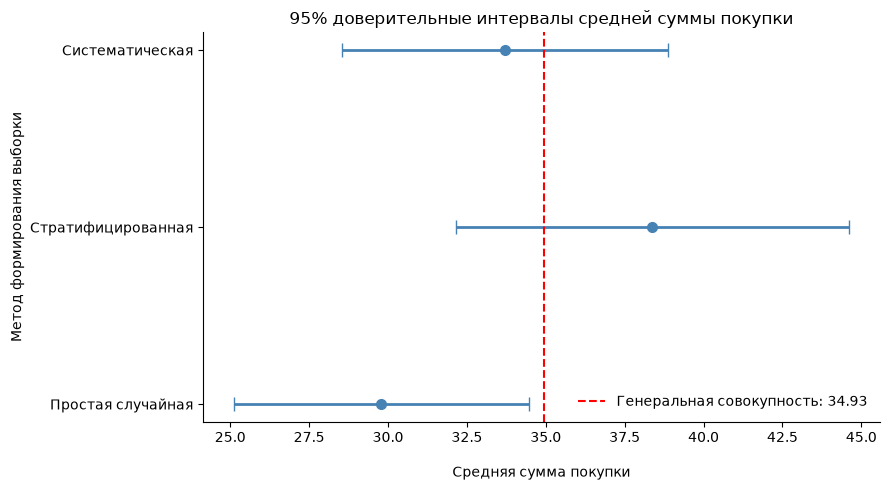

In [37]:
# Доверительные интервалы трёх выборок
plot_data = mean_ci.drop(index='Генеральная совокупность')

means = plot_data['mean']
lower_errors = means - plot_data['ci_lower']
upper_errors = plot_data['ci_upper'] - means

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    means,
    plot_data.index,
    xerr=[lower_errors, upper_errors],
    fmt='o',
    color='steelblue',
    ecolor='steelblue',
    markersize=7,
    capsize=5,
    elinewidth=2
)

# Фактическое среднее генеральной совокупности
population_mean = mean_ci.loc['Генеральная совокупность', 'mean']

ax.axvline(
    population_mean,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Генеральная совокупность: {population_mean:.2f}'
)

ax.set(
    title='95% доверительные интервалы средней суммы покупки',
    xlabel='Средняя сумма покупки',
    ylabel='Метод формирования выборки'
)

ax.xaxis.labelpad = 15
ax.grid(False)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'mean_confidence_intervals.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Для генеральной совокупности и трёх выборок построены 95% доверительные интервалы среднего значения `purchase_amount`.

Для всех 5000 наблюдений, рассматриваемых как выборка из более широкой популяции, получен доверительный интервал [32,51; 37,35] при среднем 34,93.

Для выборок получены следующие результаты:

- **Простая случайная:** [25,10; 34,46], среднее — 29,78.
- **Стратифицированная:** [32,14; 44,62], среднее — 38,38.
- **Систематическая:** [28,54; 38,88], среднее — 33,71.

Интервалы стратифицированной и систематической выборок включают среднее генеральной совокупности (34,93). Интервал простой случайной выборки не включает его, хотя верхняя граница находится достаточно близко.

Наиболее узкий интервал среди трёх выборок получен для простой случайной выборки. Это связано с меньшим наблюдаемым стандартным отклонением `purchase_amount` в данной выборке и не означает более высокой точности её оценки относительно известного генерального среднего.

**Итог:** систематическая выборка, признанная наиболее репрезентативной по критерию относительного отклонения в разделе C, также даёт среднюю оценку, близкую к генеральному значению. Однако ширина её доверительного интервала больше, чем у простой случайной выборки.

Таким образом, близость выборочного среднего к генеральному значению и ширина доверительного интервала отражают разные характеристики: первая показывает фактическое отклонение, вторая — неопределённость оценки.

### D.2. Доверительные интервалы для конверсии

**Цель:** построить 95% доверительные интервалы для доли пользователей, совершивших покупку.

Конверсия определяется как:

$$
\hat{p} = \frac{x}{n}
$$

где $x$ — количество пользователей с `converted = 1`, $n$ — общее количество пользователей.

Для построения интервалов используем метод Уилсона, основанный на нормальной аппроксимации биномиального распределения.

Для трёх выборок используем интервал Уилсона с поправкой на конечную генеральную совокупность. Для стратифицированной и систематической выборок расчёт является приближённым, поскольку не учитывает полностью особенности отбора. Для всей совокупности из 5000 наблюдений также построим обычный интервал Уилсона, рассматривая её как выборку из более широкой популяции.

Результаты представим в процентах.

In [38]:
# Доверительные интервалы для конверсии методом Уилсона
def conversion_confidence_interval(
    data,
    population_size=None,
    confidence=0.95
):
    n = len(data)
    converted_count = data['converted'].sum()
    p = converted_count / n

    z = stats.norm.ppf((1 + confidence) / 2)
    z2 = z ** 2

    # Центр и половина ширины интервала Уилсона
    denominator = 1 + z2 / n
    center = (p + z2 / (2 * n)) / denominator

    # Поправка на конечную генеральную совокупность
    fpc = 1
    if population_size is not None:
        fpc = (population_size - n) / (population_size - 1)

    half_width = (
        z / denominator
        * np.sqrt(p * (1 - p) / n * fpc + z2 / (4 * n ** 2))
    )

    return pd.Series({
        'n': n,
        'converted_count': converted_count,
        'conversion_pct': p * 100,
        'ci_lower_pct': max(0, center - half_width) * 100,
        'ci_upper_pct': min(1, center + half_width) * 100
    })


conversion_ci = pd.DataFrame({
    name: conversion_confidence_interval(
        data,
        population_size=N if name != 'Генеральная совокупность' else None
    )
    for name, data in comparison_data.items()
}).T

display(conversion_ci.round(2))

,n,converted_count,conversion_pct,ci_lower_pct,ci_upper_pct
Генеральная совокупность,5000.00,1820.00,36.40,35.08,37.74
Простая случайная,800.00,271.00,33.88,30.95,36.95
Стратифицированная,800.00,300.00,37.50,34.49,40.63
Систематическая,800.00,276.00,34.50,31.56,37.59


#### Визуализация доверительных интервалов конверсии

Для сравнения оценок конверсии построим интервальный график с 95% доверительными интервалами.

Точки обозначают выборочные значения конверсии, горизонтальные отрезки — границы доверительных интервалов. Вертикальная пунктирная линия показывает фактическую конверсию генеральной совокупности.

График позволяет оценить различия между выборками и определить, включают ли рассчитанные интервалы значение генеральной конверсии.

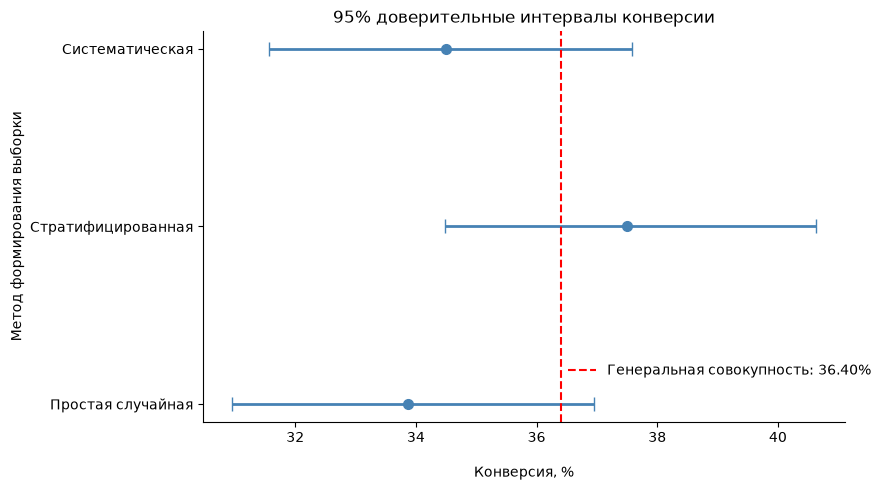

In [39]:
# Доверительные интервалы конверсии трёх выборок
plot_data = conversion_ci.drop(index='Генеральная совокупность')

conversions = plot_data['conversion_pct']
lower_errors = conversions - plot_data['ci_lower_pct']
upper_errors = plot_data['ci_upper_pct'] - conversions

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    conversions,
    plot_data.index,
    xerr=[lower_errors, upper_errors],
    fmt='o',
    color='steelblue',
    ecolor='steelblue',
    markersize=7,
    capsize=5,
    elinewidth=2
)

# Фактическая конверсия генеральной совокупности
population_conversion = conversion_ci.loc[
    'Генеральная совокупность', 'conversion_pct'
]

ax.axvline(
    population_conversion,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Генеральная совокупность: {population_conversion:.2f}%'
)

ax.set(
    title='95% доверительные интервалы конверсии',
    xlabel='Конверсия, %',
    ylabel='Метод формирования выборки'
)

ax.xaxis.labelpad = 15
ax.grid(False)

ax.legend(
    loc='lower right',
    bbox_to_anchor=(1.06, 0.08),
    frameon=False
)

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'conversion_confidence_intervals.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Для генеральной совокупности и трёх выборок построены 95% доверительные интервалы конверсии.

**Общая конверсия** составляет 36,40%. Для всех 5000 наблюдений, рассматриваемых как выборка из более широкой популяции, получен доверительный интервал [35,08%; 37,74%].

Для выборок получены следующие результаты:

- **Простая случайная:** конверсия 33,88%, доверительный интервал [30,95%; 36,95%].
- **Стратифицированная:** конверсия 37,50%, доверительный интервал [34,49%; 40,63%].
- **Систематическая:** конверсия 34,50%, доверительный интервал [31,56%; 37,59%].

Все три выборочных интервала включают значение конверсии генеральной совокупности (36,40%). Следовательно, полученные оценки согласуются с генеральным значением в пределах рассчитанной статистической неопределённости.

Наиболее близкую к генеральной конверсии точечную оценку дала **стратифицированная выборка**: абсолютное отклонение составило 1,10 процентного пункта.

Ширина доверительных интервалов трёх выборок практически одинакова, поскольку объёмы выборок равны, а значения конверсии относительно близки.

**Итог:** стратифицированная выборка наиболее точно воспроизвела конверсию генеральной совокупности по абсолютному отклонению точечной оценки. При этом все три выборки дали доверительные интервалы, содержащие генеральное значение.

*Примечание:* интервалы рассчитаны методом Уилсона с поправкой на конечную генеральную совокупность для трёх выборок. Для стратифицированного и систематического отбора результаты являются приближёнными.

### D.3. Интерпретация результатов

Построенные 95% доверительные интервалы позволяют оценить неопределённость двух показателей: средней суммы покупки (`purchase_amount`) и конверсии, рассчитанных по трём выборкам.

**1. Доверительные интервалы средней суммы покупки**

Среднее значение `purchase_amount` в генеральной совокупности составляет 34,93.

Доверительные интервалы стратифицированной и систематической выборок включают это значение. Интервал простой случайной выборки [25,10; 34,46] не включает генеральное среднее.

При этом систематическая выборка дала наиболее близкую точечную оценку средней суммы покупки — 33,71, что согласуется с результатами раздела C.

**2. Доверительные интервалы конверсии**

Конверсия генеральной совокупности составляет 36,40%.

Доверительные интервалы всех трёх выборок включают генеральное значение. Наиболее близкую точечную оценку конверсии дала стратифицированная выборка — 37,50%.

Таким образом, выборка, наиболее точно воспроизводящая один показатель, необязательно оказывается наиболее точной для другого.

**3. Интерпретация статистической неопределённости**

95% доверительный интервал характеризует неопределённость оценки параметра при принятой модели выборочного исследования. При многократном повторении выборочного исследования около 95% таких интервалов будут содержать истинное значение параметра, если соблюдаются предположения используемого метода.

Попадание генерального значения внутрь интервала свидетельствует о согласованности оценки с этим значением, но само по себе не доказывает репрезентативность выборки.

Ширина интервала зависит от объёма наблюдений, вариативности исследуемого показателя и метода расчёта стандартной ошибки.

**Итоговый вывод по разделу D**

Систематическая выборка наиболее близко воспроизвела среднюю сумму покупки, тогда как стратифицированная выборка дала наиболее близкую оценку конверсии.

Доверительные интервалы показали, что точечные оценки следует рассматривать вместе с их статистической неопределённостью. При этом результаты раздела C о репрезентативности по средней сумме покупки сохраняются: в рамках проведённого эксперимента минимальное относительное отклонение получено для систематической выборки.

Поскольку интервалы для стратифицированной и систематической выборок рассчитаны приближённо, без полного учёта особенностей дизайна отбора, выводы об их сравнительной точности следует интерпретировать с осторожностью.

## E. Центральная предельная теорема и закон больших чисел

### E.1. Исследование распределения выборочных средних

**Задача:** проверить действие центральной предельной теоремы с помощью многократного формирования выборок из генеральной совокупности.

Для этого проведём моделирование:

- Рассмотрим переменную `purchase_amount` для всех пользователей, включая нулевые покупки.
- Для каждого размера выборки $n \in \{5, 30, 100\}$ сформируем 1000 случайных выборок с возвращением.
- Для каждой выборки рассчитаем среднюю сумму покупки.
- Построим гистограммы распределений выборочных средних и Q–Q графики для оценки близости к нормальному распределению.

Согласно центральной предельной теореме, при увеличении размера выборки распределение выборочного среднего приближается к нормальному, если наблюдения независимы и исходное распределение имеет конечную дисперсию.

Для воспроизводимости используем фиксированное начальное состояние генератора случайных чисел. Отбор с возвращением позволяет независимо выбирать наблюдения из имеющихся 5000 значений, в том числе повторно выбирать одного и того же пользователя.

In [40]:
# Параметры моделирования
sample_sizes = [5, 30, 100]
n_simulations = 1000

values = df['purchase_amount'].to_numpy()
population_mean = values.mean()

simulation_rng = np.random.default_rng(RANDOM_STATE)

# Моделирование распределений выборочных средних
sample_means_sim = {
    n: simulation_rng.choice(
        values,
        size=(n_simulations, n),
        replace=True
    ).mean(axis=1)
    for n in sample_sizes
}

# Проверка среднего и медианы выборочных средних
for n, means in sample_means_sim.items():
    print(
        f'n = {n}: '
        f'среднее = {means.mean():.2f}, '
        f'медиана = {np.median(means):.2f}'
    )

print(f'Генеральное среднее = {population_mean:.2f}')

n = 5: среднее = 36.95, медиана = 22.23
n = 30: среднее = 34.89, медиана = 32.34
n = 100: среднее = 35.29, медиана = 34.56
Генеральное среднее = 34.93


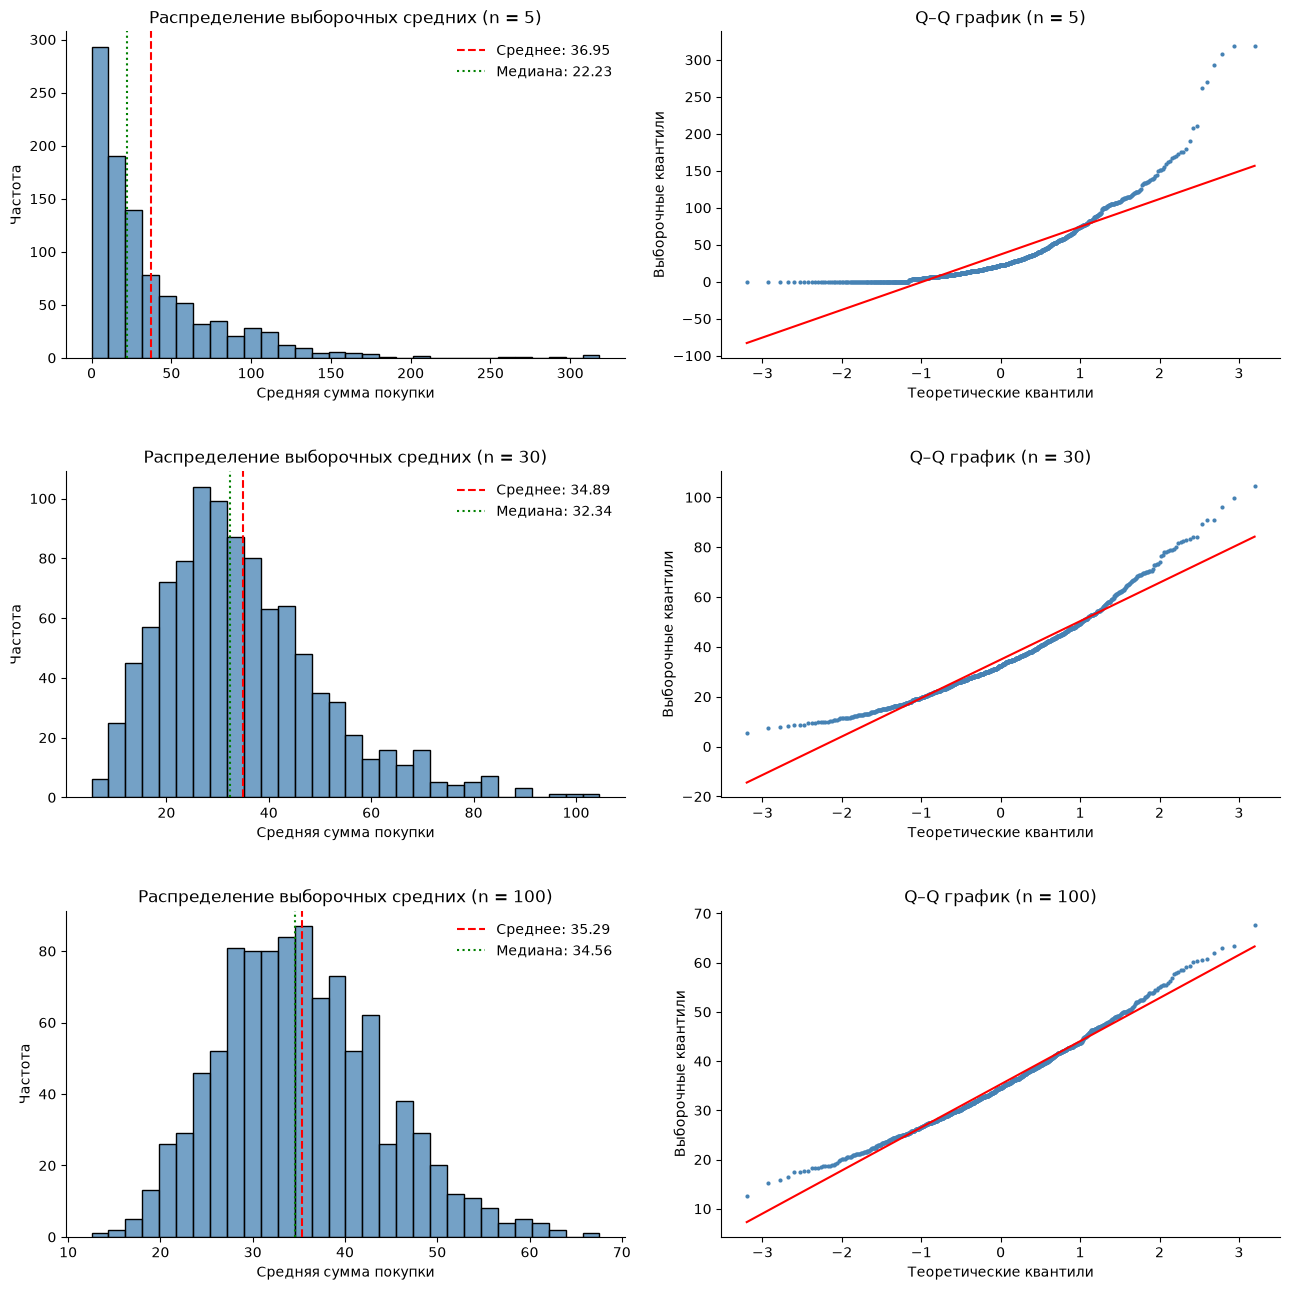

In [41]:
# Гистограммы и Q-Q графики
fig, axes = plt.subplots(3, 2, figsize=(13, 13))

for i, n in enumerate(sample_sizes):
    means = sample_means_sim[n]

    # Гистограмма выборочных средних
    ax_hist = axes[i, 0]

    sns.histplot(
        means,
        bins=30,
        color='steelblue',
        ax=ax_hist
    )

    ax_hist.axvline(
        means.mean(),
        color='red',
        linestyle='--',
        label=f'Среднее: {means.mean():.2f}'
    )

    ax_hist.axvline(
        np.median(means),
        color='green',
        linestyle=':',
        label=f'Медиана: {np.median(means):.2f}'
    )

    ax_hist.set(
        title=f'Распределение выборочных средних (n = {n})',
        xlabel='Средняя сумма покупки',
        ylabel='Частота'
    )

    ax_hist.legend(frameon=False)
    ax_hist.grid(False)

    ax_qq = axes[i, 1]

    stats.probplot(
        means,
        dist='norm',
        plot=ax_qq
    )

    # Настройка точек
    points, line = ax_qq.get_lines()

    points.set_color('steelblue')
    points.set_marker('o')
    points.set_markersize(3)
    points.set_alpha(1)
    points.set_markeredgewidth(0)

    # Теоретическая прямая
    line.set_color('red')
    line.set_linewidth(1.5)

    ax_qq.set(
        title=f'Q–Q график (n = {n})',
        xlabel='Теоретические квантили',
        ylabel='Выборочные квантили'
    )

    ax_qq.grid(False)

sns.despine()
plt.tight_layout(h_pad=3.5, w_pad=2.0)

fig.savefig(
    FIGURES_DIR / 'clt_histograms_qq.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Моделирование 1000 повторных выборок для каждого размера $n = 5,\ 30,\ 100$ продемонстрировало действие центральной предельной теоремы.

- **При $n = 5$** распределение выборочных средних имеет выраженную правостороннюю асимметрию. Среднее составляет 36,95, медиана — 22,23. На Q–Q графике наблюдаются значительные отклонения точек от теоретической прямой нормального распределения.
- **При $n = 30$** распределение становится более симметричным, хотя правый хвост остаётся удлинённым. Среднее составляет 34,89, медиана — 32,34. На Q–Q графике центральная часть точек приближается к прямой, но в хвостах сохраняются отклонения.
- **При $n = 100$** распределение выборочных средних наиболее близко к нормальному. Среднее составляет 35,29, медиана — 34,56. Большинство точек Q–Q графика располагается вдоль теоретической прямой, небольшие отклонения сохраняются преимущественно в хвостах.

Средняя сумма покупки в генеральной совокупности составляет 34,93. При увеличении размера выборки распределение выборочных средних становится более симметричным, а его разброс уменьшается. Средние значения по результатам моделирования остаются близкими к генеральному среднему.

**Таким образом, результаты моделирования согласуются с центральной предельной теоремой:** даже при существенно асимметричном исходном распределении суммы покупки распределение выборочных средних постепенно приближается к нормальному по мере увеличения размера выборки.

### E.2. Изменение дисперсии выборочных средних

**Задача:** численно и графически исследовать, как изменяется дисперсия выборочных средних при увеличении размера выборки.

Для каждого размера выборки $n = 5,\ 30,\ 100$ рассчитаем:

- Эмпирическую дисперсию 1000 выборочных средних, полученных в E.1.
- Теоретическую дисперсию выборочного среднего по формуле $\sigma^2/n$.
- Относительное отклонение эмпирической дисперсии от теоретической.

Сравним полученные значения в таблице и на графике.

Поскольку в моделировании E.1 использовался случайный отбор с возвращением, для теоретического расчёта применяем дисперсию эмпирического распределения генеральной совокупности с `ddof=0`.

In [42]:
# Дисперсия исходного распределения
population_variance = df['purchase_amount'].var(ddof=0)

# Эмпирическая и теоретическая дисперсии выборочных средних
variance_comparison = pd.DataFrame({
    'n': sample_sizes,
    'empirical_variance': [
        np.var(sample_means_sim[n], ddof=1)
        for n in sample_sizes
    ],
    'theoretical_variance': [
        population_variance / n
        for n in sample_sizes
    ]
})

variance_comparison['relative_deviation_pct'] = (
    (
        variance_comparison['empirical_variance']
        - variance_comparison['theoretical_variance']
    )
    / variance_comparison['theoretical_variance']
    * 100
)

display(variance_comparison.round(2))

,n,empirical_variance,theoretical_variance,relative_deviation_pct
0,5,1819.22,1522.71,19.47
1,30,249.32,253.78,-1.76
2,100,77.32,76.14,1.56


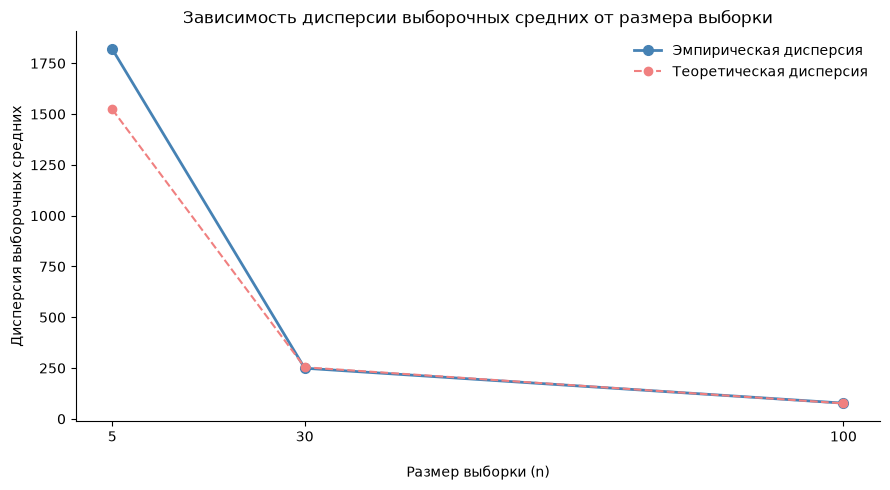

In [43]:
# Визуальное сравнение дисперсий
fig, ax = plt.subplots(figsize=(9, 5))

# Эмпирическая дисперсия
ax.plot(
    variance_comparison['n'],
    variance_comparison['empirical_variance'],
    marker='o',
    markersize=7,
    linewidth=2,
    color='steelblue',
    label='Эмпирическая дисперсия'
)
# Теоретическая кривая
ax.plot(
    variance_comparison['n'],
    variance_comparison['theoretical_variance'],
    marker='o',
    markersize=6,
    linewidth=1.5,
    linestyle='--',
    color='lightcoral',
    label='Теоретическая дисперсия'
)

ax.set(
    title='Зависимость дисперсии выборочных средних от размера выборки',
    xlabel='Размер выборки (n)',
    ylabel='Дисперсия выборочных средних'
)

ax.xaxis.labelpad = 15
ax.set_xticks(sample_sizes)
ax.grid(False)
ax.legend(frameon=False)

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'sample_means_variance.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Моделирование подтвердило, что с увеличением размера выборки дисперсия выборочных средних уменьшается.

- **При $n=5$** эмпирическая дисперсия составляет 1819,22, теоретическая — 1522,71. Относительное отклонение достигает +19,47%.
- **При $n=30$** эмпирическая дисперсия снижается до 249,32, теоретическая составляет 253,78. Отклонение равно −1,76%.
- **При $n=100$** эмпирическая дисперсия составляет 77,32, теоретическая — 76,14. Отклонение равно +1,56%.

На графике наблюдается выраженное уменьшение дисперсии при увеличении размера выборки. Эмпирические результаты в целом согласуются с теоретической зависимостью $\operatorname{Var}(\overline X)=\sigma^2/n$.

Наибольшее расхождение между теорией и моделированием наблюдается при \(n=5\). При небольшом размере выборки отдельные крупные покупки сильнее влияют на выборочные средние. В сочетании с ограниченным числом симуляций это может приводить к заметным отклонениям эмпирической дисперсии от теоретической.

При увеличении $n$ выборочные средние становятся менее изменчивыми и концентрируются вокруг среднего генеральной совокупности.

Таким образом, результаты E.1 и E.2 согласуются с центральной предельной теоремой: распределение выборочных средних становится ближе к нормальному, а их дисперсия уменьшается с увеличением размера выборки в соответствии с теоретической зависимостью $\sigma^2/n$ .

## F. Параметрические оценки

### F.1. Подбор распределения суммы покупки

**Задача:** подобрать параметрическое распределение для переменной `purchase_amount` среди покупателей (`converted == 1`) и оценить его параметры методом максимального правдоподобия (MLE).

Поскольку суммы покупок являются положительными величинами с выраженной правосторонней асимметрией, рассмотрим четыре распределения:

1. **Логнормальное распределение (`lognorm`)** — описывает положительные величины, логарифмы которых имеют нормальное распределение. Подходит для данных с длинным правым хвостом.
2. **Гамма-распределение (`gamma`)** — гибкое распределение для положительных непрерывных величин, позволяющее моделировать различную степень правосторонней асимметрии.
3. **Распределение Вейбулла (`weibull_min`)** — используется для моделирования положительных величин и позволяет изменять форму распределения в зависимости от параметров.
4. **Логлогистическое распределение (`fisk`)** — распределение для положительных величин, способное описывать выраженную правостороннюю асимметрию и тяжёлые хвосты.

**Оценка параметров**

Для каждой модели оценим параметры методом максимального правдоподобия (MLE) с помощью метода .fit() из scipy.stats.

Параметр сдвига `loc` зафиксируем равным нулю (`floc=0`). Таким образом, для каждой модели будут оцениваться два параметра:

- `shape` — параметр формы распределения;
- `scale` — параметр масштаба распределения.

Следует учитывать, что математический смысл параметров различается между распределениями.

**Сравнение моделей**

Для предварительного выбора наиболее подходящей модели используем информационный критерий Акаике (AIC):

$$
AIC = 2k - 2\ln(\hat L)
$$

где:

- $k$ — количество оцениваемых параметров модели;
- $\hat L$ — максимальное значение функции правдоподобия.

Поскольку во всех четырёх моделях оцениваются два параметра, принимаем $k=2$.

**Чем меньше AIC, тем предпочтительнее модель среди рассматриваемых альтернатив** с точки зрения баланса качества подгонки и сложности модели.

Однако минимальный AIC не гарантирует хорошего соответствия эмпирическому распределению. Поэтому в разделе F.2 дополнительно проверим адекватность моделей с помощью сравнения плотностей и Q–Q графиков.

In [44]:
# Суммы покупок среди покупателей
purchase_values = buyers['purchase_amount'].dropna().to_numpy()

# Проверка данных для подбора распределений
print(f'Количество покупок: {len(purchase_values)}')
print(f'Минимальная сумма покупки: {purchase_values.min():.2f}')
print(f'Количество нулевых и отрицательных значений: '
      f'{np.sum(purchase_values <= 0)}')

# Распределения для сравнения
distributions = {
    'Логнормальное': stats.lognorm,
    'Гамма': stats.gamma,
    'Вейбулла': stats.weibull_min,
    'Логлогистическое': stats.fisk
}

# Оценка параметров методом максимального правдоподобия
fitted_models = {
    name: {
        'distribution': distribution,
        'params': distribution.fit(purchase_values, floc=0)
    }
    for name, distribution in distributions.items()
}

# Расчёт AIC
fit_results = []

for name, model in fitted_models.items():
    distribution = model['distribution']
    params = model['params']

    log_likelihood = distribution.logpdf(
        purchase_values, *params
    ).sum()

    k = len(params) - 1  # loc зафиксирован, оцениваются два параметра
    aic = 2 * k - 2 * log_likelihood

    fit_results.append({
        'distribution': name,
        'shape': params[0],
        'scale': params[2],
        'log_likelihood': log_likelihood,
        'AIC': aic
    })

fit_comparison = (
    pd.DataFrame(fit_results)
    .sort_values('AIC')
    .reset_index(drop=True)
)

fit_comparison['delta_AIC'] = (
    fit_comparison['AIC'] - fit_comparison['AIC'].min()
)


display(fit_comparison.round(2))

Количество покупок: 1820
Минимальная сумма покупки: 1.07
Количество нулевых и отрицательных значений: 0


,distribution,shape,scale,log_likelihood,AIC,delta_AIC
0,Логнормальное,0.91,59.77,-9860.16,19724.33,0.00
1,Логлогистическое,1.94,56.22,-9866.29,19736.58,12.25
2,Гамма,1.20,80.27,-10109.00,20222.00,497.67
3,Вейбулла,1.01,96.38,-10126.13,20256.27,531.94


Методом максимального правдоподобия (MLE) были оценены параметры четырёх распределений: логнормального, логлогистического, гамма-распределения и распределения Вейбулла.

**Наиболее предпочтительной моделью по критерию AIC оказалось логнормальное распределение** (AIC = 19724,33; ΔAIC = 0). Оценённые параметры модели: `shape = 0,91`, `scale = 59,77`.

Логлогистическое распределение заняло второе место (AIC = 19736,58; ΔAIC = 12,25). Такое различие указывает на существенное преимущество логнормальной модели по критерию AIC.

Гамма-распределение (ΔAIC = 497,67) и распределение Вейбулла (ΔAIC = 531,94) значительно уступают двум первым моделям.

**Таким образом, логнормальное распределение предварительно выбрано для моделирования положительных сумм покупок.** Однако минимальный AIC показывает лишь относительное преимущество среди рассмотренных моделей и не гарантирует абсолютной адекватности распределения.

В разделе F.2 дополнительно проверим соответствие теоретических и эмпирических плотностей, а также поведение моделей в правом хвосте распределения с помощью Q–Q графиков.

### F.2. Проверка адекватности параметрических моделей

**Задача:** оценить, насколько хорошо подобранные теоретические распределения описывают эмпирическое распределение сумм покупок.

Проверку проведём двумя способами:

1. **Сравнение плотностей.** Построим гистограмму `purchase_amount` среди покупателей с нормировкой на плотность и наложим теоретические функции плотности четырёх распределений, параметры которых оценены методом максимального правдоподобия.

2. **Q–Q графики.** Для двух моделей с наименьшими значениями AIC — логнормальной и логлогистической — сравним эмпирические квантили с теоретическими.

При анализе обратим внимание на соответствие центральной части распределения и правого хвоста, который отражает наиболее крупные покупки.

Близость точек Q–Q графика к диагональной линии свидетельствует о хорошем соответствии модели данным. Систематические отклонения, особенно в хвостах, указывают на возможные ограничения модели.

Визуальная проверка позволит дополнить сравнение по AIC, но сама по себе не является формальным доказательством адекватности распределения.

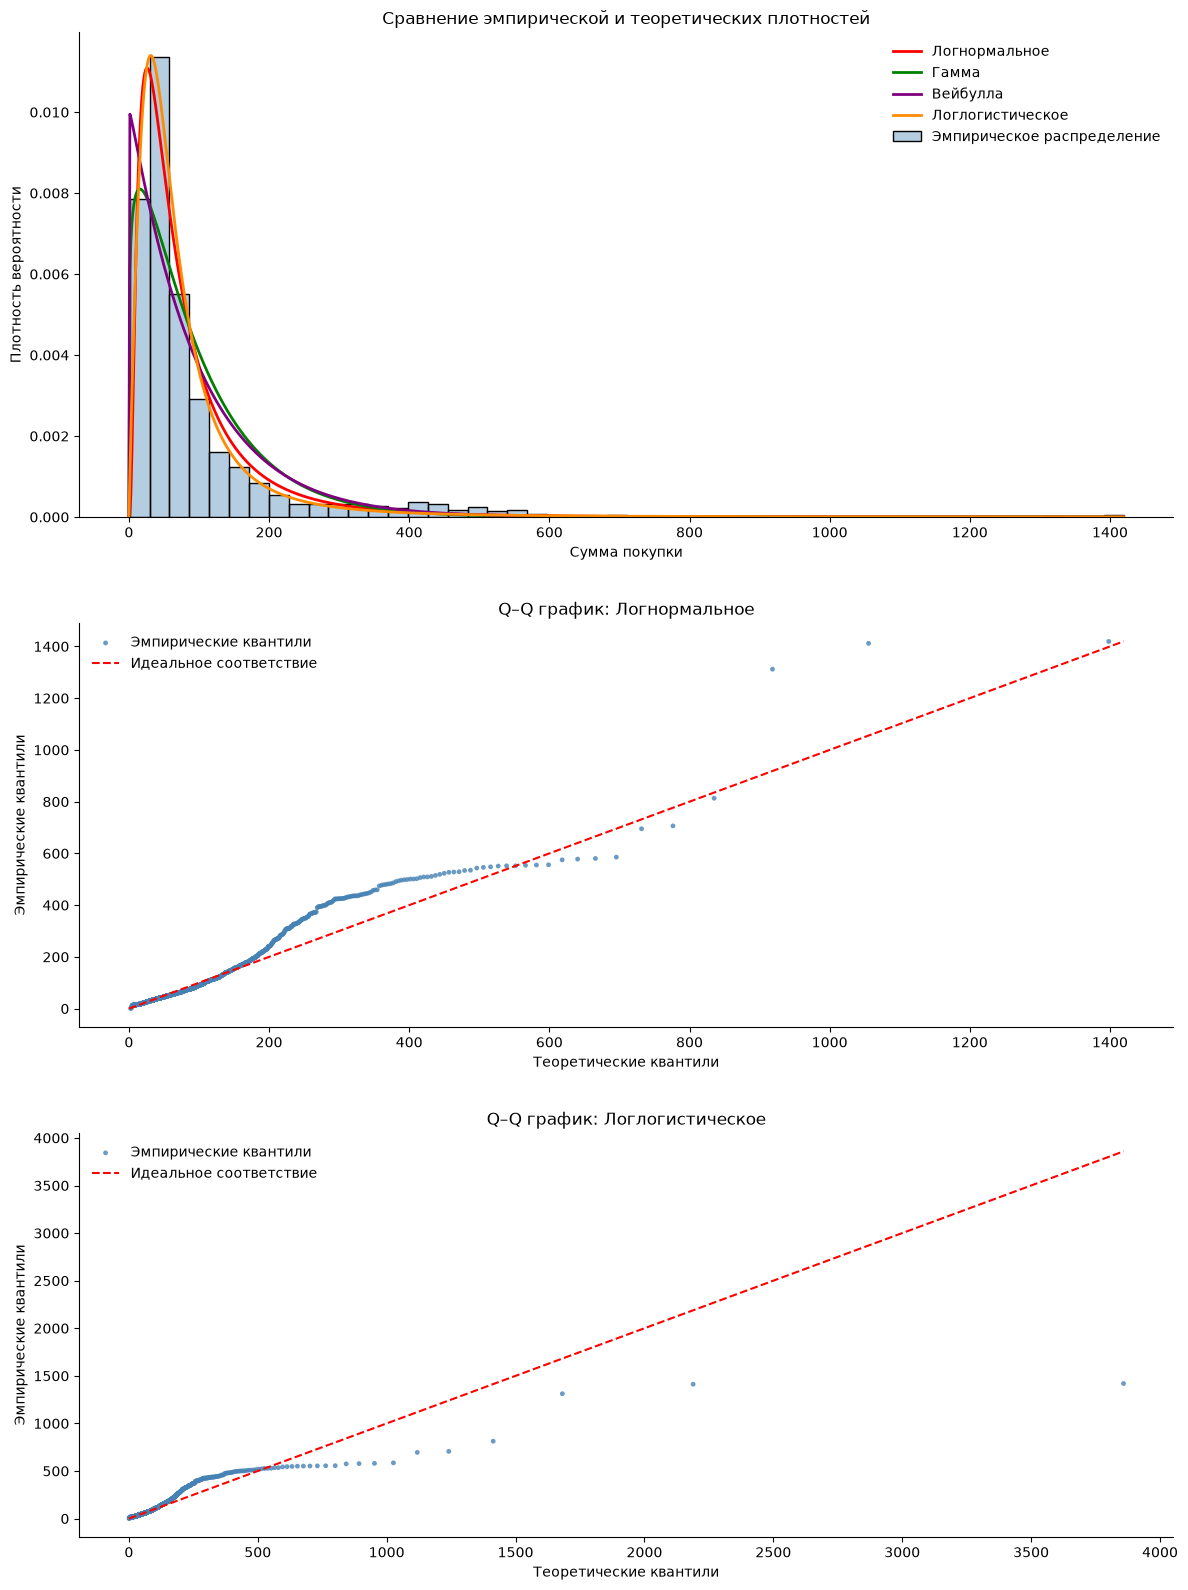

In [45]:
model_colors = {
    'Логнормальное': 'red',
    'Логлогистическое': 'darkorange',
    'Гамма': 'green',
    'Вейбулла': 'purple'
}

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 16),
    gridspec_kw={'height_ratios': [1.2, 1, 1]}
)

# 1. Сравнение плотностей
ax = axes[0]

x = np.linspace(0, purchase_values.max(), 1000)

sns.histplot(
    purchase_values,
    bins=50,
    stat='density',
    color='steelblue',
    alpha=0.4,
    label='Эмпирическое распределение',
    ax=ax
)

for name, model in fitted_models.items():
    ax.plot(
        x,
        model['distribution'].pdf(x, *model['params']),
        color=model_colors[name],
        linewidth=2,
        label=name
    )

ax.set(
    title='Сравнение эмпирической и теоретических плотностей',
    xlabel='Сумма покупки',
    ylabel='Плотность вероятности'
)

ax.legend(frameon=False)
ax.grid(False)

# 2–3. Q–Q графики двух лучших моделей
probabilities = (
    np.arange(1, len(purchase_values) + 1) - 0.5
) / len(purchase_values)

empirical_quantiles = np.sort(purchase_values)

best_models = fit_comparison['distribution'].head(2)

for ax, name in zip(axes[1:], best_models):
    model = fitted_models[name]

    theoretical_quantiles = model['distribution'].ppf(
        probabilities,
        *model['params']
    )

    ax.scatter(
        theoretical_quantiles,
        empirical_quantiles,
        color='steelblue',
        s=12,
        alpha=0.8,
        edgecolors='none',
        label='Эмпирические квантили'
    )

    max_quantile = max(
        theoretical_quantiles.max(),
        empirical_quantiles.max()
    )

    ax.plot(
        [0, max_quantile],
        [0, max_quantile],
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Идеальное соответствие'
    )

    ax.set(
        title=f'Q–Q график: {name}',
        xlabel='Теоретические квантили',
        ylabel='Эмпирические квантили'
    )

    ax.legend(frameon=False)
    ax.grid(False)

sns.despine()

plt.tight_layout(h_pad=3)

fig.savefig(
    FIGURES_DIR / 'distribution_fit_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

Сравнение эмпирической плотности с теоретическими показывает, что все четыре распределения воспроизводят общую форму данных: выраженную правостороннюю асимметрию и концентрацию покупок в области небольших сумм.

Логнормальное и логлогистическое распределения визуально лучше описывают область максимальной плотности, чем гамма-распределение и распределение Вейбулла.

**Q–Q график логнормального распределения** показывает относительно хорошее соответствие для небольших сумм покупок. Однако в средней и верхней частях распределения наблюдаются систематические отклонения от диагонали. Это свидетельствует о том, что модель не полностью воспроизводит эмпирические квантили.

**Q–Q график логлогистического распределения** демонстрирует ещё более выраженные отклонения в правом хвосте: теоретические квантили для наиболее крупных покупок значительно превышают наблюдаемые значения. Следовательно, эта модель склонна переоценивать экстремально большие суммы.

Таким образом, визуальная проверка в целом согласуется с результатами сравнения по AIC: **логнормальное распределение остаётся наиболее предпочтительным среди рассмотренных моделей**, хотя и не обеспечивает точного соответствия данным на всём диапазоне значений.

Логнормальную модель можно рассматривать как приближение для моделирования сумм покупок, но при прогнозировании крупных покупок необходимо учитывать выявленные отклонения в правом хвосте.

### F.3. Пригодность выбранного распределения для симуляций и прогнозирования

**Задача:** определить, можно ли использовать выбранное параметрическое распределение для моделирования и прогнозирования сумм покупок.

По результатам оценки параметров методом максимального правдоподобия и сравнения моделей по критерию AIC наиболее предпочтительным оказалось **логнормальное распределение**.

Визуальный анализ подтвердил, что оно достаточно хорошо воспроизводит общую форму эмпирического распределения положительных сумм покупок: концентрацию небольших значений и выраженную правостороннюю асимметрию.

Однако Q–Q график выявил систематические отклонения, особенно в области крупных покупок. Следовательно, логнормальная модель не полностью отражает особенности эмпирического распределения.

**Практические рекомендации:**

- **Для симуляций:** логнормальное распределение можно использовать как приближённую модель для генерации положительных сумм покупок и исследования возможных сценариев продаж.
- **Для прогнозирования:** модель можно использовать для предварительных расчётов, однако её прогностическая точность пока не проверена на независимых данных.
- **Для оценки крупных покупок:** следует соблюдать осторожность, поскольку расхождения в правом хвосте могут приводить к неточным оценкам редких и дорогостоящих заказов.

При моделировании общей выручки также необходимо отдельно учитывать вероятность конверсии: подобранное распределение описывает суммы покупок **только среди покупателей**, а не среди всех посетителей.

**Итог:** логнормальное распределение можно использовать для приближённых симуляций и предварительных расчётов, однако его точность ограничена, особенно в области крупных покупок. Для задач, требующих высокой точности, особенно при оценке крупных заказов, необходима дополнительная проверка качества прогнозов.

## G. Свойства оценок и обсуждение

### G.1. Смещённость и состоятельность оценки среднего

**Задача:** исследовать свойства выборочного среднего для переменной `purchase_amount` с помощью моделирования случайных выборок разного объёма.

Рассмотрим два свойства статистической оценки:

**1. Несмещённость**

Оценка называется несмещённой, если её математическое ожидание равно истинному значению оцениваемого параметра:

$$
E(\bar X)=\mu
$$

Для эмпирической проверки рассчитаем среднее значение выборочных средних и сравним его со средним генеральной совокупности:

$$
\widehat{Bias}=\frac{1}{B}\sum_{b=1}^{B}\bar X_b-\mu
$$

где $B$ — количество повторных выборок.

**2. Состоятельность**

Оценка называется состоятельной, если при увеличении объёма выборки она сходится по вероятности к истинному значению параметра:

$$
\bar X_n\xrightarrow{P}\mu,\quad n\to\infty
$$

При моделировании будем исследовать признаки состоятельности: уменьшение разброса выборочных средних и среднеквадратичной ошибки (RMSE) при увеличении размера выборки.

**Методика эксперимента**

- Используем все значения `purchase_amount`, включая нулевые покупки посетителей без конверсии.
- Рассмотрим размеры выборок $n=10$, $n=50$ и $n=200$.
- Для каждого размера сформируем 1000 простых случайных выборок без возвращения.
- Рассчитаем выборочные средние, их отклонения от среднего генеральной совокупности, эмпирическое смещение, стандартное отклонение оценок и RMSE.

Сравним полученные показатели и оценим, как увеличение объёма выборки влияет на точность оценки среднего.

In [46]:
sample_sizes_g = [10, 50, 200]
n_simulations_g = 1000

population_values = df['purchase_amount'].to_numpy()
population_mean_g = population_values.mean()

rng_g = np.random.default_rng(RANDOM_STATE)

sample_means_g = {
    n: np.array([
        rng_g.choice(
            population_values,
            size=n,
            replace=False
        ).mean()
        for _ in range(n_simulations_g)
    ])
    for n in sample_sizes_g
}

estimator_results = []

for n, means in sample_means_g.items():
    deviations = means - population_mean_g

    estimator_results.append({
        'n': n,
        'population_mean': population_mean_g,
        'mean_of_estimates': means.mean(),
        'bias': deviations.mean(),
        'std_of_estimates': means.std(ddof=1),
        'RMSE': np.sqrt(np.mean(deviations ** 2))
    })

estimator_comparison = pd.DataFrame(estimator_results)

display(estimator_comparison.round(2))

,n,population_mean,mean_of_estimates,bias,std_of_estimates,RMSE
0,10,34.93,33.81,-1.12,28.20,28.21
1,50,34.93,35.42,0.49,11.88,11.88
2,200,34.93,35.02,0.09,5.84,5.84


#### Визуализация распределений выборочных средних

Для наглядного сравнения точности оценок построим графики плотности распределения выборочных средних при объёмах выборки $n = 10$, $n = 50$ и $n = 200$.

На одном графике отобразим три распределения, а вертикальной пунктирной линией обозначим среднее генеральной совокупности.

Это позволит оценить, как при увеличении объёма выборки изменяются разброс оценок и их концентрация вокруг истинного среднего.

**Ожидаемый результат:** с увеличением размера выборки распределение выборочных средних должно становиться более узким и концентрироваться вокруг среднего генеральной совокупности. Это будет согласовываться с теоретическим свойством состоятельности выборочного среднего.

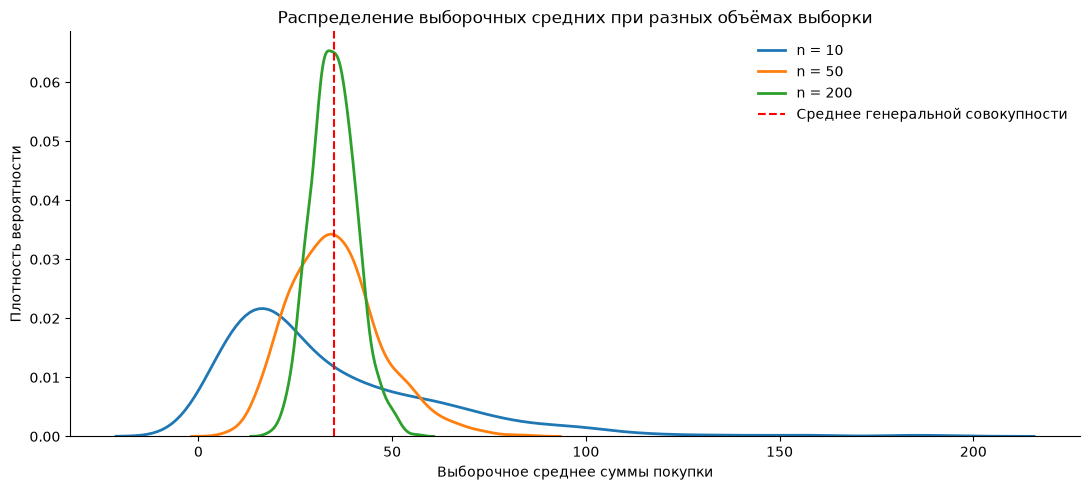

In [47]:
fig, ax = plt.subplots(figsize=(11, 5))

for n in sample_sizes_g:
    sns.kdeplot(
        sample_means_g[n],
        ax=ax,
        linewidth=2,
        label=f'n = {n}'
    )

ax.axvline(
    population_mean_g,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Среднее генеральной совокупности'
)

ax.set(
    title='Распределение выборочных средних при разных объёмах выборки',
    xlabel='Выборочное среднее суммы покупки',
    ylabel='Плотность вероятности'
)

ax.legend(frameon=False)
ax.grid(False)

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'estimator_consistency.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

В ходе моделирования были исследованы свойства выборочного среднего `purchase_amount` на основе 1000 случайных выборок каждого объёма: $n = 10$, $n = 50$ и $n = 200$.

**1. Несмещённость оценки**

Среднее генеральной совокупности составляет 34,93. Средние значения оценок для выборок объёмом 10, 50 и 200 наблюдений составили соответственно 33,81, 35,42 и 35,02.

Эмпирическое смещение оказалось небольшим относительно среднего генеральной совокупности: −1,12, 0,49 и 0,09 соответственно.

Полученные результаты согласуются с теоретическим свойством несмещённости выборочного среднего. Ненулевые значения эмпирического смещения связаны со случайными колебаниями при ограниченном количестве симуляций и не означают систематической смещённости оценки.

**2. Состоятельность оценки**

При увеличении объёма выборки наблюдается существенное снижение разброса оценок:

- Стандартное отклонение выборочных средних уменьшается с 28,20 при $n = 10$ до 5,84 при $n = 200$.
- Среднеквадратичная ошибка (RMSE) сокращается с 28,21 до 5,84.

График подтверждает эту закономерность: распределение выборочных средних становится более узким и концентрируется вокруг среднего генеральной совокупности.

При небольшом объёме выборки ($n = 10$) распределение оценок сохраняет выраженную правостороннюю асимметрию, связанную с особенностями исходных данных. При увеличении объёма выборки распределение становится более симметричным.

**Итог:** результаты моделирования согласуются с теоретическими свойствами выборочного среднего как несмещённой и состоятельной оценки математического ожидания. Увеличение объёма выборки существенно снижает случайную ошибку и повышает точность оценки среднего `purchase_amount`.

### G.2. Смещённость и состоятельность оценки доли конверсий

**Задача:** исследовать свойства выборочной доли конверсий `converted` и оценить влияние объёма выборки на точность её определения.

Переменная `converted` является бинарной: значение 1 соответствует совершённой покупке, значение 0 — отсутствию покупки.

Доля конверсий в генеральной совокупности определяется как:

$$
p = \frac{N_{\text{converted}}}{N}
$$

Её выборочная оценка:

$$
\hat p = \frac{1}{n}\sum_{i=1}^{n}X_i
$$

где $X_i \in \{0,1\}$.

Выборочная доля является несмещённой оценкой генеральной доли при простом случайном отборе.

Для проверки этого свойства и исследования состоятельности проведём моделирование:

- Сформируем по 1000 случайных выборок объёмом 10, 50 и 200 наблюдений без возвращения.
- Для каждой выборки рассчитаем долю конверсий.
- Определим среднюю оценку, эмпирическое смещение, стандартное отклонение и RMSE.
- Сравним результаты с истинной долей конверсий генеральной совокупности.

Ожидается, что при увеличении объёма выборки разброс оценок и RMSE будут уменьшаться, а сами оценки — концентрироваться вокруг генеральной доли конверсий.

In [48]:
conversion_values = df['converted'].to_numpy()
population_conversion = conversion_values.mean()

rng_conversion = np.random.default_rng(RANDOM_STATE)

conversion_estimates = {
    n: np.array([
        rng_conversion.choice(
            conversion_values,
            size=n,
            replace=False
        ).mean()
        for _ in range(n_simulations_g)
    ])
    for n in sample_sizes_g
}

conversion_results = []

for n, estimates in conversion_estimates.items():
    deviations = estimates - population_conversion

    conversion_results.append({
        'n': n,
        'population_conversion_pct': population_conversion * 100,
        'mean_estimate_pct': estimates.mean() * 100,
        'bias_pp': deviations.mean() * 100,
        'std_pp': estimates.std(ddof=1) * 100,
        'RMSE_pp': np.sqrt(np.mean(deviations ** 2)) * 100
    })

conversion_estimator_comparison = pd.DataFrame(conversion_results)

display(conversion_estimator_comparison.round(2))

,n,population_conversion_pct,mean_estimate_pct,bias_pp,std_pp,RMSE_pp
0,10,36.40,35.49,-0.91,14.76,14.78
1,50,36.40,36.73,0.33,6.59,6.60
2,200,36.40,36.28,-0.12,3.34,3.34


#### Визуализация распределений оценок доли конверсий

Для наглядного сравнения точности оценок построим сглаженные графики плотности распределения выборочных долей конверсий при объёмах выборки $n = 10$, $n = 50$ и $n = 200$.

На одном графике отобразим три распределения, а вертикальной пунктирной линией обозначим долю конверсий генеральной совокупности.

Это позволит оценить, как при увеличении объёма выборки изменяются разброс оценок и их концентрация вокруг истинной доли конверсий.

**Ожидаемый результат:** с увеличением размера выборки разброс оценок должен уменьшаться, а сами оценки — становиться ближе к генеральной доле конверсий.

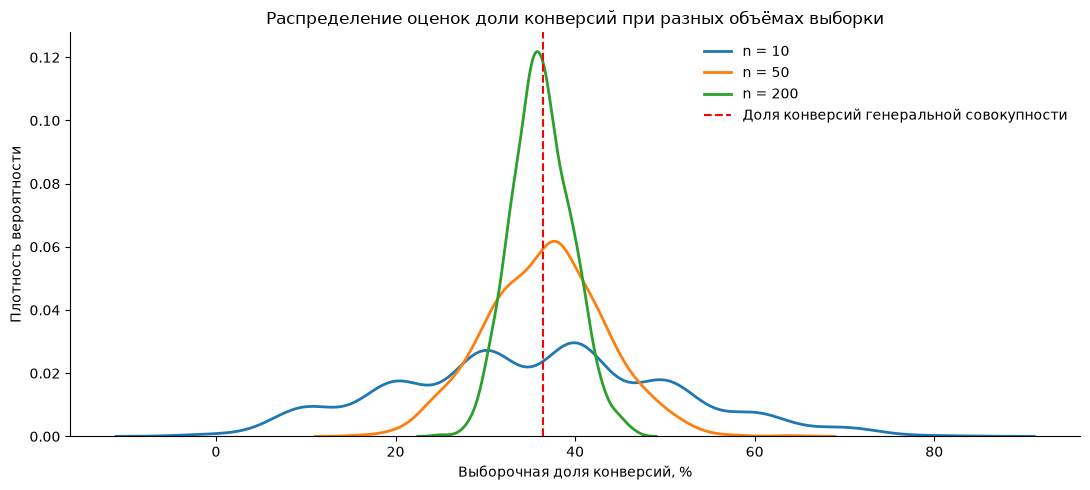

In [49]:
fig, ax = plt.subplots(figsize=(11, 5))

for n in sample_sizes_g:
    sns.kdeplot(
        conversion_estimates[n] * 100,
        ax=ax,
        linewidth=2,
        label=f'n = {n}'
    )

ax.axvline(
    population_conversion * 100,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Доля конверсий генеральной совокупности'
)

ax.set(
    title='Распределение оценок доли конверсий при разных объёмах выборки',
    xlabel='Выборочная доля конверсий, %',
    ylabel='Плотность вероятности'
)

ax.legend(frameon=False)
ax.grid(False)

sns.despine()
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / 'conversion_estimator_consistency.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

В ходе моделирования были исследованы свойства выборочной доли конверсий на основе 1000 случайных выборок каждого объёма: $n = 10$, $n = 50$ и $n = 200$.

**1. Несмещённость оценки**

Доля конверсий в генеральной совокупности составляет **36,40%**. Средние значения выборочных оценок составили 35,49%, 36,73% и 36,28% соответственно.

Эмпирическое смещение оказалось небольшим: −0,91, +0,33 и −0,12 процентного пункта. Небольшие отклонения от нуля связаны со случайностью моделирования. Полученные результаты согласуются с тем, что выборочная доля является несмещённой оценкой генеральной доли.

**2. Состоятельность оценки**

При увеличении объёма выборки с 10 до 200 наблюдений:

- Стандартное отклонение оценок уменьшилось с 14,76 до 3,34 процентного пункта.
- Среднеквадратичная ошибка (RMSE) снизилась с 14,78 до 3,34 процентного пункта.

Визуализация подтверждает полученные результаты: распределения оценок становятся более узкими и концентрируются вокруг генеральной доли конверсий.

При $n = 10$ распределение имеет несколько локальных максимумов, что связано с дискретностью возможных значений выборочной доли и особенностями сглаживания KDE.

**Итог:** результаты моделирования согласуются с теоретическими свойствами выборочной доли как несмещённой и состоятельной оценки генеральной доли конверсий. Увеличение объёма выборки существенно снижает случайную ошибку и повышает точность оценки.

### G.3. Смещённая и несмещённая оценки дисперсии

**Задача:** сравнить свойства двух оценок дисперсии `purchase_amount`, рассчитанных с параметрами `ddof=0` и `ddof=1`, и исследовать влияние объёма выборки на их смещение и точность.

Рассмотрим две оценки дисперсии.

**1. Смещённая оценка (`ddof=0`)**

$$
s_0^2 = \frac{1}{n}\sum_{i=1}^{n}(X_i-\bar X)^2
$$

Эта оценка использует деление на $n$ и при случайной выборке, как правило, систематически занижает дисперсию генеральной совокупности.

**2. Несмещённая оценка (`ddof=1`)**

$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(X_i-\bar X)^2
$$

Использование поправки Бесселя ($n-1$) позволяет получить несмещённую оценку дисперсии генеральной совокупности с делителем $N-1$ при простом случайном отборе.

**Методика эксперимента**

Для сопоставимости с предыдущими исследованиями используем те же параметры моделирования:

- Объёмы выборок: $n=10$, $n=50$, $n=200$.
- Количество повторений: 1000 для каждого объёма.
- Метод отбора: простая случайная выборка без возвращения.
- Для каждой выборки рассчитаем дисперсию с `ddof=0` и `ddof=1`.
- Для каждой оценки определим эмпирическое смещение, стандартное отклонение и RMSE.

В качестве истинного значения используем дисперсию всей генеральной совокупности, рассчитанную с `ddof=0`.

**Особенность эксперимента:** поскольку выборки формируются без возвращения из конечной генеральной совокупности, оценка с `ddof=1` несмещённо оценивает генеральную дисперсию с делителем $N-1$. При сравнении с дисперсией, рассчитанной с делителем $N$, остаётся небольшое различие, связанное с конечным размером генеральной совокупности.

Ожидается, что при увеличении объёма выборки различия между оценками с ddof=0 и ddof=1 будут уменьшаться, а разброс оценок дисперсии — сокращаться.

In [50]:
population_variance_g = population_values.var(ddof=0)

rng_variance = np.random.default_rng(RANDOM_STATE)

variance_estimates = {
    n: {'ddof_0': [], 'ddof_1': []}
    for n in sample_sizes_g
}

for n in sample_sizes_g:
    for _ in range(n_simulations_g):
        sample = rng_variance.choice(
            population_values,
            size=n,
            replace=False
        )

        variance_estimates[n]['ddof_0'].append(
            sample.var(ddof=0)
        )

        variance_estimates[n]['ddof_1'].append(
            sample.var(ddof=1)
        )

variance_results = []

for n, estimates in variance_estimates.items():
    for estimator, values in estimates.items():
        values = np.array(values)
        deviations = values - population_variance_g

        variance_results.append({
            'n': n,
            'estimator': estimator,
            'population_variance': population_variance_g,
            'mean_estimate': values.mean(),
            'bias': deviations.mean(),
            'std_of_estimates': values.std(ddof=1),
            'RMSE': np.sqrt(np.mean(deviations ** 2))
        })

variance_estimator_comparison = pd.DataFrame(variance_results)

display(variance_estimator_comparison.round(2))

,n,estimator,population_variance,mean_estimate,bias,std_of_estimates,RMSE
0,10,ddof_0,7613.53,6865.88,-747.64,16387.32,16396.18
1,10,ddof_1,7613.53,7628.76,15.23,18208.13,18199.03
2,50,ddof_0,7613.53,7472.06,-141.46,7114.13,7111.98
3,50,ddof_1,7613.53,7624.56,11.03,7259.32,7255.70
4,200,ddof_0,7613.53,7643.60,30.07,3559.73,3558.08
5,200,ddof_1,7613.53,7682.01,68.48,3577.62,3576.48


#### Визуализация распределений оценок дисперсии

Для сравнения смещённой и несмещённой оценок дисперсии построим сглаженные распределения полученных оценок при объёмах выборки $n=10$, $n=50$ и $n=200$.

На каждом графике отобразим две оценки: с делителем $n$ (`ddof=0`) и с поправкой Бесселя (`ddof=1`). Вертикальной пунктирной линией обозначим дисперсию генеральной совокупности.

Сравнение позволит оценить, как поправка Бесселя влияет на положение и разброс распределений, а также как увеличение объёма выборки изменяет точность оценивания.

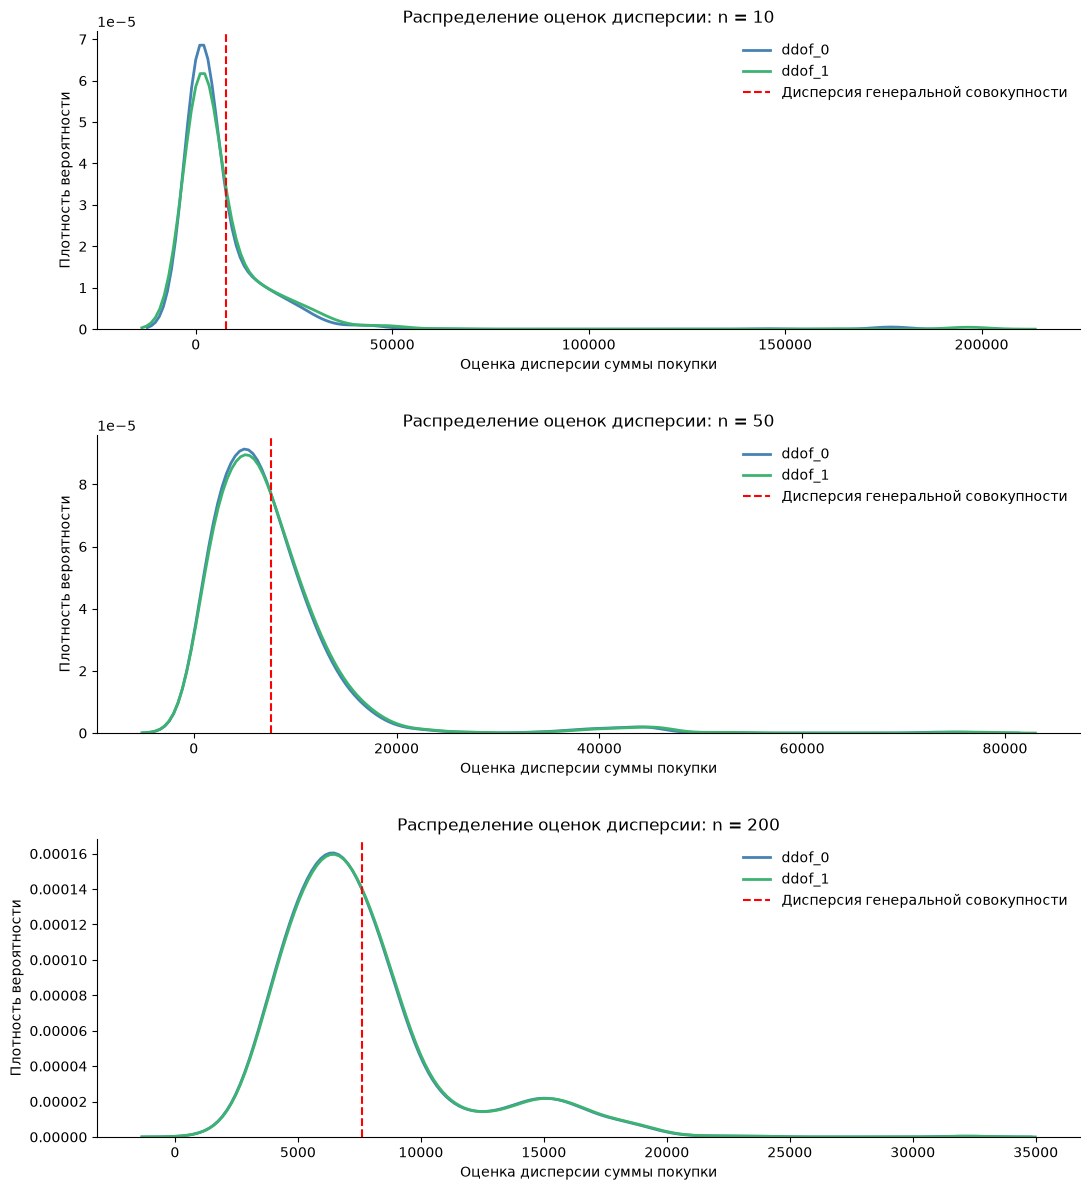

In [51]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12))

for ax, n in zip(axes, sample_sizes_g):
    for estimator, color in [
        ('ddof_0', 'steelblue'),
        ('ddof_1', 'mediumseagreen')
    ]:
        sns.kdeplot(
            variance_estimates[n][estimator],
            ax=ax,
            color=color,
            linewidth=2,
            label=estimator
        )

    ax.axvline(
        population_variance_g,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Дисперсия генеральной совокупности'
    )

    ax.set(
        title=f'Распределение оценок дисперсии: n = {n}',
        xlabel='Оценка дисперсии суммы покупки',
        ylabel='Плотность вероятности'
    )

    ax.legend(frameon=False)
    ax.grid(False)

sns.despine()
plt.tight_layout(h_pad=3)

fig.savefig(
    FIGURES_DIR / 'variance_estimator_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

В ходе моделирования были исследованы две оценки дисперсии `purchase_amount`: с делителем $n$ (`ddof=0`) и с поправкой Бесселя $n-1$ (`ddof=1`). Для каждого объёма выборки — 10, 50 и 200 наблюдений — выполнено 1000 повторений.

**1. Смещённость оценок**

Дисперсия генеральной совокупности, рассчитанная с `ddof=0`, составляет **7613,53**.

При $n=10$ оценка `ddof=0` продемонстрировала выраженное отрицательное эмпирическое смещение (−747,64). Использование поправки Бесселя существенно сократило его по модулю — до 15,23.

При $n=50$ наблюдалась аналогичная закономерность: смещение составило −141,46 для `ddof=0` и 11,03 для `ddof=1`.

При $n=200$ эмпирическое смещение обеих оценок оказалось положительным: 30,07 и 68,48 соответственно. Это не свидетельствует об изменении теоретических свойств оценок, а отражает случайные колебания результатов моделирования.

**2. Состоятельность и точность оценок**

С увеличением объёма выборки наблюдается существенное снижение RMSE:

- Для `ddof=0` — с 16 396,18 до 3558,08.
- Для `ddof=1` — с 18 199,03 до 3576,48.

Это согласуется с состоятельностью обеих оценок дисперсии.

При этом во всех трёх экспериментах RMSE оказался ниже для `ddof=0`. Это показывает, что устранение смещения с помощью поправки Бесселя не обязательно уменьшает общую ошибку оценки. Следовательно, устранение смещения с помощью поправки Бесселя не обязательно приводит к снижению среднеквадратичной ошибки.

**3. Анализ распределений оценок**

Графики показывают, что с увеличением объёма выборки разброс оценок уменьшается. При этом распределения остаются асимметричными, а отдельные выборки дают заметно завышенные оценки дисперсии.

Кривые `ddof=0` и `ddof=1` близки друг к другу, особенно при больших объёмах выборки. Длинные правые хвосты свидетельствуют о чувствительности дисперсии к редким крупным значениям `purchase_amount`.

**Итог:** моделирование подтверждает практическую роль поправки Бесселя в устранении смещения оценки дисперсии. Обе оценки демонстрируют повышение точности при увеличении объёма выборки, однако несмещённость сама по себе не гарантирует минимальную RMSE.

### Общие выводы по разделу G

В разделе были исследованы свойства статистических оценок трёх показателей: средней суммы покупки, доли конверсий и дисперсии суммы покупки. Для каждого показателя проведено моделирование на основе 1000 случайных выборок объёмом 10, 50 и 200 наблюдений.

**1. Влияние объёма выборки на точность оценивания**

Во всех трёх исследованиях увеличение объёма выборки сопровождалось снижением стандартного отклонения оценок и среднеквадратичной ошибки (RMSE).

Это подтверждает практическую важность размера выборки: чем больше наблюдений используется, тем устойчивее статистические оценки и тем меньше влияние случайных колебаний.

**2. Несмещённость и состоятельность**

Результаты моделирования согласуются с теоретической несмещённостью выборочного среднего и выборочной доли конверсий.

При оценивании дисперсии результаты моделирования также согласуются с теорией: поправка Бесселя (ddof=1) позволяет получить несмещённую оценку генеральной дисперсии с делителем $N-1$ при простом случайном отборе.

При этом несмещённость и точность — не одно и то же. Оценка с меньшим смещением не обязательно обладает меньшей RMSE, что продемонстрировано при сравнении двух способов расчёта дисперсии.

**3. Влияние особенностей исходных данных**

Распределение `purchase_amount` характеризуется выраженной правосторонней асимметрией и наличием редких крупных покупок.

Это особенно заметно при оценивании дисперсии: даже относительно большие выборки могут давать существенно различающиеся результаты в зависимости от попадания крупных значений.

Оценка доли конверсий, напротив, основана на бинарной переменной и не подвержена влиянию экстремальных сумм покупок.

**4. Практическое значение для e-commerce**

Полученные результаты позволяют сформулировать несколько рекомендаций:

- При оценке средней суммы покупки и конверсии важно учитывать размер выборки: на небольших выборках оценки могут заметно отличаться от реальных значений.
- При оценивании дисперсии по выборке следует использовать поправку Бесселя (`ddof=1`), если требуется несмещённая оценка дисперсии с делителем $N-1$.
- При анализе денежных показателей необходимо учитывать асимметрию распределения и влияние крупных покупок.
- Для оценки надёжности бизнес-метрик целесообразно использовать не только точечные оценки, но и доверительные интервалы, рассмотренные ранее в разделе D.

**Итог:** моделирование продемонстрировало, что увеличение объёма выборки повышает точность статистического оценивания, а выбор конкретной оценки должен учитывать не только её смещённость, но и разброс, среднеквадратичную ошибку и особенности исходного распределения.

## H. Бизнес-анализ и рекомендации

### H.1. Анализ факторов конверсии и среднего чека

#### H.1.1. Рекламные кампании и источники трафика

**Задача:** сравнить конверсию, средний чек и выручку между рекламными кампаниями (`campaign`) и источниками трафика (`traffic_source`), чтобы выявить наиболее результативные группы и определить, какие различия стоит проверить статистически.

Для каждой категории рассчитаем:

- **Количество посетителей** — размер группы.
- **Количество покупателей** — число посетителей, совершивших покупку.
- **Конверсию (%)** — долю покупателей среди всех посетителей группы.
- **Средний чек** — среднюю сумму покупки среди покупателей.
- **Выручку** — суммарную стоимость покупок.
- **Выручку на посетителя** — отношение выручки к количеству посетителей группы.

Последний показатель позволяет совместно учитывать конверсию и размер покупки, поэтому полезен при сравнении маркетинговых каналов.

При интерпретации результатов будем учитывать размеры групп. Высокая конверсия или средний чек в небольшой группе могут быть следствием случайных колебаний.

Также важно учитывать, что выявленные различия сами по себе не доказывают причинного влияния кампании или источника трафика на поведение посетителей.

In [52]:
def calculate_business_metrics(data, group_col):
    """Рассчитать бизнес-метрики для заданной группировки.

    Args:
        data (pd.DataFrame): Данные о посетителях и покупках.
        group_col (str): Название столбца для группировки.

    Returns:
        pd.DataFrame: Таблица с количеством посетителей, покупателей,
        выручкой, конверсией, средним чеком и выручкой на посетителя.
    """
    # Рассчитываем основные показатели для каждой группы
    result = (
        data.groupby(group_col, dropna=False)
        .agg(
            visitors=('customer_id', 'count'),
            buyers=('converted', 'sum'),
            revenue=('purchase_amount', 'sum')
        )
    )

    # Рассчитываем конверсию в процентах
    result['conversion_pct'] = (
        result['buyers'] / result['visitors'] * 100
    )

    # Рассчитываем средний чек только среди покупателей
    result['avg_order_value'] = (
        result['revenue'] / result['buyers'].replace(0, np.nan)
    )

    # Рассчитываем среднюю выручку на одного посетителя
    result['revenue_per_visitor'] = (
        result['revenue'] / result['visitors']
    )

    # Сортируем группы по убыванию выручки на посетителя
    return (
        result
        .sort_values('revenue_per_visitor', ascending=False)
        .reset_index()
    )

In [53]:
# Рассчитываем показатели рекламных кампаний внутри PaidAds
campaign_metrics = calculate_business_metrics(
    df[df['traffic_source'] == 'PaidAds'],
    'campaign'
)

# Рассчитываем показатели всех источников трафика
traffic_metrics = calculate_business_metrics(
    df,
    'traffic_source'
)

# Проверяем результаты
display(campaign_metrics.round(2))
display(traffic_metrics.round(2))

,campaign,visitors,buyers,revenue,conversion_pct,avg_order_value,revenue_per_visitor
0,CAMP7,219,85,9654.04,38.81,113.58,44.08
1,CAMP1,223,77,8761.27,34.53,113.78,39.29
2,CAMP5,215,83,7535.52,38.60,90.79,35.05
3,CAMP4,221,70,7565.65,31.67,108.08,34.23
4,CAMP6,205,80,6851.85,39.02,85.65,33.42
5,CAMP3,212,66,6765.53,31.13,102.51,31.91
6,CAMP2,256,77,6291.28,30.08,81.70,24.58


,traffic_source,visitors,buyers,revenue,conversion_pct,avg_order_value,revenue_per_visitor
0,Referral,513,212,20247.55,41.33,95.51,39.47
1,Email,737,269,26272.25,36.50,97.67,35.65
2,PaidAds,1551,538,53425.14,34.69,99.30,34.45
3,Organic,2199,801,74693.91,36.43,93.25,33.97


#### Визуализация эффективности рекламных кампаний и источников трафика

Сравним рекламные кампании и источники трафика по двум показателям: конверсии и выручке на посетителя.

Кампании рассматриваем отдельно внутри `PaidAds`, поскольку для остальных источников значения `campaign` не указаны.

На графиках группы расположены по убыванию выручки на посетителя. Это поможет увидеть, совпадают ли лидеры по конверсии и по денежному результату.

Пока сравнение носит описательный характер. Чтобы понять, насколько значимы различия между группами, потребуется дополнительная статистическая проверка.

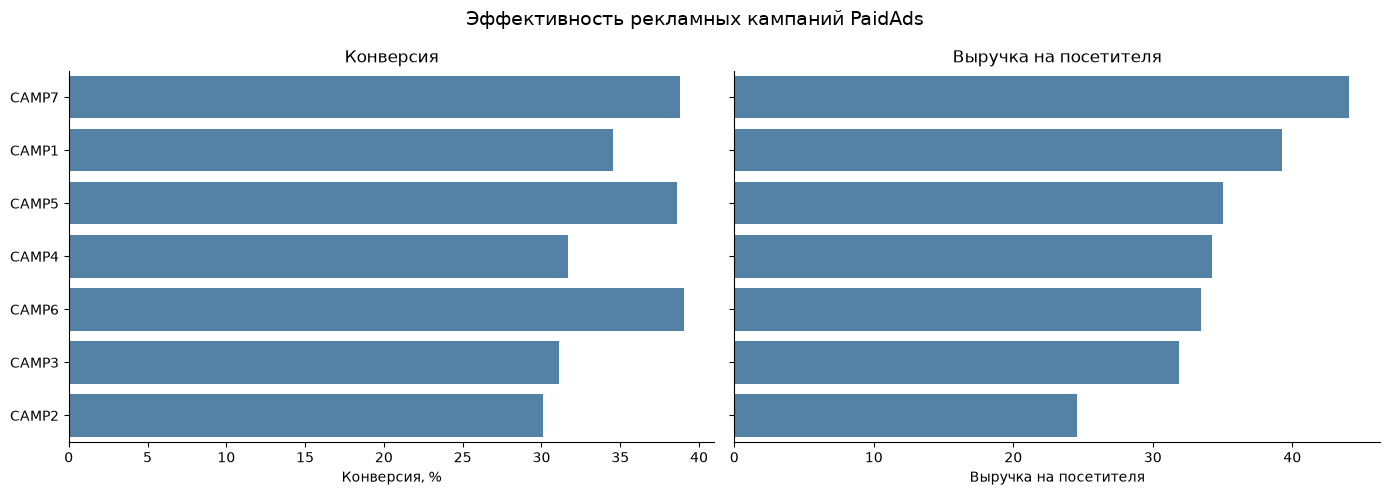

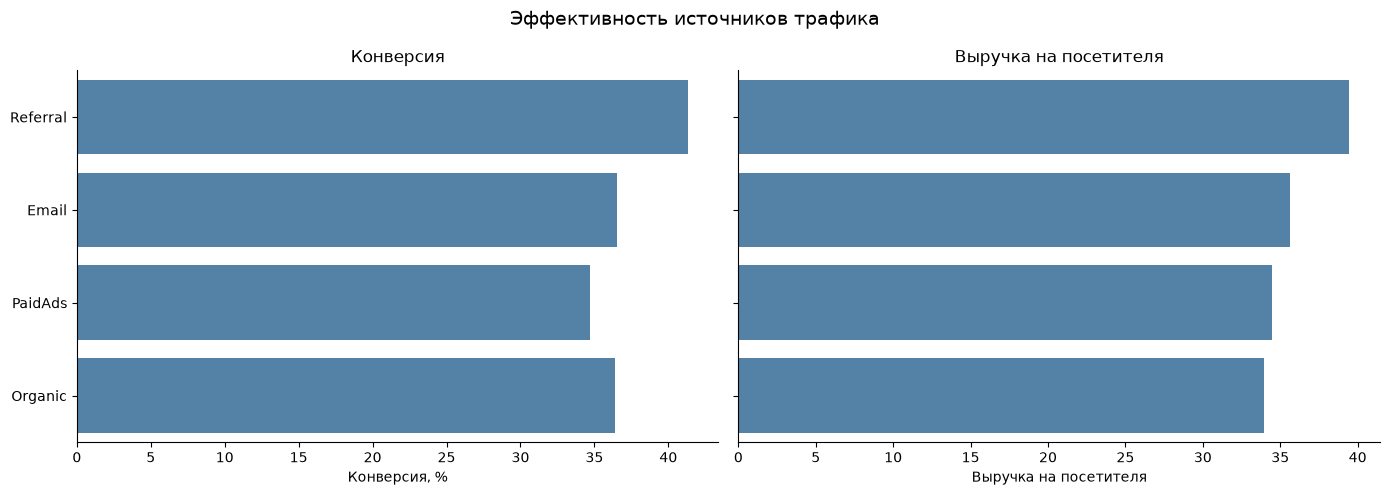

In [54]:
def plot_marketing_metrics(metrics, group_col, title, filename):
    """Построить графики конверсии и выручки на посетителя.

    Args:
        metrics (pd.DataFrame): Таблица рассчитанных бизнес-метрик.
        group_col (str): Название столбца с категориями.
        title (str): Общий заголовок рисунка.
        filename (str): Имя файла для сохранения рисунка.
    """
    # Подготавливаем данные и подписи категорий
    plot_data = metrics.copy()
    plot_data[group_col] = plot_data[group_col].fillna('Без кампании')

    # Создаём два графика с общей осью категорий
    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5),
        sharey=True
    )

    # Отображаем конверсию для каждой категории
    sns.barplot(
        data=plot_data,
        y=group_col,
        x='conversion_pct',
        color='steelblue',
        ax=axes[0]
    )

    axes[0].set(
        title='Конверсия',
        xlabel='Конверсия, %',
        ylabel=''
    )

    # Отображаем выручку на одного посетителя
    sns.barplot(
        data=plot_data,
        y=group_col,
        x='revenue_per_visitor',
        color='steelblue',
        ax=axes[1]
    )

    axes[1].set(
        title='Выручка на посетителя',
        xlabel='Выручка на посетителя',
        ylabel=''
    )

    # Убираем сетку и лишние границы графиков
    for ax in axes:
        ax.grid(False)
        sns.despine(ax=ax)

    # Добавляем общий заголовок и настраиваем расположение
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()

    # Сохраняем рисунок и освобождаем память
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


# Сравниваем рекламные кампании внутри PaidAds
plot_marketing_metrics(
    campaign_metrics[campaign_metrics['campaign'].notna()],
    'campaign',
    'Эффективность рекламных кампаний PaidAds',
    'campaign_performance.png'
)

# Сравниваем все источники трафика
plot_marketing_metrics(
    traffic_metrics,
    'traffic_source',
    'Эффективность источников трафика',
    'traffic_source_performance.png'
)

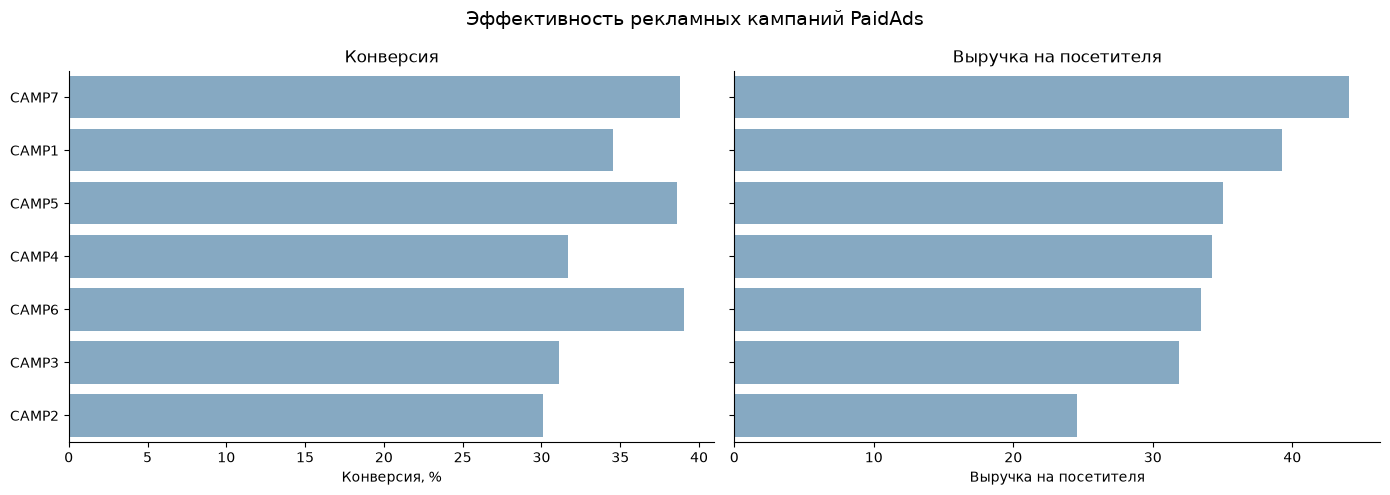

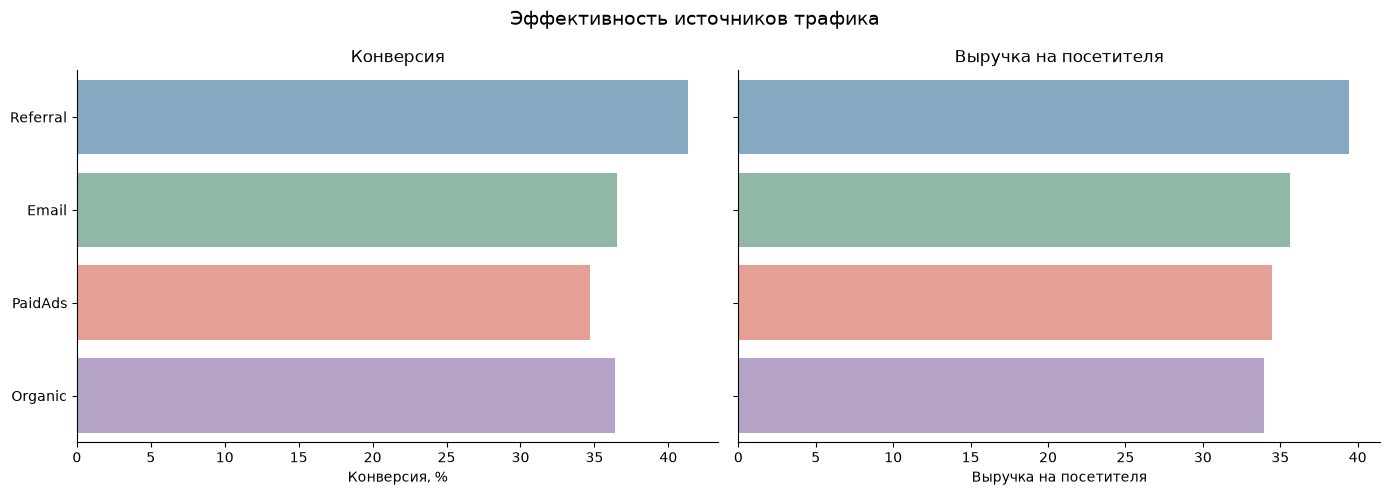

In [55]:
# Палитры для источников трафика и регионов
traffic_palette = {
    'Referral': '#86A9C2',
    'Email': '#91B7A6',
    'PaidAds': '#E5A096',
    'Organic': '#B4A3C7'
}

region_palette = {
    'East': '#86A9C2',
    'South': '#91B7A6',
    'West': '#E5A096',
    'North': '#B4A3C7'
}

def plot_marketing_metrics(metrics, group_col, title, filename, palette=None):
    """Построить графики конверсии и выручки на посетителя.

    Args:
        metrics (pd.DataFrame): Таблица рассчитанных бизнес-метрик.
        group_col (str): Название столбца с категориями.
        title (str): Общий заголовок рисунка.
        filename (str): Имя файла для сохранения рисунка.
        palette (dict | None): Цвета категорий, если заданы.
    """
    # Подготавливаем данные и подписи категорий
    plot_data = metrics.copy()
    plot_data[group_col] = plot_data[group_col].fillna('Без кампании')

    # Определяем цвета категорий
    bar_colors = (
        [palette.get(name, 'steelblue') for name in plot_data[group_col]]
        if palette is not None
        else ['#86A9C2'] * len(plot_data)
    )

    # Создаём два графика с общей осью категорий
    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5),
        sharey=True
    )

    # Отображаем конверсию для каждой категории
    sns.barplot(
        data=plot_data,
        y=group_col,
        x='conversion_pct',
        color='steelblue',
        ax=axes[0]
    )

    axes[0].set(
        title='Конверсия',
        xlabel='Конверсия, %',
        ylabel=''
    )

    # Отображаем выручку на одного посетителя
    sns.barplot(
        data=plot_data,
        y=group_col,
        x='revenue_per_visitor',
        color='steelblue',
        ax=axes[1]
    )

    axes[1].set(
        title='Выручка на посетителя',
        xlabel='Выручка на посетителя',
        ylabel=''
    )

    # Применяем одинаковые цвета категорий к обоим графикам
    for ax in axes:
        for bar, color in zip(ax.patches, bar_colors):
            bar.set_facecolor(color)

        # Убираем сетку и лишние границы графиков
        ax.grid(False)
        sns.despine(ax=ax)

    # Добавляем общий заголовок и настраиваем расположение
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()

    # Сохраняем рисунок и освобождаем память
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


# Сравниваем рекламные кампании внутри PaidAds
plot_marketing_metrics(
    campaign_metrics[campaign_metrics['campaign'].notna()],
    'campaign',
    'Эффективность рекламных кампаний PaidAds',
    'campaign_performance.png'
)

# Сравниваем все источники трафика
plot_marketing_metrics(
    traffic_metrics,
    'traffic_source',
    'Эффективность источников трафика',
    'traffic_source_performance.png',
    palette=traffic_palette
)

#### Выводы по рекламным кампаниям и источникам трафика

**1. Рекламные кампании PaidAds**

- **CAMP7** лидирует по выручке на посетителя (44,08) при конверсии 38,81% и среднем чеке 113,58. Это кампания с самой высокой выручкой на посетителя по выбранному комплексному показателю.
- **CAMP6** показывает максимальную конверсию (39,02%), однако её средний чек сравнительно невысок (85,65). Высокая доля покупателей не всегда обеспечивает максимальную выручку на посетителя.
- **CAMP1** имеет самый высокий средний чек (113,78), но уступает CAMP7 по конверсии и выручке на посетителя.
- **CAMP2** демонстрирует минимальную конверсию (30,08%), средний чек (81,70) и выручку на посетителя (24,58). Кампания требует дополнительного анализа перед принятием решения о перераспределении рекламного бюджета.

**2. Источники трафика**

- **Referral** лидирует по конверсии (41,33%) и выручке на посетителя (39,47). Этот источник стоит изучить подробнее, чтобы понять причины более высокой конверсии и возможности увеличения трафика.
- **PaidAds** имеет самый высокий средний чек (99,30), но самую низкую конверсию (34,69%) среди источников трафика.
- **Email** и **Organic** показывают близкие значения конверсии (36,50% и 36,43% соответственно). При этом Email немного превосходит Organic по выручке на посетителя (35,65 против 33,97). Organic приносит наибольшую общую выручку (74 693,91) благодаря самому большому количеству посетителей (2199), но имеет самую низкую выручку на посетителя (33,97).

**3. Предварительный итог**

Результаты показывают, что эффективность маркетинговых каналов нельзя оценивать только по конверсии или среднему чеку. Выручка на посетителя позволяет учитывать оба показателя одновременно.

Наиболее интересными для дальнейшего изучения выглядят CAMP7 среди платных кампаний и Referral среди источников трафика. CAMP2 заслуживает дополнительной проверки как кампания с наиболее низкими наблюдаемыми показателями.

Однако выявленные различия пока носят описательный характер. Для обоснованных выводов необходимо оценить их статистическую значимость. Кроме того, без данных о маркетинговых расходах нельзя сделать вывод о рентабельности кампаний или рекомендовать конкретное перераспределение бюджета.

#### H.1.2. Проверка статистической значимости различий в конверсии

На предыдущем этапе были обнаружены различия в конверсии между рекламными кампаниями и источниками трафика. Проверим, являются ли эти различия статистически значимыми.

Для анализа используем **критерий χ² Пирсона на независимость**, поскольку обе переменные категориальные:

- `converted` — бинарный признак совершения покупки (0 или 1);
- `campaign` и `traffic_source` — категориальные признаки.

Проверку проведём отдельно для рекламных кампаний внутри `PaidAds` и для всех источников трафика.

**Гипотезы:**

- \(H_0\): конверсия не связана с рекламной кампанией (или источником трафика).
- \(H_1\): между конверсией и рекламной кампанией (или источником трафика) существует статистическая связь.

Уровень значимости:

\[
\alpha = 0.05
\]

**Правило принятия гипотезы:**

- Если \(p < 0.05\), отвергаем \(H_0\).
- Если \(p \geq 0.05\), нет оснований отвергнуть \(H_0\).

Перед интерпретацией проверим ожидаемые частоты в таблицах сопряжённости. Для применения критерия χ² желательно, чтобы ожидаемые частоты во всех ячейках составляли не менее 5.

Критерий позволяет установить наличие статистической связи, но не доказывает причинное влияние маркетингового канала на конверсию.

In [56]:
def test_conversion_independence(data, group_col, alpha=0.05):
    """Проверить независимость конверсии от категориального признака.

    Args:
        data (pd.DataFrame): Данные о посетителях.
        group_col (str): Категориальный признак для проверки.

    Returns:
        dict: Статистика χ², p-value, число степеней свободы
        и минимальная ожидаемая частота.
    """
    # Формируем таблицу сопряжённости: группы × факт покупки
    contingency_table = pd.crosstab(
        data[group_col],
        data['converted']
    )

    # Выполняем критерий χ² Пирсона
    chi2, p_value, dof, expected = stats.chi2_contingency(
        contingency_table,
        correction=False
    )

    # Проверяем минимальную ожидаемую частоту
    min_expected = expected.min()

    # Выводим результаты проверки гипотезы
    print(f'Признак: {group_col}')
    print(f'Статистика χ²: {chi2:.4f}')
    print(f'p-value: {p_value:.4f}')
    print(f'Степени свободы: {dof}')
    print(f'Минимальная ожидаемая частота: {min_expected:.2f}')

    if p_value < alpha:
        print('Результат: H₀ отвергается.')
    else:
        print('Результат: нет оснований отвергнуть H₀.')

    print()

    return {
        'chi2': chi2,
        'p_value': p_value,
        'dof': dof,
        'min_expected': min_expected
    }

# Проверяем связь конверсии с рекламной кампанией
# Только для посетителей источника PaidAds
campaign_chi2 = test_conversion_independence(
    df[df['traffic_source'] == 'PaidAds'],
    'campaign'
)

# Проверяем связь конверсии с источником трафика
# На всей генеральной совокупности
traffic_chi2 = test_conversion_independence(
    df,
    'traffic_source'
)

Признак: campaign
Статистика χ²: 9.2751
p-value: 0.1587
Степени свободы: 6
Минимальная ожидаемая частота: 71.11
Результат: нет оснований отвергнуть H₀.

Признак: traffic_source
Статистика χ²: 7.3451
p-value: 0.0617
Степени свободы: 3
Минимальная ожидаемая частота: 186.73
Результат: нет оснований отвергнуть H₀.



#### Выводы по проверке различий в конверсии

Для проверки связи конверсии с рекламными кампаниями и источниками трафика был применён критерий χ² Пирсона при уровне значимости \(\alpha = 0.05\).

**1. Рекламные кампании PaidAds**

Для рекламных кампаний получили χ² = 9,2751 и p-value = 0,1587. Поскольку p-value превышает 0,05, статистически значимой связи между кампанией и конверсией не обнаружено.

Поскольку \(p = 0.1587 > 0.05\), нет оснований отвергнуть нулевую гипотезу о независимости конверсии от рекламной кампании.

Несмотря на наблюдаемые различия в конверсии между CAMP1–CAMP7, статистически значимая связь не установлена.

**2. Источники трафика**

Для источников трафика получили χ² = 7.3451 и p-value = 0.0617. Поскольку p-value превышает 0,05, статистически значимой связи между источником трафика и конверсией не обнаружено.

Поскольку \(p = 0.0617 > 0.05\), нет оснований отвергнуть нулевую гипотезу о независимости конверсии от источника трафика.

Значение p-value близко к выбранному уровню значимости, однако статистически значимая связь при \(\alpha = 0.05\) не установлена.

**3. Проверка применимости критерия**

Минимальные ожидаемые частоты в обеих таблицах существенно превышают 5, поэтому условие применимости критерия χ² по ожидаемым частотам выполнено.

**Итог**

На основании проведённых проверок нельзя утверждать, что различия в конверсии между рекламными кампаниями или источниками трафика статистически значимы.

Следовательно, наблюдаемые различия в конверсии пока недостаточны для обоснования изменений маркетинговой стратегии. При этом преимущество CAMP7 по выручке на посетителя и Referral по конверсии требует отдельной проверки.

При этом отсутствие статистически значимой связи не доказывает полного отсутствия различий между группами. Полученные результаты могут зависеть от объёма данных и величины реальных эффектов.

Для дальнейшего анализа необходимо отдельно исследовать различия в среднем чеке, поскольку эффективность маркетинговых каналов определяется не только вероятностью покупки, но и суммой заказа.

#### H.1.3. Проверка различий в суммах покупок

Ранее было установлено, что средний чек различается между рекламными кампаниями и источниками трафика. Например, среди кампаний максимальный средний чек наблюдается у CAMP1, а среди источников трафика — у PaidAds.

Проверим, являются ли различия в распределениях сумм покупок статистически значимыми.

Поскольку распределение `purchase_amount` характеризуется выраженной правосторонней асимметрией, используем **непараметрический критерий Краскела — Уоллиса**, который позволяет сравнивать несколько независимых групп без предположения о нормальности распределений.

В анализ включаем только покупателей (`converted = 1`), поскольку средний чек рассчитывается среди совершённых покупок.

**Гипотезы:**

- \(H_0\): распределения сумм покупок одинаковы во всех сравниваемых группах.
- \(H_1\): распределение сумм покупок хотя бы одной группы отличается.

Уровень значимости:

\[
\alpha = 0.05
\]

**Правило принятия гипотезы:**

- Если \(p < 0.05\), отвергаем \(H_0\).
- Если \(p \geq 0.05\), нет оснований отвергнуть \(H_0\).

Критерий Краскела — Уоллиса проверяет различия распределений, а не непосредственно равенство арифметических средних. Поэтому результаты будем интерпретировать совместно со средними чеками и медианами групп.

In [57]:
def test_purchase_differences(data, group_col, alpha=0.05):
    """Проверить различия в суммах покупок между группами.

    Args:
        data (pd.DataFrame): Данные о совершённых покупках.
        group_col (str): Категориальный признак для сравнения.

    Returns:
        dict: Статистика критерия Краскела — Уоллиса,
        p-value и количество сравниваемых групп.
    """
    # Формируем группы сумм покупок без пропущенных значений
    groups = [
        group['purchase_amount'].dropna().to_numpy()
        for _, group in data.groupby(group_col)
    ]

    # Рассчитываем описательные показатели по каждой группе
    group_summary = (
        data.groupby(group_col)['purchase_amount']
        .agg(
            count='count',
            mean='mean',
            median='median',
            std='std'
        )
        .sort_values('mean', ascending=False)
    )

    print(f'Признак: {group_col}')
    display(group_summary.round(2))

    # Проверяем различия распределений критерием Краскела — Уоллиса
    statistic, p_value = stats.kruskal(*groups)

    # Выводим результаты статистического теста
    print(f'Статистика H: {statistic:.4f}')
    print(f'p-value: {p_value:.4f}')
    print(f'Количество групп: {len(groups)}')

    if p_value < alpha:
        print('Результат: H₀ отвергается.')
    else:
        print('Результат: нет оснований отвергнуть H₀.')

    print()

    return {
        'statistic': statistic,
        'p_value': p_value,
        'n_groups': len(groups)
    }


# Проверяем различия в суммах покупок между кампаниями PaidAds
campaign_purchase_test = test_purchase_differences(
    buyers[buyers['traffic_source'] == 'PaidAds'],
    'campaign'
)

# Проверяем различия в суммах покупок между источниками трафика
traffic_purchase_test = test_purchase_differences(
    buyers,
    'traffic_source'
)

Признак: campaign


,count,mean,median,std
campaign,,,,
CAMP1,77,113.78,49.10,182.22
CAMP7,85,113.58,55.60,134.96
CAMP4,70,108.08,56.12,129.57
CAMP3,66,102.51,53.22,105.22
CAMP5,83,90.79,51.50,104.20
CAMP6,80,85.65,54.80,95.33
CAMP2,77,81.70,52.20,85.64


Статистика H: 2.9487
p-value: 0.8153
Количество групп: 7
Результат: нет оснований отвергнуть H₀.

Признак: traffic_source


,count,mean,median,std
traffic_source,,,,
PaidAds,538,99.30,53.40,123.43
Email,269,97.67,55.13,151.57
Referral,212,95.51,53.47,111.93
Organic,801,93.25,50.99,114.10


Статистика H: 1.1789
p-value: 0.7581
Количество групп: 4
Результат: нет оснований отвергнуть H₀.



#### Выводы по проверке различий в суммах покупок

Для сравнения распределений сумм покупок между рекламными кампаниями и источниками трафика использован непараметрический критерий Краскела — Уоллиса при уровне значимости \(\alpha = 0.05\).

**1. Рекламные кампании PaidAds**

Результаты проверки:

- Статистика \(H = 2.9487\).
- p-value = 0.8153.
- Количество групп — 7.

Поскольку \(p = 0.8153 > 0.05\), нет оснований отвергнуть нулевую гипотезу об одинаковых распределениях сумм покупок.

Хотя средний чек варьируется от 81,70 у CAMP2 до 113,78 у CAMP1, медианы значительно ближе друг к другу — от 49,10 до 56,12. Такая разница между средними и медианами согласуется с влиянием отдельных крупных покупок на средний чек.

Особенно заметно высокое стандартное отклонение у CAMP1 (182,22), превышающее средний чек этой кампании.

**2. Источники трафика**

Результаты проверки:

- Статистика \(H = 1.1789\).
- p-value = 0.7581.
- Количество групп — 4.

Поскольку \(p = 0.7581 > 0.05\), нет оснований отвергнуть нулевую гипотезу об одинаковых распределениях сумм покупок.

Средние чеки источников трафика находятся в диапазоне от 93,25 (Organic) до 99,30 (PaidAds), а медианы — от 50,99 до 55,13.

Наибольшая вариативность сумм покупок наблюдается у Email: стандартное отклонение составляет 151,57 при среднем чеке 97,67.

**3. Общий вывод**

Критерий Краскела — Уоллиса не выявил статистически значимых различий между группами ни при сравнении рекламных кампаний, ни при сравнении источников трафика.

Результаты согласуются с ранее обнаруженной правосторонней асимметрией `purchase_amount`: отдельные крупные покупки могут заметно изменять средний чек, тогда как медианы остаются относительно близкими.

Следует учитывать, что критерий Краскела — Уоллиса не проверяет непосредственно равенство арифметических средних. Поэтому отсутствие значимых различий по этому критерию не доказывает равенства средних чеков.

В совокупности с результатами проверки конверсии полученные данные пока не дают достаточных статистических оснований для выбора определённой рекламной кампании или источника трафика как безусловно более эффективного.

### H.2. Региональные различия

**Задача:** исследовать различия в покупательском поведении между регионами и определить, существуют ли основания для региональной сегментации маркетинговой стратегии.

Для каждого региона рассчитаем:

- Количество посетителей и покупателей.
- Конверсию (%).
- Средний чек среди покупателей.
- Общую выручку.
- Выручку на одного посетителя.

Для сравнения регионов будем использовать конверсию и выручку на посетителя, поскольку эти показатели позволяют оценивать результативность независимо от абсолютного размера аудитории.

Дополнительно рассмотрим средний чек, чтобы определить, связаны ли возможные различия в выручке с частотой покупок или их стоимостью.

На первом этапе проведём описательный анализ. Затем проверим статистическую значимость различий в конверсии и распределениях сумм покупок.

**Важно:** даже при обнаружении статистически значимых различий нельзя автоматически утверждать, что регион является их причиной. На показатели могут влиять состав аудитории, источники трафика и другие факторы.

In [58]:
# Рассчитываем бизнес-метрики по регионам
# Используем функцию из подраздела H.1.1
region_metrics = calculate_business_metrics(
    df,
    'region'
)

# Выводим показатели с округлением до двух знаков
print('Бизнес-метрики по регионам')
display(region_metrics.round(2))

Бизнес-метрики по регионам


,region,visitors,buyers,revenue,conversion_pct,avg_order_value,revenue_per_visitor
0,East,1579,555,57877.08,35.15,104.28,36.65
1,South,1235,460,44036.99,37.25,95.73,35.66
2,West,1011,380,34885.70,37.59,91.80,34.51
3,North,1175,425,37839.08,36.17,89.03,32.20


#### Визуализация региональных различий

Для сравнения регионов построим диаграммы конверсии и выручки на посетителя.

Графики позволят определить, совпадают ли регионы с высокой долей покупателей с регионами, обеспечивающими наибольшую выручку на одного посетителя.

Категории расположим по убыванию выручки на посетителя, чтобы сохранить единый подход к визуализации, использованный при анализе рекламных кампаний и источников трафика.

Наблюдаемые различия будем рассматривать как предварительные до проведения статистических проверок.

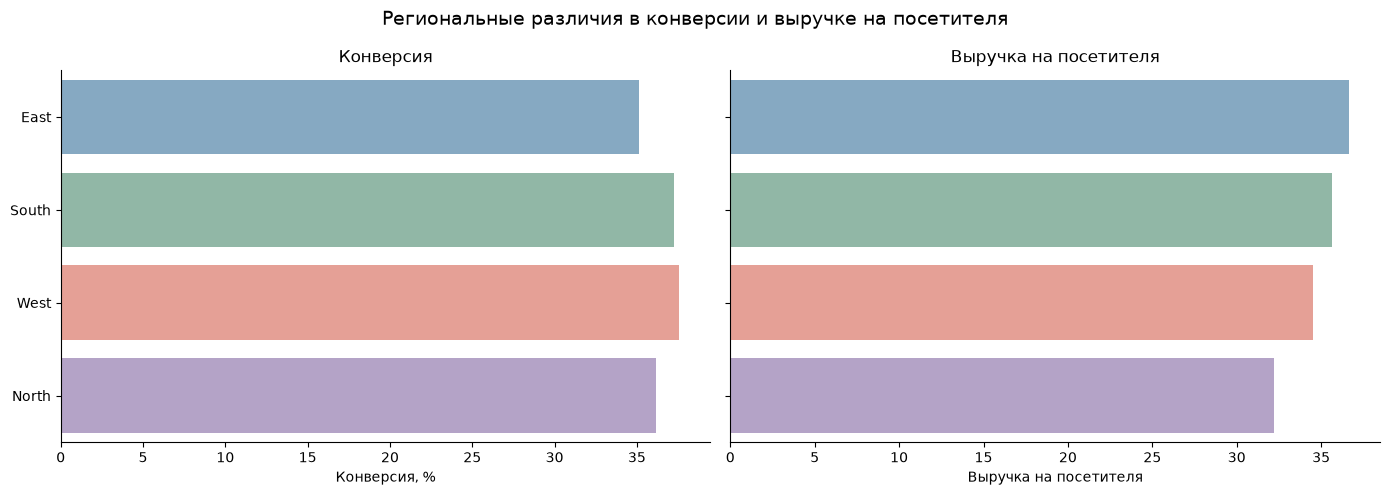

In [59]:
# Строим графики конверсии и выручки на посетителя по регионам
plot_marketing_metrics(
    region_metrics,
    'region',
    'Региональные различия в конверсии и выручке на посетителя',
    'region_performance.png',
    palette=region_palette
)

#### Выводы по региональным различиям

Анализ четырёх регионов показал относительно небольшие различия в конверсии и выручке на посетителя.

- **East** лидирует по выручке на посетителя (36,65) и среднему чеку (104,28), несмотря на минимальную конверсию (35,15%).
- **West** имеет максимальную конверсию (37,59%), однако его средний чек (91,80) ниже, чем у East и South.
- **South** занимает второе место по выручке на посетителя (35,66) при конверсии 37,25%.
- **North** характеризуется минимальной выручкой на посетителя (32,20) и самым низким средним чеком (89,03).

Разница между максимальной и минимальной конверсией составляет 2,44 процентного пункта, а между значениями выручки на посетителя — 4,45.

Таким образом, высокая конверсия не всегда означает более высокую выручку на посетителя. Например, у West конверсия выше, чем у East, но средний чек ниже, поэтому East лидирует по выручке на посетителя.

Однако наблюдаемые различия пока не подтверждены статистическими тестами и не могут служить самостоятельным основанием для изменения региональной маркетинговой стратегии.

#### Проверка статистической значимости региональных различий

Для оценки статистической значимости региональных различий применим два ранее использованных критерия:

1. **Критерий χ² Пирсона** — для проверки связи между регионом и фактом совершения покупки.
2. **Критерий Краскела — Уоллиса** — для сравнения распределений сумм покупок среди покупателей разных регионов.

В обоих случаях используем уровень значимости \(\alpha = 0.05\).

Нулевые гипотезы предполагают соответственно независимость конверсии от региона и одинаковые распределения сумм покупок во всех регионах.

Если \(p < 0.05\), отвергаем соответствующую нулевую гипотезу. В противном случае оснований для её отклонения нет.

In [60]:
# Проверяем статистическую связь конверсии с регионом
region_chi2 = test_conversion_independence(
    df,
    'region'
)

# Сравниваем распределения сумм покупок между регионами
# В анализ включаем только посетителей, совершивших покупку
region_purchase_test = test_purchase_differences(
    buyers,
    'region'
)

Признак: region
Статистика χ²: 2.0920
p-value: 0.5535
Степени свободы: 3
Минимальная ожидаемая частота: 368.00
Результат: нет оснований отвергнуть H₀.

Признак: region


,count,mean,median,std
region,,,,
East,555,104.28,61.59,135.27
South,460,95.73,49.92,131.54
West,380,91.80,53.70,106.53
North,425,89.03,46.33,108.20


Статистика H: 21.1878
p-value: 0.0001
Количество групп: 4
Результат: H₀ отвергается.



#### Выводы по статистической проверке региональных различий

**1. Конверсия**

Результаты критерия χ² Пирсона:

- \(\chi^2 = 2.0920\).
- \(p = 0.5535\).
- Число степеней свободы — 3.
- Минимальная ожидаемая частота — 368,00.

Поскольку \(p > 0.05\), нет оснований отвергнуть нулевую гипотезу о независимости конверсии от региона.

Статистически значимой связи между регионом и конверсией не обнаружено, несмотря на наблюдаемые различия от 35,15% (East) до 37,59% (West).

**2. Суммы покупок**

Результаты критерия Краскела — Уоллиса:

- \(H = 21.1878\).
- \(p = 0.0001\).
- Количество групп — 4.

Поскольку \(p < 0.05\), нулевая гипотеза об одинаковых распределениях сумм покупок во всех регионах отвергается.

Таким образом, обнаружены статистически значимые различия в распределениях сумм покупок как минимум между некоторыми регионами.

East имеет наибольший средний чек (104,28) и медиану покупки (61,59), тогда как North характеризуется минимальными значениями этих показателей (89,03 и 46,33 соответственно).

Однако общий критерий Краскела — Уоллиса не определяет, между какими именно регионами существуют значимые различия, и не проверяет непосредственно равенство средних чеков.

**3. Общий вывод**

Статистически значимой связи между регионом и конверсией не обнаружено. При этом распределения сумм покупок среди покупателей разных регионов статистически значимо различаются.

Это позволяет рассматривать региональную сегментацию по стоимости покупок как перспективное направление дальнейшего анализа.

Прежде чем рекомендовать изменение региональной маркетинговой стратегии, необходимо определить, какие именно пары регионов различаются статистически значимо.

#### Попарное сравнение распределений сумм покупок по регионам

После обнаружения статистически значимых различий с помощью критерия Краскела — Уоллиса проведём попарные сравнения регионов.

Используем двусторонний критерий Манна — Уитни для независимых выборок.

**Гипотезы для каждой пары:**

- \(H_0\): распределения сумм покупок в двух регионах одинаковы.
- \(H_1\): распределения сумм покупок различаются.

Поскольку выполняется шесть сравнений, применим **поправку Холма**, чтобы контролировать вероятность ложноположительных результатов при множественном тестировании.

Скорректированные p-value сравним с уровнем значимости \(alpha = 0.05\).

In [61]:
# Получаем названия регионов для всех попарных сравнений
regions = sorted(buyers['region'].dropna().unique())

pairwise_results = []

# Сравниваем распределения сумм покупок для каждой пары регионов
for region_a, region_b in combinations(regions, 2):
    purchases_a = buyers.loc[
        buyers['region'] == region_a, 'purchase_amount'
    ].dropna()

    purchases_b = buyers.loc[
        buyers['region'] == region_b, 'purchase_amount'
    ].dropna()

    # Выполняем двусторонний критерий Манна — Уитни
    statistic, p_value = stats.mannwhitneyu(
        purchases_a,
        purchases_b,
        alternative='two-sided'
    )

    # Сохраняем статистику и описательные показатели
    pairwise_results.append({
        'region_a': region_a,
        'region_b': region_b,
        'median_a': purchases_a.median(),
        'median_b': purchases_b.median(),
        'U_statistic': statistic,
        'p_value': p_value
    })

# Формируем таблицу результатов
region_pairwise = pd.DataFrame(pairwise_results)

# Корректируем p-value методом Холма
region_pairwise['p_adjusted'] = multipletests(
    region_pairwise['p_value'],
    method='holm'
)[1]

# Отмечаем статистически значимые различия
region_pairwise['significant'] = (
    region_pairwise['p_adjusted'] < 0.05
)

# Сортируем пары по скорректированному p-value
region_pairwise = region_pairwise.sort_values(
    'p_adjusted'
).reset_index(drop=True)

# Создаём копию таблицы для отображения
display_table = region_pairwise.copy()

# Форматируем p-value, сохраняя маленькие значения
for col in ['p_value', 'p_adjusted']:
    display_table[col] = display_table[col].map(lambda x: f'{x:.4g}')

display(display_table.round(2))

,region_a,region_b,median_a,median_b,U_statistic,p_value,p_adjusted,significant
0,East,North,61.59,46.33,136014.50,3.846e-05,0.0002308,True
1,East,South,61.59,49.92,144723.00,0.0002406,0.001203,True
2,East,West,61.59,53.70,115141.00,0.01688,0.06753,False
3,North,West,46.33,53.70,75894.00,0.1404,0.4212,False
4,North,South,46.33,49.92,95242.50,0.5093,0.6673,False
5,South,West,49.92,53.70,84015.50,0.3336,0.6673,False


#### Выводы по попарному сравнению регионов

После обнаружения статистически значимых различий между регионами с помощью критерия Краскела — Уоллиса были проведены шесть попарных сравнений критерием Манна — Уитни с поправкой Холма.

**Статистически значимые различия выявлены для двух пар:**

- **East — North:** медиана покупки в East составляет 61,59, в North — 46,33.
- **East — South:** медиана покупки в East составляет 61,59, в South — 49,92.

В обеих парах East характеризуется более высокой наблюдаемой медианой покупки.

Для пары East — West скорректированное p-value составляет приблизительно 0,07, поэтому различие не достигает уровня статистической значимости 0,05. Между остальными парами регионов статистически значимых различий также не обнаружено.

**Итог по региональному анализу**

Проведённые исследования показывают, что:

1. Статистически значимая связь между регионом и конверсией не обнаружена (\(p = 0.5535\)).
2. Распределения сумм покупок статистически значимо различаются между регионами (\(p = 0.0001\)).
3. Попарные сравнения с поправкой Холма выявили различия между East и двумя регионами — North и South.
4. East имеет максимальный средний чек (104,28), медиану покупки (61,59) и выручку на посетителя (36,65).

Таким образом, **East представляет интерес для дальнейшего изучения: здесь наблюдаются наиболее высокие суммы покупок, а различия с North и South подтверждены статистически**. Однако это ещё не означает, что увеличение маркетинговых расходов в регионе приведёт к росту прибыли.

Кроме того, проведённые непараметрические тесты подтверждают различия распределений, а не непосредственно арифметических средних чеков. Для решений о перераспределении бюджета необходимо дополнительно учитывать стоимость привлечения клиентов, маржинальность и возможные различия в составе аудитории.

### H.3. Время на сайте и глубина просмотра

**Задача:** исследовать связь поведенческих характеристик посетителей с вероятностью совершения покупки и величиной среднего чека.

Рассмотрим два показателя:

- `time_on_site_s` — время пребывания посетителя на сайте в секундах;
- `pages_visited` — количество просмотренных страниц.

Анализ проведём в несколько этапов:

1. Сравним среднее и медианное время на сайте, а также количество просмотренных страниц между покупателями и посетителями без покупки.
2. Проверим статистическую значимость различий между этими группами.
3. Исследуем связь поведенческих показателей с суммой покупки среди покупателей.
4. Оценим возможности использования полученных результатов для поведенческой сегментации.

Поскольку распределения поведенческих показателей уже рассматривались в разделе A, повторно строить их общие гистограммы не будем.

**Ограничение интерпретации:** обнаруженная статистическая связь не означает причинно-следственную зависимость. Например, более длительное пребывание на сайте может быть связано с намерением совершить покупку, но само по себе не обязательно увеличивает вероятность конверсии.

#### H.3.1. Описательный анализ поведенческих показателей

Сравним время на сайте и количество просмотренных страниц в двух группах:

- посетители без покупки (`converted = 0`);
- покупатели (`converted = 1`).

Для каждого показателя рассчитаем количество наблюдений, среднее, медиану и стандартное отклонение.

Такое сравнение позволит предварительно оценить, отличаются ли поведенческие характеристики покупателей от характеристик остальных посетителей.

In [62]:
# Рассчитываем описательные статистики поведенческих показателей
# отдельно для покупателей и посетителей без покупки
behavior_summary = (
    df.groupby('converted')[
        ['time_on_site_s', 'pages_visited']
    ]
    .agg(['count', 'mean', 'median', 'std'])
)

# Преобразуем многоуровневые названия столбцов в обычные
behavior_summary.columns = [
    f'{variable}_{statistic}'
    for variable, statistic in behavior_summary.columns
]

# Добавляем понятные названия групп
behavior_summary.index = behavior_summary.index.map({
    0: 'Без покупки',
    1: 'Покупатели'
})

# Выводим результаты с округлением до двух знаков
display(behavior_summary.round(2))

,time_on_site_s_count,time_on_site_s_mean,time_on_site_s_median,time_on_site_s_std,pages_visited_count,pages_visited_mean,pages_visited_median,pages_visited_std
converted,,,,,,,,
Без покупки,3180,285.04,245.70,189.48,3180,6.01,6.00,2.26
Покупатели,1820,496.12,439.65,297.17,1820,5.95,6.00,2.24


#### Предварительные выводы по поведенческим показателям

Сравнение покупателей и посетителей без покупки выявило заметные различия во времени пребывания на сайте.

**1. Время на сайте**

- Покупатели проводят на сайте в среднем 496,12 секунды, посетители без покупки — 285,04 секунды.
- Разница средних составляет 211,08 секунды (около 3,5 минуты).
- Медианное время также выше у покупателей: 439,65 против 245,70 секунды.
- Стандартное отклонение времени у покупателей выше (297,17 против 189,48 секунды), что указывает на большую вариативность поведения.

Таким образом, покупатели в среднем проводят на сайте значительно больше времени, чем посетители без покупки.

**2. Количество просмотренных страниц**

- Среднее количество просмотренных страниц практически одинаково: 5,95 у покупателей и 6,01 у посетителей без покупки.
- Медиана в обеих группах составляет 6 страниц.
- Стандартные отклонения также близки: 2,24 и 2,26 соответственно.

Следовательно, на описательном уровне глубина просмотра не демонстрирует выраженных различий между группами.

**Предварительный итог**

По результатам описательного анализа время на сайте выглядит более перспективным показателем для изучения связи с конверсией, чем количество просмотренных страниц.

Однако необходимо проверить статистическую значимость обнаруженных различий. Кроме того, длительное пребывание на сайте может быть следствием процесса оформления покупки, поэтому причинное влияние времени на конверсию пока не установлено.

#### Визуализация поведенческих различий между покупателями и посетителями без покупки

Для более подробного сравнения поведенческих характеристик построим два графика:

1. **Распределение времени на сайте** — с помощью KDE-кривых сравним форму распределений и диапазоны значений в двух группах.
2. **Распределение количества просмотренных страниц** — с помощью столбчатых диаграмм сравним относительные частоты значений.

Использование относительных частот необходимо, поскольку численность покупателей (1820) и посетителей без покупки (3180) различается.

Графики позволят оценить, насколько распределения поведенческих показателей различаются между группами и подтверждают ли визуальные наблюдения результаты описательной статистики.

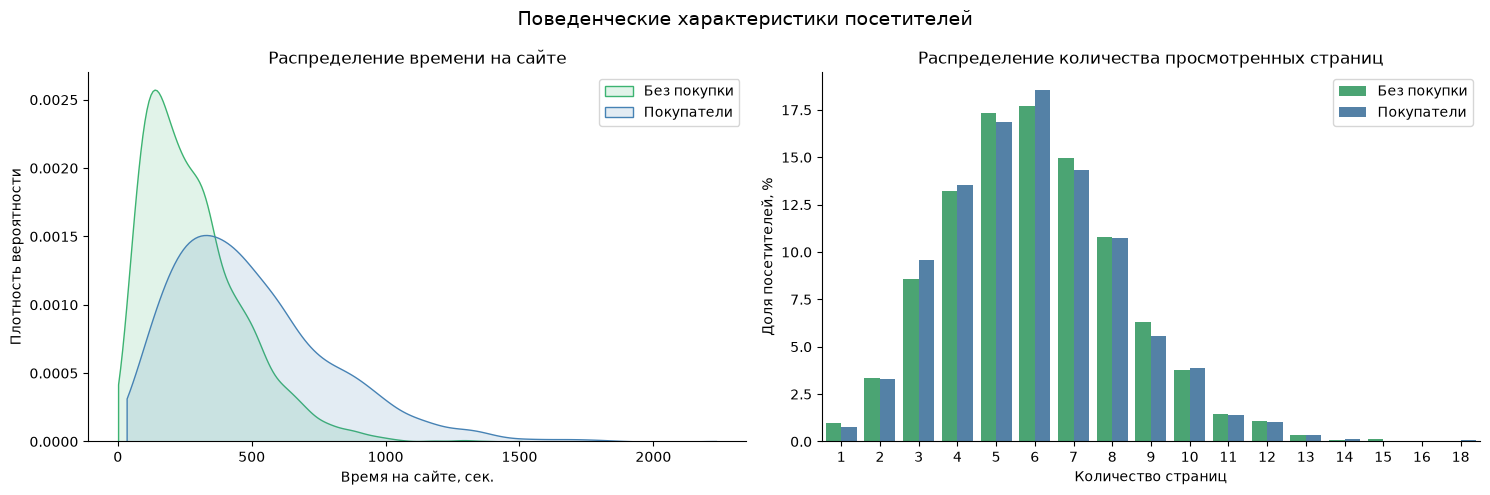

In [63]:
# Подготавливаем данные отдельно для покупателей и посетителей без покупки
non_buyers = df[df['converted'] == 0]
buyers_behavior = df[df['converted'] == 1]

# Создаём рисунок с двумя графиками
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Сравниваем распределения времени на сайте
sns.kdeplot(
    data=non_buyers,
    x='time_on_site_s',
    color='mediumseagreen',
    label='Без покупки',
    fill=True,
    alpha=0.15,
    ax=axes[0],
    cut=0
)

sns.kdeplot(
    data=buyers_behavior,
    x='time_on_site_s',
    color='steelblue',
    label='Покупатели',
    fill=True,
    alpha=0.15,
    ax=axes[0],
    cut=0
)

axes[0].set(
    title='Распределение времени на сайте',
    xlabel='Время на сайте, сек.',
    ylabel='Плотность вероятности'
)
axes[0].legend()

# Рассчитываем относительные частоты количества страниц
# отдельно внутри каждой группы
pages_distribution = (
    df.groupby('converted')['pages_visited']
    .value_counts(normalize=True)
    .mul(100)
    .rename('percentage')
    .reset_index()
)

# Присваиваем группам понятные названия
pages_distribution['group'] = pages_distribution['converted'].map({
    0: 'Без покупки',
    1: 'Покупатели'
})

# Сравниваем распределения количества просмотренных страниц
sns.barplot(
    data=pages_distribution,
    x='pages_visited',
    y='percentage',
    hue='group',
    hue_order=['Без покупки', 'Покупатели'],
    palette={
        'Без покупки': 'mediumseagreen',
        'Покупатели': 'steelblue'
    },
    ax=axes[1]
)

axes[1].set(
    title='Распределение количества просмотренных страниц',
    xlabel='Количество страниц',
    ylabel='Доля посетителей, %'
)
axes[1].legend(title='')

# Убираем сетку и лишние границы
for ax in axes:
    ax.grid(False)
    sns.despine(ax=ax)

# Настраиваем расположение графиков
fig.suptitle(
    'Поведенческие характеристики посетителей',
    fontsize=14
)
fig.tight_layout()

# Сохраняем рисунок
fig.savefig(
    FIGURES_DIR / 'behavior_by_conversion.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

#### Выводы по визуализации поведенческих характеристик

**1. Время пребывания на сайте**

Распределение времени на сайте у покупателей заметно смещено вправо относительно распределения посетителей без покупки.

- У покупателей распределение времени смещено в сторону более высоких значений.
- Распределение времени у покупателей более растянуто и характеризуется длинным правым хвостом.
- У посетителей без покупки наблюдается более выраженная концентрация относительно небольших значений времени.

Визуальные результаты согласуются с описательной статистикой: среднее время на сайте составляет 496,12 секунды у покупателей против 285,04 секунды у посетителей без покупки.

**2. Количество просмотренных страниц**

Распределения количества просмотренных страниц практически совпадают:

- В обеих группах наиболее распространены значения около 5–6 страниц.
- Форма распределений и относительные частоты близки.
- Среднее количество страниц составляет 5,95 у покупателей и 6,01 у посетителей без покупки.

Таким образом, количество просмотренных страниц не демонстрирует выраженной визуальной связи с фактом покупки.

**Предварительный вывод**

Время пребывания на сайте выглядит более перспективным признаком для анализа конверсии, чем глубина просмотра.

Однако графики не позволяют оценить статистическую значимость различий. Для подтверждения наблюдений необходимо провести статистические тесты.

Кроме того, более длительное пребывание на сайте не обязательно является причиной покупки: оно может быть связано с самим процессом выбора товара и оформления заказа.

#### H.3.2. Проверка статистической значимости поведенческих различий

Для проверки различий между покупателями и посетителями без покупки используем **двусторонний критерий Манна — Уитни**.

Проверку проведём отдельно для времени на сайте (`time_on_site_s`) и количества просмотренных страниц (`pages_visited`).

**Гипотезы:**

- \(H_0\): распределения поведенческого показателя одинаковы у покупателей и посетителей без покупки.
- \(H_1\): распределения поведенческого показателя различаются.

Уровень значимости — \(\alpha = 0.05\).

Поскольку проверяются два поведенческих показателя, применим поправку Холма для контроля множественных сравнений.

Критерий оценивает различия распределений, а не непосредственно разницу средних значений.

In [64]:
# Задаём поведенческие показатели для статистической проверки
behavior_features = ['time_on_site_s', 'pages_visited']

behavior_test_results = []

# Сравниваем покупателей и посетителей без покупки
# отдельно по каждому поведенческому показателю
for feature in behavior_features:
    non_buyer_values = df.loc[
        df['converted'] == 0, feature
    ].dropna()

    buyer_values = df.loc[
        df['converted'] == 1, feature
    ].dropna()

    # Выполняем двусторонний критерий Манна — Уитни
    statistic, p_value = stats.mannwhitneyu(
        buyer_values,
        non_buyer_values,
        alternative='two-sided'
    )

    # Сохраняем результаты проверки
    behavior_test_results.append({
        'feature': feature,
        'U_statistic': statistic,
        'p_value': p_value
    })

# Формируем таблицу результатов
behavior_tests = pd.DataFrame(behavior_test_results)

# Корректируем p-value методом Холма
behavior_tests['p_adjusted'] = multipletests(
    behavior_tests['p_value'],
    method='holm'
)[1]

# Определяем статистически значимые различия
behavior_tests['significant'] = (
    behavior_tests['p_adjusted'] < 0.05
)

# Выводим результаты без преждевременного округления p-value
# Создаём копию таблицы для отображения
display_table = behavior_tests.copy()

# Форматируем p-value без потери маленьких значений
for col in ['p_value', 'p_adjusted']:
    display_table[col] = display_table[col].map(lambda x: f'{x:.4g}')

# Округляем остальные числовые значения
display(display_table.round(2))

,feature,U_statistic,p_value,p_adjusted,significant
0,time_on_site_s,4226258.50,4.238e-162,8.477e-162,True
1,pages_visited,2850525.50,0.3737,0.3737,False


#### Выводы по статистической проверке поведенческих различий

Для сравнения покупателей и посетителей без покупки использован двусторонний критерий Манна — Уитни с поправкой Холма на множественные сравнения. Уровень значимости — \(\alpha = 0.05\).

**1. Время пребывания на сайте (`time_on_site_s`)**

- Статистика \(U = 4\,226\,258.50\).
- Скорректированное \(p < 0.001\).
- Различия статистически значимы.

Нулевая гипотеза об одинаковых распределениях времени на сайте отвергается.

Покупатели проводят на сайте в среднем 496,12 секунды, а посетители без покупки — 285,04 секунды. Медианы также заметно различаются: 439,65 против 245,70 секунды.

Таким образом, обнаружена статистически значимая связь между временем пребывания на сайте и фактом совершения покупки.

**2. Количество просмотренных страниц (`pages_visited`)**

- Статистика \(U = 2\,850\,525.50\).
- Скорректированное \(p = 0.37\).
- Статистически значимые различия не обнаружены.

Нет оснований отвергнуть нулевую гипотезу об одинаковых распределениях количества просмотренных страниц.

Средние значения практически совпадают: 5,95 страницы у покупателей и 6,01 у посетителей без покупки. Медиана в обеих группах составляет 6 страниц.

**3. Общий вывод**

Время пребывания на сайте статистически значимо связано с фактом совершения покупки и представляет интерес для дальнейшего анализа поведенческой сегментации.

Количество просмотренных страниц не показало статистически значимых различий между покупателями и посетителями без покупки.

Однако полученные результаты не доказывают, что увеличение времени пребывания на сайте приводит к росту конверсии. Более длительное посещение может быть следствием выбора товара или оформления покупки.

#### H.3.3. Корреляция поведенческих показателей с суммой покупки

Проверим, связаны ли время пребывания на сайте (`time_on_site_s`) и количество просмотренных страниц (`pages_visited`) с суммой покупки (`purchase_amount`).

В анализ включим только покупателей (`converted = 1`), поскольку для посетителей без покупки сумма заказа равна нулю.

Используем **коэффициент ранговой корреляции Спирмена** (\(\rho\)), подходящий для исследования монотонных связей при асимметричных распределениях.

**Гипотезы для каждого показателя:**

- \(H_0\): ранговая корреляция между поведенческим показателем и суммой покупки равна нулю.
- \(H_1\): ранговая корреляция отличается от нуля.

Уровень значимости — \(\alpha = 0.05\). Для двух проверок применим поправку Холма.

Помимо статистической значимости оценим величину коэффициента корреляции: при большом объёме данных даже слабая связь может оказаться статистически значимой.

In [65]:
# Задаём поведенческие признаки для корреляционного анализа
behavior_features = ['time_on_site_s', 'pages_visited']

correlation_results = []

# Рассчитываем корреляцию Спирмена с суммой покупки
# отдельно для каждого признака среди покупателей
for feature in behavior_features:
    # Исключаем наблюдения с пропусками в анализируемых столбцах
    subset = buyers[[feature, 'purchase_amount']].dropna()

    # Рассчитываем коэффициент корреляции и p-value
    rho, p_value = stats.spearmanr(
        subset[feature],
        subset['purchase_amount']
    )

    # Сохраняем результаты проверки
    correlation_results.append({
        'feature': feature,
        'n': len(subset),
        'spearman_rho': rho,
        'p_value': p_value
    })

# Формируем таблицу результатов корреляционного анализа
behavior_correlations = pd.DataFrame(correlation_results)

# Применяем поправку Холма на две проверки
behavior_correlations['p_adjusted'] = multipletests(
    behavior_correlations['p_value'],
    method='holm'
)[1]

# Определяем статистическую значимость корреляций
behavior_correlations['significant'] = (
    behavior_correlations['p_adjusted'] < 0.05
)

# Выводим коэффициенты с четырьмя знаками после запятой
# Создаём копию таблицы для отображения
display_table = behavior_correlations.copy()

# Форматируем p-value
for col in ['p_value', 'p_adjusted']:
    display_table[col] = display_table[col].map(lambda x: f'{x:.4g}')

# Округляем остальные числовые показатели
display(display_table.round(4))

,feature,n,spearman_rho,p_value,p_adjusted,significant
0,time_on_site_s,1820,0.02,0.3343,0.5665,False
1,pages_visited,1820,0.03,0.2832,0.5665,False


#### Выводы по корреляционному анализу поведенческих показателей

Для исследования связи времени на сайте и количества просмотренных страниц с суммой покупки использован коэффициент ранговой корреляции Спирмена. Анализ проведён среди 1820 покупателей с поправкой Холма на множественные проверки.

**1. Время на сайте (`time_on_site_s`)**

- Коэффициент Спирмена: \(\rho \approx 0.02\).
- Скорректированное p-value: 0.57.
- Статистически значимая корреляция не обнаружена.

Коэффициент близок к нулю, что указывает на очень слабую монотонную связь между временем пребывания на сайте и суммой покупки.

**2. Количество просмотренных страниц (`pages_visited`)**

- Коэффициент Спирмена: \(\rho \approx 0.03\).
- Скорректированное p-value: 0.57.
- Статистически значимая корреляция не обнаружена.

Количество просмотренных страниц также не демонстрирует заметной монотонной связи с суммой покупки.

**3. Общий вывод**

Проведённый анализ позволяет разграничить два аспекта покупательского поведения:

- **Факт покупки:** время пребывания на сайте статистически значимо различается между покупателями и посетителями без покупки, тогда как количество просмотренных страниц — нет.
- **Сумма покупки:** ни время пребывания на сайте, ни количество просмотренных страниц не показали статистически значимой монотонной связи с велич

#### H.3.4. Сегментация посетителей по времени на сайте

Предыдущий анализ показал, что время пребывания на сайте статистически значимо различается между покупателями и посетителями без покупки. При этом значимой монотонной связи времени с суммой покупки среди покупателей не обнаружено.

Для более подробного изучения связи времени на сайте с конверсией разделим посетителей на пять групп по квинтилям распределения `time_on_site_s`.

Для каждого сегмента рассчитаем:

- количество посетителей;
- количество покупателей;
- минимальное и максимальное время пребывания на сайте;
- конверсию (%).

Квинтильная сегментация обеспечивает приблизительно одинаковую численность групп и позволяет оценить, как меняется наблюдаемая доля покупателей при увеличении времени пребывания на сайте.

**Ограничение:** показатель `time_on_site_s` отражает продолжительность посещения, но в данных не указано, в какой момент была совершена покупка. Поэтому выявленные интервалы нельзя автоматически использовать как пороги для рекламного таргетирования в реальном времени.

In [66]:
# Создаём отдельный датафрейм для поведенческой сегментации
behavior_segments = df.copy()

# Делим посетителей на пять групп по квинтилям времени на сайте
# Нумеруем сегменты от 1 (самые короткие визиты) до 5
behavior_segments['time_segment'] = pd.qcut(
    behavior_segments['time_on_site_s'],
    q=5,
    labels=[1, 2, 3, 4, 5]
)

# Рассчитываем численность, границы времени и конверсию по сегментам
time_segment_metrics = (
    behavior_segments.groupby('time_segment', observed=True)
    .agg(
        visitors=('customer_id', 'count'),
        buyers=('converted', 'sum'),
        min_time_s=('time_on_site_s', 'min'),
        max_time_s=('time_on_site_s', 'max')
    )
    .reset_index()
)

# Рассчитываем долю покупателей в каждом сегменте
time_segment_metrics['conversion_pct'] = (
    time_segment_metrics['buyers']
    / time_segment_metrics['visitors']
    * 100
)

# Выводим таблицу с округлением до двух знаков
display(time_segment_metrics.round(2))

,time_segment,visitors,buyers,min_time_s,max_time_s,conversion_pct
0,1,1001,134,1.00,147.10,13.39
1,2,1000,250,147.20,249.50,25.00
2,3,999,319,249.80,362.00,31.93
3,4,1000,441,362.40,536.50,44.10
4,5,1000,676,536.90,2235.30,67.60


#### Предварительные результаты сегментации по времени на сайте

Разделение посетителей на пять квинтильных групп выявило последовательное увеличение конверсии с ростом продолжительности посещения:

- **Сегмент 1 (1,0–147,1 сек.):** конверсия 13,39%.
- **Сегмент 2 (147,2–249,5 сек.):** конверсия 25,00%.
- **Сегмент 3 (249,8–362,0 сек.):** конверсия 31,93%.
- **Сегмент 4 (362,4–536,5 сек.):** конверсия 44,10%.
- **Сегмент 5 (536,9–2235,3 сек.):** конверсия 67,60%.

Разница между крайними сегментами составляет 54,21 процентного пункта. Конверсия в группе наиболее длительных посещений примерно в пять раз выше, чем в группе самых коротких.

Полученные результаты показывают, что с увеличением продолжительности посещения наблюдаемая конверсия последовательно возрастает.

Однако время посещения может включать выбор товара и оформление заказа. Поэтому результаты нельзя интерпретировать как доказательство того, что искусственное увеличение времени на сайте повысит вероятность покупки.

Для использования временных сегментов в маркетинговых сценариях необходимо отдельно исследовать поведение посетителей до момента конверсии.

#### Визуализация конверсии по временным сегментам

Построим линейный график конверсии для пяти групп посетителей, сформированных по квинтилям времени на сайте. Это позволит наглядно показать, как меняется доля покупателей от первого сегмента к пятому.

Для сравнения добавим горизонтальную линию общей конверсии по датасету (36,40%). Это позволит определить, какие сегменты имеют наблюдаемую конверсию выше или ниже общего уровня.

График носит описательный характер и не устанавливает причинной зависимости между временем посещения и совершением покупки.

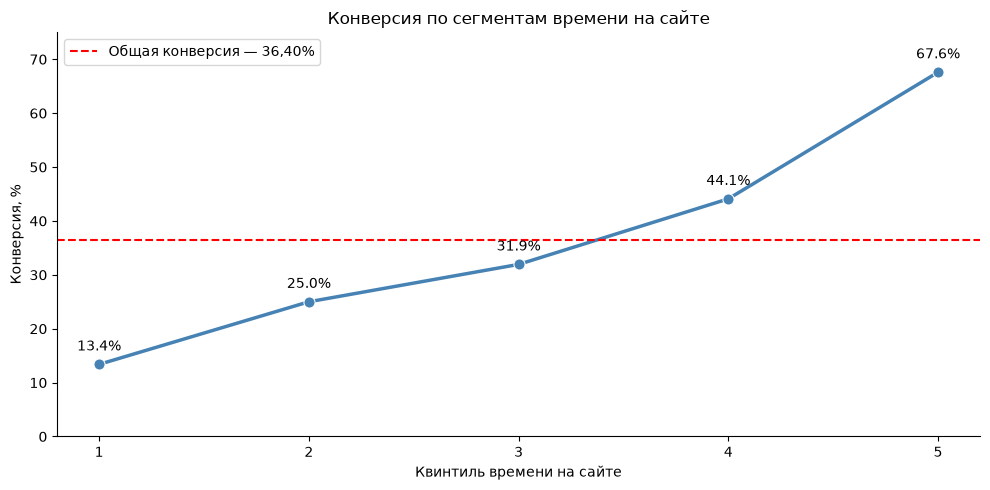

In [67]:
# Подготавливаем числовые значения сегментов для линейного графика
plot_data = time_segment_metrics.copy()
plot_data['time_segment'] = plot_data['time_segment'].astype(int)

# Строим линейный график конверсии по квинтилям времени на сайте
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=time_segment_metrics,
    x='time_segment',
    y='conversion_pct',
    color='steelblue',
    marker='o',
    markersize=8,
    linewidth=2.5,
    ax=ax
)

# Добавляем линию общей конверсии
ax.axhline(
    df['converted'].mean() * 100,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Общая конверсия — 36,40%'
)

# Подписываем значения конверсии рядом с точками
for _, row in time_segment_metrics.iterrows():
    ax.annotate(
        f"{row['conversion_pct']:.1f}%",
        (row['time_segment'], row['conversion_pct']),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center'
    )

# Настраиваем оси, заголовок и легенду
ax.set(
    title='Конверсия по сегментам времени на сайте',
    xlabel='Квинтиль времени на сайте',
    ylabel='Конверсия, %',
    ylim=(0, 75)
)

ax.set_xticks([1, 2, 3, 4, 5])
ax.legend()

# Убираем сетку и лишние границы
ax.grid(False)
sns.despine(ax=ax)

# Сохраняем график
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / 'conversion_by_time_segment.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

#### Общие выводы по разделу H.3

Анализ поведенческих характеристик посетителей показал, что время пребывания на сайте и количество просмотренных страниц по-разному связаны с покупательским поведением.

**1. Время на сайте и конверсия**

Покупатели проводят на сайте в среднем 496,12 секунды, тогда как посетители без покупки — 285,04 секунды. Различия распределений статистически значимы по критерию Манна — Уитни с поправкой Холма (\(p < 0.001\)).

Сегментация по квинтилям выявила последовательное увеличение конверсии с 13,39% в группе самых коротких посещений до 67,60% в группе самых длительных посещений.

Таким образом, более длительные посещения связаны с существенно более высокой наблюдаемой конверсией.

**2. Глубина просмотра и конверсия**

Среднее количество просмотренных страниц практически одинаково у покупателей (5,95) и посетителей без покупки (6,01).

Критерий Манна — Уитни не выявил статистически значимых различий (\(p_{\text{adj}} = 0.37\)).

Следовательно, количество просмотренных страниц не показало убедительной связи с фактом покупки в рамках проведённого анализа.

**3. Поведенческие показатели и сумма покупки**

Корреляционный анализ Спирмена среди 1820 покупателей не обнаружил статистически значимой монотонной связи суммы покупки:

- со временем на сайте (\(\rho \approx 0.02\));
- с количеством просмотренных страниц (\(\rho \approx 0.03\)).

Скорректированное p-value для обоих показателей составляет приблизительно 0,57.

Таким образом, более длительное посещение связано с более высокой наблюдаемой конверсией, однако статистически значимой монотонной связи между продолжительностью посещения и суммой покупки среди покупателей не обнаружено.

**4. Практическая интерпретация**

Время пребывания на сайте можно рассматривать как потенциальный признак для разработки поведенческой сегментации. Однако использовать рассчитанные временные интервалы непосредственно для таргетирования пока нельзя: данные не позволяют определить, какая часть времени была проведена на сайте до совершения покупки.

Для практического применения потребуется анализ событий внутри пользовательской сессии и проверка предлагаемых сценариев с помощью A/B-тестирования.

**Итог:** наиболее выраженная статистическая связь с конверсией среди рассмотренных поведенческих показателей обнаружена для времени пребывания на сайте. Для количества просмотренных страниц и для связи поведенческих показателей с суммой покупки статистически значимых результатов не получено.

### H.4. Бизнес-рекомендации

На основании проведённого статистического анализа можно выделить несколько направлений для дальнейшей работы с конверсией, средним чеком и эффективностью маркетинга.

#### 1. Рекламные кампании и источники трафика

Среди рекламных кампаний наибольшая наблюдаемая выручка на посетителя получена для CAMP7 (44,08), а наименьшая — для CAMP2 (24,58).

Среди источников трафика максимальная наблюдаемая конверсия зафиксирована для Referral (41,33%), а минимальная — для PaidAds (34,69%).

Однако статистические проверки не выявили значимых различий в конверсии и распределениях сумм покупок между кампаниями и между источниками трафика.

**Рекомендации:**

- Не перераспределять рекламный бюджет исключительно на основании наблюдаемых различий в конверсии или выручке на посетителя.
- Использовать CAMP7 как кампанию с максимальной наблюдаемой выручкой на посетителя, а Referral — как источник с максимальной наблюдаемой конверсией для формирования гипотез и дальнейшей проверки их эффективности.
- Дополнить данные расходами на рекламу, чтобы рассчитывать стоимость привлечения клиента (CAC), окупаемость рекламных расходов (ROAS) и другие показатели экономической эффективности.
- Проверять результаты маркетинговых изменений с помощью контролируемых экспериментов.

Без информации о рекламных затратах невозможно определить, какие кампании действительно выгоднее для бизнеса.

#### 2. Региональные различия

Регион East демонстрирует наиболее высокий наблюдаемый средний чек среди покупателей — 104,28, а также максимальную выручку на посетителя — 36,65.

Статистически значимых различий конверсии между регионами не выявлено (\(p = 0.5535\)).

При этом критерий Краскела — Уоллиса обнаружил различия в распределениях сумм покупок (\(p < 0.001\)). Последующие попарные сравнения с поправкой Холма подтвердили различия между East и регионами North и South.

**Рекомендации:**

- Дополнительно исследовать ассортимент, категории товаров и структуру заказов в регионе East.
- Проверить, связаны ли региональные различия с составом покупателей, ценами, ассортиментом или другими факторами.
- Рассмотреть региональные гипотезы для тестирования товарных предложений и персонализированных рекомендаций.
- Не делать вывод о необходимости увеличения рекламного бюджета в East без анализа затрат и прибыльности.

Статистические тесты выявили различия в распределениях сумм покупок, но не проверяли непосредственно различия средних чеков и не позволяют оценить эффективность маркетинговых вложений.

#### 3. Поведенческие характеристики посетителей

Время пребывания на сайте продемонстрировало наиболее выраженную статистическую связь с фактом совершения покупки среди рассмотренных поведенческих показателей.

Среднее время посещения составляет 496,12 секунды у покупателей и 285,04 секунды у посетителей без покупки. Различия статистически значимы (\(p < 0.001\)).

При сегментации по квинтилям наблюдаемая конверсия последовательно увеличивается от 13,39% до 67,60%.

В то же время количество просмотренных страниц не показало статистически значимых различий между покупателями и посетителями без покупки. Значимой монотонной связи поведенческих показателей с суммой покупки также не обнаружено.

**Рекомендации:**

- Рассмотреть время пребывания на сайте как потенциальный признак для поведенческой аналитики.
- Дополнить данные последовательностью действий посетителей: просмотрами карточек товаров, добавлениями в корзину, началом оформления заказа и другими событиями.
- Исследовать поведение до момента покупки, чтобы определить, какие сигналы могут использоваться для своевременного взаимодействия с посетителем.
- Проверять персонализированные сценарии с помощью A/B-тестирования.
- Не использовать увеличение времени на сайте как самостоятельную цель оптимизации: более длительное посещение не обязательно вызывает рост конверсии.

#### 4. Анализ среднего чека

Распределение положительных сумм покупок характеризуется выраженной правосторонней асимметрией и наличием крупных заказов.

Средний чек покупателей составляет 95,96, тогда как медиана — 52,88. Значительное расхождение между этими показателями указывает на влияние крупных покупок на среднее значение.

**Рекомендации:**

- Использовать средний чек вместе с медианой и квантилями распределения.
- Отдельно исследовать сегмент крупных заказов и его вклад в общую выручку.
- При сравнении покупательских сегментов учитывать асимметрию распределения и чувствительность среднего значения к экстремальным наблюдениям.
- Проверять гипотезы об увеличении среднего чека на данных о товарах, категориях и составе корзины.

#### Итоговые приоритеты

Наиболее обоснованные направления дальнейшей работы:

1. **Поведенческая аналитика:** исследование событий до покупки и тестирование персонализированных сценариев.
2. **Региональная аналитика:** изучение причин различий в суммах покупок между East, North и South.
3. **Маркетинговая эффективность:** сбор данных о рекламных затратах и оценка экономической результативности кампаний.
4. **Анализ структуры заказов:** исследование крупных покупок, товарных категорий и факторов формирования среднего чека.

Полученные результаты позволяют сформулировать проверяемые бизнес-гипотезы, но не являются достаточным основанием для утверждений о причинном влиянии исследованных факторов.

### H.5. Статистические риски и ограничения исследования

При интерпретации результатов необходимо учитывать особенности исходных данных, применённых статистических методов и дизайна исследования.

#### 1. Асимметрия распределения и влияние крупных покупок

Распределение сумм покупок среди покупателей имеет выраженную правостороннюю асимметрию. Среднее значение (95,96) существенно превышает медиану (52,88), а стандартное отклонение составляет 122,75.

Это означает, что крупные заказы заметно влияют на средний чек и увеличивают изменчивость показателя.

**Риск:** сравнение групп только по средним значениям может давать неполную картину покупательского поведения.

Для интерпретации результатов использовались дополнительные описательные характеристики, а для сравнения распределений сумм покупок — непараметрические критерии Краскела — Уоллиса и Манна — Уитни.

#### 2. Репрезентативность и вариативность выборочных оценок

В разделах B–G были рассмотрены различные способы формирования выборок, доверительные интервалы, центральная предельная теорема и свойства статистических оценок.

Полученные результаты показывают необходимость учитывать способ отбора наблюдений и выборочную изменчивость при переносе результатов на генеральную совокупность.

**Риск:** систематические смещения отбора не устраняются простым увеличением объёма выборки.

Кроме того, исходный датасет охватывает ограниченный период — с января по июнь 2025 года. Без дополнительной информации нельзя гарантировать, что обнаруженные закономерности сохраняются в другие периоды или характерны для всей аудитории бизнеса.

#### 3. Множественные статистические проверки

В исследовании проверялись различия между рекламными кампаниями, источниками трафика, регионами и поведенческими группами.

При проведении большого количества проверок увеличивается вероятность обнаружения статистически значимого результата случайным образом.

Для попарных региональных сравнений и поведенческих проверок использовалась поправка Холма.

**Ограничение:** поправка применялась внутри соответствующих наборов сравнений, но не ко всей совокупности гипотез исследования. Поэтому результаты следует рассматривать как преимущественно исследовательские и подтверждать на независимых данных.

#### 4. Статистическая значимость и практическая значимость

Статистически значимый результат не обязательно означает существенный экономический эффект.

Например, различия распределений сумм покупок между регионами подтверждены статистически, но для оценки их бизнес-значимости необходимы дополнительные показатели: величина эффекта, прибыльность, стоимость привлечения и потенциальные затраты на изменения.

С другой стороны, отсутствие статистической значимости не доказывает полного отсутствия различий между группами.

**Риск:** принимать управленческие решения только на основании p-value, не учитывая величину эффекта, неопределённость оценок и экономические последствия.

#### 5. Ограничения непараметрических критериев

Критерии Манна — Уитни и Краскела — Уоллиса использовались для сравнения групп без требования нормального распределения исследуемых показателей.

Однако эти критерии не являются прямыми проверками равенства средних значений.

**Ограничение:** статистически значимые различия распределений сумм покупок нельзя автоматически интерпретировать как доказанные различия средних чеков.

Для непосредственного сравнения средних потребовались бы соответствующие методы и оценка доверительных интервалов разностей.

#### 6. Корреляция не означает причинность

Наиболее заметная поведенческая закономерность исследования — увеличение наблюдаемой конверсии при более длительном пребывании на сайте.

Однако продолжительность посещения может зависеть от самого процесса покупки. Кроме того, на время посещения и конверсию могут одновременно влиять характеристики посетителя, товара и пользовательского сценария.

**Риск:** ошибочно интерпретировать статистическую связь как причинное влияние времени на сайте на вероятность покупки.

Для проверки причинных гипотез необходимы экспериментальные методы и более подробные данные о последовательности событий.

#### 7. Ограниченность доступных бизнес-данных

Исходный датасет содержит информацию о посетителях, покупках, источниках трафика, рекламных кампаниях и отдельных поведенческих характеристиках.

При этом отсутствуют сведения о рекламных расходах, себестоимости товаров, составе корзины и точном времени совершения покупки внутри посещения.

Кроме того, отсутствие значения `campaign` для источников, отличных от PaidAds, имеет структурный характер и не должно трактоваться как случайная потеря данных.

**Ограничение:** невозможно полноценно оценить прибыльность маркетинговых каналов, причины различий среднего чека и пригодность временных сегментов для таргетирования до покупки.

#### Общий вывод

Проведённый статистический анализ позволил выявить особенности распределения покупок, оценить свойства выборочных показателей и обнаружить статистические связи между отдельными характеристиками посетителей и покупательским поведением.

Наиболее заметные результаты связаны с региональными различиями распределений сумм покупок и с зависимостью наблюдаемой конверсии от времени пребывания на сайте.

При этом статистически значимых различий конверсии между рекламными кампаниями, источниками трафика и регионами не обнаружено.

Полученные результаты следует использовать как основу для дальнейших исследований и проверки бизнес-гипотез, а не как доказательство причинно-следственных зависимостей.

Для повышения надёжности выводов целесообразно расширить состав данных, оценивать величины эффектов и доверительные интервалы, проводить подтверждающие проверки на новых наблюдениях и использовать контролируемые эксперименты.